# NYC Homes × NYC Streets — Data Cleaning, Integration & Feature Engineering

**Course:** Data Engineering and Visualization — Winter 2026 (GIU) · **Milestone 1**

**Housing dataset (H6):** [Housing Maintenance Code Complaints and Problems](https://data.cityofnewyork.us/d/ygpa-z7cr) — Dept. of Housing Preservation & Development (HPD)

**Transportation dataset (T3):** [Street Construction Permits (2022 – Present)](https://data.cityofnewyork.us/d/tqtj-sjs8) — Dept. of Transportation (DOT)

**Helper dataset (boundaries only):** [2020 Neighborhood Tabulation Areas (NTAs)](https://data.cityofnewyork.us/d/9nt8-h7nd) — Dept. of City Planning

---

### What this notebook does (in one sentence)
It downloads both datasets, explores them, cleans them, links them by **neighborhood and month**, cleans the linked table again, engineers useful features, and saves a high-quality dataset that the whole team can use for the 12 research questions and the website.

### Table of contents
0. [The big picture — a worked example](#s0)
1. [Setup](#s1)
2. [Helper functions](#s2)
3. [Downloading the data](#s3)
4. [Dataset overview (required deliverable)](#s4)
5. [EDA — H6 housing complaints](#s5)
6. [EDA — T3 street permits](#s6)
7. [Pre-integration cleaning — H6](#s7)
8. [Pre-integration cleaning — T3](#s8)
9. [Integration](#s9)
10. [Post-integration cleaning (required)](#s10)
11. [Feature engineering on the integrated table](#s11)
12. [Validation visuals](#s12)
13. [Saving the outputs + data dictionary](#s13)
14. [Requirements checklist (self-review)](#s14)
15. [Assumptions & limitations](#s15)
16. [Prompts used & dataset links (required deliverable)](#s16)
17. [Appendix — glossary of every method used](#s17)

### How to run it
1. Open it in **Google Colab** or **Jupyter**.
2. Run the cells **from top to bottom** (`Runtime → Run all` in Colab).
3. The **first** run downloads the data from the NYC Open Data API and saves it in `data/raw/`. Every later run reads the saved copy, so it is fast.
4. Want a quick test first? Set `QUICK_RUN = True` in Section 1. It uses only 3 months of data.

### Team contributions

| Member | Name / ID | Research questions | Data engineering / website work |
|---|---|---|---|
| 1 | Takiee-Allah (16001345) | RQ1, RQ2 (notebook 02) | Data loading from the Socrata API (paged, resumable download), dataset overview, EDA of both datasets. |
| 2 | Kirolous Bassem (16002081) | RQ3, RQ4 (notebook 02) | H6 pre-integration cleaning: text standardization, category harmonization, duplicates, missing-value imputation from the same building. |
| 3 | Ziad Khaled Saber Abdullah (17006438) | RQ5, RQ6 (notebook 02) | T3 pre-integration cleaning: date/duration rules, IQR outlier capping of permit sizes, WKT geometry to points, spatial join to NTAs. |
| 4 | Ahmed Hany (16004257) | RQ7, RQ8 (notebook 02) | Integration (NTA x month grid, street x month and borough x month tables) and post-integration cleaning and validation. |
| 5 | Abdallah Ahmed Mohamed (16004141) | RQ9, RQ10 (notebook 02) | Dash website: dropdown filters, search mode parser, Generate Report callback, map and chart components. |
| 6 | Mohamed Ahmed (16008868) | RQ11, RQ12 (notebook 02) | Feature engineering (densities, lags, z-scores), statistical testing, GitHub repository, Render deployment, README. |

<a id="s0"></a>
## 0. The big picture — a worked example

Imagine one street in the Bronx in **January 2024**:

* **T3 (streets):** Con Edison gets a permit to repair a **gas main** on *GRAND CONCOURSE*.
* **H6 (homes):** tenants in buildings nearby call 311: *"NO HEAT"*, *"NO HOT WATER"*.

The two datasets never mention each other. There is **no shared ID**. But both records happen **in the same neighborhood** and **in the same month**. So we can put them in the same row:

| nta_code | nta_name | year_month | h6_problems | h6_grp_heat_hot_water | t3_permits | t3_kind_gas |
|---|---|---|---|---|---|---|
| BX0601 | Bedford Park | 2024-01-01 | 1,240 | 610 | 85 | 14 |

That row says: *"In Bedford Park in January 2024 there were 1,240 housing problems (610 of them about heat) and 85 street permits (14 for gas work)."*

Build that row for **every neighborhood × every month**, and you get the integrated table that powers all the research questions.

### The pipeline

```
H6 raw ─► EDA ─► clean ─► map to neighborhood ─► row features ─► count per neighborhood × month ─┐
                                                                                                    ├─► join ─► post-clean ─► features ─► save
T3 raw ─► EDA ─► clean ─► geometry → neighborhood ─► row features ─► count per neighborhood × month ┘
```

We also build two **extra** tables for questions at other levels:
* **street × month** (for "same street" questions, e.g. gas work on a street → no-heat complaints on that street)
* **borough × month** (for city-wide trends and the website's borough filter)

<a id="s1"></a>
## 1. Setup

### 1.1 Install packages (only if missing)
Google Colab already has everything. On your own laptop, run this once in a terminal:

```bash
pip install pandas numpy requests matplotlib seaborn geopandas shapely pyproj pyarrow
```

| Package | What we use it for |
|---|---|
| `pandas` | Tables (DataFrames): loading, cleaning, grouping, joining |
| `numpy` | Fast math on whole columns |
| `requests` | Talking to the NYC Open Data API |
| `matplotlib`, `seaborn` | Charts |
| `geopandas`, `shapely`, `pyproj` | Maps, geometry and coordinate conversion |
| `pyarrow` | Saving/reading `.parquet` files (fast, small, keeps data types) |

In [1]:
# ---------------------------------------------------------------
# Imports: every library the notebook needs, loaded once here.
# ---------------------------------------------------------------
import io, os, re, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import geopandas as gpd
import shapely
from pandas.api.types import union_categoricals

# Show more columns/rows when printing tables
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', '{:,.2f}'.format)
warnings.filterwarnings('ignore', category=FutureWarning)

# Chart style: thin, quiet axes so the data stands out.
# One fixed color per dataset, used in every chart:
COLOR_H6 = '#2a78d6'       # blue   = housing complaints (H6)
COLOR_T3 = '#eb6834'       # orange = street permits (T3)
COLOR_MUTED = '#a3a29c'    # grey   = "before cleaning" / context
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#ebeae6',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10,
    'lines.linewidth': 2,
})

print('pandas', pd.__version__, '| numpy', np.__version__, '| geopandas', gpd.__version__, '| shapely', shapely.__version__)

pandas 3.1.0 | numpy 2.5.4 | geopandas 1.2.0 | shapely 2.2.0


### 1.2 Configuration — every important choice in one place

| Setting | Value | Why |
|---|---|---|
| `START_DATE` / `END_DATE` | 2022-01-01 → 2025-12-31 | T3 only exists from 2022. We use **4 complete calendar years**, so every month and every season appears the same number of times (no half-year bias). |
| `QUICK_RUN` | `False` | Set to `True` to test the whole notebook on 3 months only. |
| `PAGE_SIZE` | 250,000 | The API sends data in pages. 250k rows per request is fast but will not time out. |
| `APP_TOKEN` | optional | A free NYC Open Data app token reduces throttling. Put it in an environment variable called `NYC_OPEN_DATA_APP_TOKEN`. |
| `NYC_BBOX` | lat 40.47–40.93, lon −74.27 to −73.68 | A rectangle around NYC. Coordinates outside it are errors. |
| `EPSG:2263` | NY State Plane (feet) | T3 stores its geometry in this system. It is in **feet**, so distances and areas are easy. |
| `EPSG:4326` | latitude/longitude | The normal GPS system used by H6 and by web maps. |

**Time and memory:** the first full download is several million rows (T3 alone has ~2.6 million permits in 2022–2025), so it can take tens of minutes; every later run loads the cache in seconds. In our tests the notebook needed roughly 1 GB of RAM per million rows at its peak, so the full window needs about 6–8 GB. Google Colab (free) has about 12 GB, which is enough. On a smaller laptop use `QUICK_RUN = True` or a shorter window.

**Sampling note (required by the project):** we download **all** records inside the date window, not a random sample, so there is **no sampling bias**. The only filter is the date window. If your laptop runs out of memory, make the window shorter — do **not** just take the "first N rows", because the API's order is not random.

In [2]:
# ---------------- Analysis window ----------------
QUICK_RUN = False                      # True = test on 3 months only

# DATA_MODE = 'full'    -> download every row in the window from the NYC Open Data API (the real analysis)
# DATA_MODE = 'starter' -> offline test mode: read the small starter CSVs in data/raw/ (code check only,
#                          the starter extract takes the FIRST ~860 rows of each month, so its counts are NOT real totals)
DATA_MODE = os.environ.get('NYC_DATA_MODE', 'full')

START_DATE = '2022-01-01'
END_DATE   = '2025-12-31'              # inclusive
if QUICK_RUN:
    START_DATE, END_DATE = '2024-01-01', '2024-03-31'

WINDOW_START = pd.Timestamp(START_DATE)
WINDOW_END   = pd.Timestamp(END_DATE) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)  # last second of END_DATE

# ---------------- API ----------------
API_BASE  = 'https://data.cityofnewyork.us'
H6_ID     = 'ygpa-z7cr'   # Housing Maintenance Code Complaints and Problems
T3_ID     = 'tqtj-sjs8'   # Street Construction Permits (2022 - Present)
NTA_ID    = '9nt8-h7nd'   # 2020 Neighborhood Tabulation Areas (boundaries)
PAGE_SIZE = 250_000
APP_TOKEN = os.environ.get('NYC_OPEN_DATA_APP_TOKEN')   # optional

# ---------------- Folders ----------------
# Works whether the notebook is started from the project root or from notebooks/
PROJECT_ROOT  = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR      = PROJECT_ROOT / 'data'
RAW_DIR       = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
for folder in (RAW_DIR, PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)
REFERENCE_DIR = DATA_DIR / 'reference'   # bundled copy of the NTA boundaries (offline fallback)
STARTER_FILES = {'h6_complaints': RAW_DIR / 'h6_ygpa-z7cr_starter.csv', 't3_street_permits': RAW_DIR / 't3_tqtj-sjs8_starter.csv'}

# ---------------- Geography ----------------
NYC_BBOX  = dict(lat_min=40.47, lat_max=40.93, lon_min=-74.27, lon_max=-73.68)
CRS_FEET  = 'EPSG:2263'   # NY State Plane, Long Island zone, US feet
CRS_LATLON = 'EPSG:4326'  # WGS84 latitude / longitude
SQFT_PER_KM2 = 10_763_910.4

BOROUGHS = ['MANHATTAN', 'BRONX', 'BROOKLYN', 'QUEENS', 'STATEN ISLAND']
NTA_PREFIX_TO_BOROUGH = {'MN': 'MANHATTAN', 'BX': 'BRONX', 'BK': 'BROOKLYN', 'QN': 'QUEENS', 'SI': 'STATEN ISLAND'}

print(f'Data mode: {DATA_MODE}')
print(f'Analysis window: {WINDOW_START:%Y-%m-%d} -> {WINDOW_END:%Y-%m-%d}  (QUICK_RUN={QUICK_RUN})')

Data mode: full
Analysis window: 2022-01-01 -> 2025-12-31  (QUICK_RUN=False)


<a id="s2"></a>
## 2. Helper functions

We write small reusable functions once and call them many times. This keeps the code clean (graded) and makes every step easy to read.

| Function | What it does |
|---|---|
| `socrata_window(col)` | Builds the API filter text "date is inside our window". |
| `fetch_page_text(...)` | Downloads **one page** of rows from the API (with automatic retries). |
| `download_dataset(...)` | Downloads **all pages**, saves each page to disk (so a crash can resume), and returns one DataFrame. |
| `load_cached(...)` | Glues the saved pages back together, keeping text columns compact (category type). |
| `get_metadata(...)`, `count_rows(...)` | Ask the API for the dataset's total columns and total rows (for the overview). |
| `clean_value(...)`, `map_categories(...)` | Clean text fast: we clean each **distinct** value once instead of millions of times. |
| `missing_report(...)` | Table of missing values per column. |
| `iqr_bounds(...)` | Outlier limits with the IQR rule. |
| `normalize_street(...)` | Makes street names comparable across datasets (`E 21 ST` → `EAST 21 STREET`). |

In [3]:
# =================================================================
# 2.1  Downloading from the NYC Open Data (Socrata) API
# =================================================================
def socrata_window(column, start=None, end=None):
    # Return a SoQL filter: rows whose `column` falls inside [start, end] (whole days).
    start = pd.Timestamp(start or START_DATE)
    end_exclusive = pd.Timestamp(end or END_DATE) + pd.Timedelta(days=1)
    return f"{column} >= '{start:%Y-%m-%dT%H:%M:%S}' AND {column} < '{end_exclusive:%Y-%m-%dT%H:%M:%S}'"


def fetch_page_text(dataset_id, params, timeout=600, retries=4):
    # Download one page as CSV text. Retries with a growing wait if the server is busy.
    url = f'{API_BASE}/resource/{dataset_id}.csv'
    headers = {'X-App-Token': APP_TOKEN} if APP_TOKEN else {}
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, params=params, headers=headers, timeout=timeout)
            response.raise_for_status()          # turns HTTP errors (404, 500...) into Python errors
            return response.text
        except requests.RequestException as err:
            if attempt == retries:
                raise
            wait = 15 * attempt
            print(f'   attempt {attempt} failed ({err.__class__.__name__}); retrying in {wait}s ...')
            time.sleep(wait)


def parse_page(csv_text, text_cols=()):
    # Turn CSV text into a DataFrame. `text_cols` are read as text so codes like ZIP '01234' keep their zeros.
    return pd.read_csv(io.StringIO(csv_text), dtype={c: str for c in text_cols}, low_memory=False)


def load_cached(folder, category_cols=()):
    # Read every saved page and stack them. Category columns are merged with union_categoricals,
    # which keeps them compact (a plain concat would silently turn them back into heavy text).
    parts = sorted(Path(folder).glob('part_*.parquet'))
    frames = [pd.read_parquet(p) for p in parts]
    if not frames:
        return pd.DataFrame()
    stacked = {}
    for col in frames[0].columns:
        pieces = [f[col] for f in frames]
        if col in category_cols:
            pieces = [p if isinstance(p.dtype, pd.CategoricalDtype) else p.astype('category') for p in pieces]
            try:
                stacked[col] = pd.Series(union_categoricals(pieces, ignore_order=True), name=col)
            except TypeError:   # categories of different types -> fall back safely
                stacked[col] = pd.concat([p.astype(object) for p in pieces], ignore_index=True).astype('category')
        else:
            stacked[col] = pd.concat(pieces, ignore_index=True)
    return pd.DataFrame(stacked)


def download_dataset(name, dataset_id, columns, where, category_cols=(), text_cols=(),
                     order=':id', page_size=PAGE_SIZE):
    # Download ALL rows that match `where`, page by page, and cache each page in data/raw/<name>/.
    # If the notebook crashes half-way, re-running continues from the last saved page.
    if DATA_MODE == 'starter':
        return load_starter(name, columns, where, category_cols, text_cols)
    folder = RAW_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    settings = dict(dataset_id=dataset_id, columns=list(columns), where=where, order=order, page_size=page_size,
                    category_cols=sorted(category_cols), text_cols=sorted(text_cols))
    settings_file, done_file = folder / '_settings.json', folder / '_COMPLETE'

    # If the settings changed (e.g. new date window), the old pages are wrong -> delete them.
    if settings_file.exists() and json.loads(settings_file.read_text()) != settings:
        print(f'[{name}] settings changed -> clearing old cache')
        for f in folder.glob('*'):
            f.unlink()
    settings_file.write_text(json.dumps(settings))

    if done_file.exists():
        print(f'[{name}] loading cached copy from {folder}/')
    else:
        page, offset = 0, 0
        text_and_cat = set(text_cols) | set(category_cols)
        while True:
            part = folder / f'part_{page:04d}.parquet'
            if part.exists():                                    # resume: page already saved
                n_rows = len(pd.read_parquet(part, columns=[columns[0]]))
            else:
                params = {'$select': ','.join(columns), '$where': where, '$order': order,
                          '$limit': page_size, '$offset': offset}
                t0 = time.time()
                page_df = parse_page(fetch_page_text(dataset_id, params), text_and_cat)
                if page_df.empty:
                    break
                page_df = page_df.reindex(columns=columns)       # same columns in the same order every page
                for col in category_cols:                         # compact repeated text -> category
                    page_df[col] = page_df[col].astype('category')
                page_df.to_parquet(part, index=False)
                n_rows = len(page_df)
                print(f'[{name}] page {page:>3}: {n_rows:>9,} rows  (offset {offset:,}, {time.time() - t0:,.0f}s)')
            offset += n_rows
            page += 1
            if n_rows < page_size:                                # a short page = the last page
                break
        done_file.write_text('ok')
    df = load_cached(folder, category_cols)
    print(f'[{name}] {len(df):,} rows x {df.shape[1]} columns  |  memory {df.memory_usage(deep=True).sum() / 1e9:,.2f} GB')
    return df


def load_starter(name, columns, where, category_cols=(), text_cols=()):
    # Offline test mode: read the starter CSV, keep the same columns/types as the API download.
    path = STARTER_FILES[name]
    text_and_cat = set(text_cols) | set(category_cols)
    df = pd.read_csv(path, dtype={c: str for c in text_and_cat}, low_memory=False).reindex(columns=columns)
    date_col = where.split()[0]                        # the window filter starts with the date column
    dates = pd.to_datetime(df[date_col], format='ISO8601', errors='coerce')
    df = df[dates.between(WINDOW_START, WINDOW_END)].reset_index(drop=True)
    for col in category_cols:
        df[col] = df[col].astype('category')
    print(f'[{name}] STARTER MODE: {len(df):,} rows x {df.shape[1]} columns from {path}')
    return df


def get_metadata(dataset_id):
    # Dataset name, agency and the full list of columns (from the dataset's metadata page).
    try:
        meta = requests.get(f'{API_BASE}/api/views/{dataset_id}.json', timeout=60).json()
    except Exception:
        # offline: use the metadata file saved by the starter download script
        local = sorted((DATA_DIR / 'metadata').glob(f'*{dataset_id}_metadata.json'))
        if not local:
            raise
        meta = json.loads(local[0].read_text(encoding='utf-8'))
    return {'name': meta.get('name'), 'agency': meta.get('attribution'),
            'columns': [c['fieldName'] for c in meta.get('columns', [])]}


def count_rows(dataset_id, where=None):
    # Ask the API to count rows (optionally with a filter). Returns None if the server is too slow.
    if DATA_MODE == 'starter':
        return None
    params = {'$select': 'count(*) AS n'}
    if where:
        params['$where'] = where
    try:
        return int(pd.read_csv(io.StringIO(fetch_page_text(dataset_id, params, timeout=180, retries=2)))['n'].iloc[0])
    except Exception as err:
        print(f'   count failed for {dataset_id}: {err.__class__.__name__}')
        return None

In [4]:
# =================================================================
# 2.2  Text cleaning that is fast on millions of rows
# =================================================================
# Idea: a column with 4 million rows may contain only 30 *distinct* values.
# So we clean the 30 distinct values once and re-label the column (category codes).
PLACEHOLDERS = {'', 'N/A', 'NA', 'N.A.', 'NAN', 'NONE', 'NULL', 'UNKNOWN', 'UNKNWN', 'UNK', '-', '--', '.', '?'}


def clean_value(value, extra_placeholders=()):
    # Clean ONE text value: trim spaces, UPPER CASE, single spaces, placeholders -> missing.
    if value is None or (isinstance(value, float) and np.isnan(value)) or value is pd.NA:
        return None
    text = re.sub(r'\s+', ' ', str(value)).strip().upper()
    if text in PLACEHOLDERS or text in extra_placeholders:
        return None
    return text


def map_categories(series, func):
    # Apply `func` to every DISTINCT value of `series`, then rebuild the column.
    # Distinct values that become identical are merged; values mapped to None become missing.
    s = series if isinstance(series.dtype, pd.CategoricalDtype) else series.astype('category')
    old_categories = s.cat.categories
    new_values = pd.Series([func(v) for v in old_categories], dtype=object)
    new_categories = pd.Index(pd.unique(new_values.dropna()))
    codes = s.cat.codes.to_numpy()
    if len(new_categories) == 0:
        new_codes = np.full(len(s), -1)
    else:
        lookup = np.array([new_categories.get_loc(v) if v is not None and not pd.isna(v) else -1
                           for v in new_values], dtype=np.int64)
        new_codes = np.where(codes < 0, -1, lookup[np.clip(codes, 0, None)])
    return pd.Series(pd.Categorical.from_codes(new_codes, categories=new_categories),
                     index=s.index, name=series.name)


def clean_text_column(series, extra_placeholders=()):
    return map_categories(series, lambda v: clean_value(v, set(extra_placeholders)))


def near_duplicate_groups(series):
    # Find spelling variants of the same label, e.g. 'DOOR' vs 'DOORS' or 'WATER-LEAK' vs 'WATER LEAK'.
    # Key = letters/digits only, without a final plural S.
    counts = series.value_counts()
    keys = counts.index.to_series().map(lambda v: re.sub(r'[^A-Z0-9]', '', str(v)).rstrip('S'))
    groups = {}
    for value, key in keys.items():
        groups.setdefault(key, []).append(value)
    return {k: v for k, v in groups.items() if len(v) > 1}, counts


def merge_near_duplicates(series, label):
    # Merge every group of spelling variants into its MOST FREQUENT spelling and print what changed.
    groups, counts = near_duplicate_groups(series)
    mapping = {}
    for variants in groups.values():
        winner = max(variants, key=lambda v: counts[v])
        for v in variants:
            if v != winner:
                mapping[v] = winner
    if mapping:
        print(f'  {label}: merged {len(mapping)} spelling variant(s): {mapping}')
    return map_categories(series, lambda v: mapping.get(v, v))


# =================================================================
# 2.3  Reports, outliers and street names
# =================================================================
def missing_report(df):
    # One row per column: how many values are missing, the %, the type and the number of distinct values.
    return (pd.DataFrame({'missing': df.isna().sum(),
                          'missing_%': (df.isna().mean() * 100).round(2),
                          'dtype': df.dtypes.astype(str),
                          'distinct_values': df.nunique(dropna=True)})
              .sort_values('missing_%', ascending=False))


def iqr_bounds(values, k=1.5, log=False):
    # IQR rule: anything below Q1 - k*IQR or above Q3 + k*IQR is an outlier.
    # log=True applies the rule on log(1+x), which suits right-skewed data (durations, sizes).
    v = pd.Series(values, dtype='float64').dropna()
    if log:
        v = np.log1p(v.clip(lower=0))
    q1, q3 = v.quantile([0.25, 0.75])
    low, high = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    if log:
        low, high = np.expm1(low), np.expm1(high)
    return max(low, 0) if log else low, high


STREET_SUFFIX = {'AVE': 'AVENUE', 'AV': 'AVENUE', 'AVE.': 'AVENUE', 'ST': 'STREET', 'STR': 'STREET',
                 'RD': 'ROAD', 'BLVD': 'BOULEVARD', 'BLV': 'BOULEVARD', 'PL': 'PLACE', 'PKWY': 'PARKWAY',
                 'DR': 'DRIVE', 'LN': 'LANE', 'CT': 'COURT', 'TER': 'TERRACE', 'TERR': 'TERRACE',
                 'HWY': 'HIGHWAY', 'EXPY': 'EXPRESSWAY', 'EXPWY': 'EXPRESSWAY', 'SQ': 'SQUARE', 'CIR': 'CIRCLE'}
STREET_DIRECTION = {'E': 'EAST', 'W': 'WEST', 'N': 'NORTH', 'S': 'SOUTH'}


def normalize_street(name):
    # Make street names from both agencies comparable:
    # 'E 21ST ST' -> 'EAST 21 STREET', '5TH AVE' -> '5 AVENUE', ' grand  concourse' -> 'GRAND CONCOURSE'
    text = clean_value(name, {'0'})
    if text is None:
        return None
    tokens = re.sub(r'[.,]', ' ', text).split()
    if not tokens:
        return None
    tokens = [re.sub(r'^(\d+)(ST|ND|RD|TH)$', r'\1', t) for t in tokens]     # 21ST -> 21
    if len(tokens) > 1:
        tokens[0] = STREET_DIRECTION.get(tokens[0], tokens[0])              # first word: E -> EAST
        tokens[-1] = STREET_SUFFIX.get(tokens[-1], tokens[-1])              # last word: ST -> STREET
    return ' '.join(tokens)


def season_of(month):
    return month.map({12: 'WINTER', 1: 'WINTER', 2: 'WINTER', 3: 'SPRING', 4: 'SPRING', 5: 'SPRING',
                      6: 'SUMMER', 7: 'SUMMER', 8: 'SUMMER', 9: 'FALL', 10: 'FALL', 11: 'FALL'})


def add_calendar_features(df, date_col):
    # Calendar columns used by both datasets (and later by the integration key).
    d = df[date_col]
    df['year'] = d.dt.year.astype('Int16')
    df['month'] = d.dt.month.astype('Int8')
    df['year_month'] = d.dt.to_period('M').dt.to_timestamp()     # first day of the month, e.g. 2024-01-01
    df['day_of_week'] = d.dt.day_name().astype('category')
    df['is_weekend'] = d.dt.dayofweek >= 5
    df['season'] = season_of(d.dt.month).astype('category')
    # NYC legal heat season: 1 October - 31 May (landlords must provide heat)
    df['is_heat_season'] = d.dt.month.isin([10, 11, 12, 1, 2, 3, 4, 5])
    return df


def style_ax(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title)
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    return ax


def hbox(ax, values):
    # Horizontal box plot that works on old and new matplotlib versions.
    kw = dict(widths=0.5, flierprops=dict(markersize=2, alpha=0.3))
    try:
        ax.boxplot(values, orientation='horizontal', **kw)      # matplotlib >= 3.10
    except TypeError:
        ax.boxplot(values, vert=False, **kw)                    # older matplotlib


def plot_missing_before_after(before, after, title):
    # Grouped horizontal bars: % missing per column before (grey) and after (blue) cleaning.
    cols = [c for c in before.index if c in after.index]
    data = pd.DataFrame({'before': before.loc[cols, 'missing_%'], 'after': after.loc[cols, 'missing_%']})
    data = data[(data['before'] > 0) | (data['after'] > 0)].sort_values('before')
    if data.empty:
        print('No missing values before or after.'); return
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.35 * len(data))))
    y = np.arange(len(data))
    ax.barh(y + 0.2, data['before'], height=0.38, color=COLOR_MUTED, label='before cleaning')
    ax.barh(y - 0.2, data['after'], height=0.38, color=COLOR_H6, label='after cleaning')
    ax.set_yticks(y, data.index)
    ax.set_title(title); ax.set_xlabel('% of rows missing'); ax.grid(axis='y', visible=False)
    ax.legend(frameon=False, loc='lower right')
    plt.tight_layout(); plt.show()

print('Helpers ready.')

Helpers ready.


<a id="s3"></a>
## 3. Downloading the data

### 3.1 How the API works (simple version)
Every NYC Open Data dataset has an address like `https://data.cityofnewyork.us/resource/<ID>.csv`. We add **parameters** (written in a small language called **SoQL**) to tell the server what we want:

| Parameter | Meaning | Example |
|---|---|---|
| `$select` | which columns | `received_date,borough,nta` |
| `$where` | which rows | `received_date >= '2022-01-01T00:00:00'` |
| `$order` | sort order | `:id` (the row's internal ID — stable, so pages never overlap) |
| `$limit` | how many rows in this page | `250000` |
| `$offset` | how many rows to skip | `0`, then `250000`, then `500000` ... |

> ⚠️ Without `$limit`, the API returns only **1,000 rows**. Our `download_dataset` function loops over pages until the last one.

### 3.2 Which columns we download (column pruning)
Downloading only the columns we need saves time and memory. Every dropped column has a reason:

**H6 — kept (26 of the dataset's columns):** dates (`received_date`, `complaint_status_date`, `problem_status_date`), IDs (`problem_id`, `complaint_id`, `building_id`), geography (`borough`, `house_number`, `street_name`, `post_code`, `community_board`, `latitude`, `longitude`, `bbl`, `nta`), the problem itself (`unit_type`, `space_type`, `type`, `major_category`, `minor_category`, `problem_code`), status (`complaint_status`, `problem_status`, `status_description`) and flags (`problem_duplicate_flag`, `complaint_anonymous_flag`).

| H6 column dropped | Reason |
|---|---|
| `apartment` | Apartment number: not needed at neighborhood level, and it is closer to personal data. |
| `block`, `lot` | Already contained inside `bbl` (borough-block-lot). |
| `unique_key` | The 311 ticket number — no analytic value. |
| `council_district`, `census_tract`, `bin` | Other geographies. We chose NTA as our geography (Section 9 explains why), so these would only be redundant. |

**T3 — kept (20 of 39 columns):** `permitnumber`, `applicationtypeshortdesc`, `permitstatusshortdesc`, `permitseriesshortdesc`, `permittypedesc`, `permitlinearfeet`, `permittotalsqfeet`, `permitestimatednumberofcuts`, `equipmenttypedesc`, `permitissuedate`, `issuedworkstartdate`, `issuedworkenddate`, `boroughname`, `onstreetname`, `fromstreetname`, `tostreetname`, `permitteename`, `permitpurposecomments`, `pavementshortdesc`, `wkt`.

| T3 columns dropped | Reason |
|---|---|
| `permitstatusid`, `permitseriesid`, `permittypeid` | Codes that repeat the text columns we keep (`...shortdesc` / `...desc`). Redundant. |
| `applicationtrackingid`, `sequencenumber`, `previouspermitnumber`, `nextpermitnumber` | Internal tracking numbers. |
| `locationgeometry` | The same geometry as `wkt`, but in an unreadable binary (hex) format. |
| `oftcode` | Internal street-segment code; we use real geometry instead. |
| `numberofcontainers`, `numberofminicontainers` | Only for dumpster permits and ~98–99% empty. |
| `specificstipulations`, `permitlocationcomments` | Internal short codes / free notes ("SEE SKETCH"). |
| `sidewalkshortdesc` | ~99% of filled values are "CONCRETE" — almost no information. |
| `permithousenumber` | ~63% missing; we locate permits with geometry instead. |
| `emergencyissuedate` | Emergency permits are already marked by `applicationtypeshortdesc`. |
| `createdon`, `modifiedon` | System timestamps, not events in the real world. |

In [5]:
# ---------------- H6: Housing Maintenance Code Complaints and Problems ----------------
H6_COLUMNS = ['received_date', 'problem_id', 'complaint_id', 'building_id', 'borough', 'house_number',
              'street_name', 'post_code', 'community_board', 'unit_type', 'space_type', 'type',
              'major_category', 'minor_category', 'problem_code', 'complaint_status', 'complaint_status_date',
              'problem_status', 'problem_status_date', 'status_description', 'problem_duplicate_flag',
              'complaint_anonymous_flag', 'latitude', 'longitude', 'bbl', 'nta']
H6_CATEGORY_COLS = ['borough', 'house_number', 'street_name', 'post_code', 'community_board', 'unit_type', 'space_type', 'type',
                    'major_category', 'minor_category', 'problem_code', 'complaint_status', 'problem_status',
                    'status_description', 'problem_duplicate_flag', 'complaint_anonymous_flag', 'nta']
H6_TEXT_COLS = ['bbl']            # codes: keep as text (leading zeros!) - category columns are read as text too
H6_WHERE = socrata_window('received_date')

h6_raw = download_dataset('h6_complaints', H6_ID, H6_COLUMNS, H6_WHERE,
                          category_cols=H6_CATEGORY_COLS, text_cols=H6_TEXT_COLS)

[h6_complaints] page   0:   250,000 rows  (offset 0, 93s)


   attempt 1 failed (ReadTimeout); retrying in 15s ...


[h6_complaints] page   1:   250,000 rows  (offset 250,000, 726s)


[h6_complaints] page   2:   250,000 rows  (offset 500,000, 262s)


[h6_complaints] page   3:   250,000 rows  (offset 750,000, 122s)


[h6_complaints] page   4:   250,000 rows  (offset 1,000,000, 193s)


... (7 outputs left out)

[h6_complaints] page  11:   250,000 rows  (offset 2,750,000, 471s)


   attempt 1 failed (ReadTimeout); retrying in 15s ...


[h6_complaints] page  12:   160,386 rows  (offset 3,000,000, 943s)


[h6_complaints] 3,160,386 rows x 26 columns  |  memory 0.55 GB


In [6]:
# ---------------- T3: Street Construction Permits (2022 - Present) ----------------
T3_COLUMNS = ['permitnumber', 'applicationtypeshortdesc', 'permitstatusshortdesc', 'permitseriesshortdesc',
              'permittypedesc', 'permitlinearfeet', 'permittotalsqfeet', 'permitestimatednumberofcuts',
              'equipmenttypedesc', 'permitissuedate', 'issuedworkstartdate', 'issuedworkenddate',
              'boroughname', 'onstreetname', 'fromstreetname', 'tostreetname', 'permitteename',
              'permitpurposecomments', 'pavementshortdesc', 'wkt']
T3_CATEGORY_COLS = ['applicationtypeshortdesc', 'permitstatusshortdesc', 'permitseriesshortdesc', 'permittypedesc',
                    'equipmenttypedesc', 'boroughname', 'onstreetname', 'fromstreetname', 'tostreetname',
                    'permitteename', 'pavementshortdesc']
T3_TEXT_COLS = ['permitnumber', 'permitpurposecomments', 'wkt']
T3_WHERE = socrata_window('permitissuedate')

t3_raw = download_dataset('t3_street_permits', T3_ID, T3_COLUMNS, T3_WHERE,
                          category_cols=T3_CATEGORY_COLS, text_cols=T3_TEXT_COLS)

[t3_street_permits] page   0:   250,000 rows  (offset 0, 30s)


[t3_street_permits] page   1:   250,000 rows  (offset 250,000, 71s)


[t3_street_permits] page   2:   250,000 rows  (offset 500,000, 125s)


[t3_street_permits] page   3:   250,000 rows  (offset 750,000, 114s)


[t3_street_permits] page   4:   250,000 rows  (offset 1,000,000, 50s)


[t3_street_permits] page   5:   250,000 rows  (offset 1,250,000, 169s)


... (2 outputs left out)

[t3_street_permits] page   8:   250,000 rows  (offset 2,000,000, 65s)


[t3_street_permits] page   9:   250,000 rows  (offset 2,250,000, 101s)


[t3_street_permits] page  10:    77,722 rows  (offset 2,500,000, 24s)


[t3_street_permits] 2,577,722 rows x 20 columns  |  memory 0.76 GB


### 3.3 Neighborhood boundaries (helper dataset)
To link the two datasets by neighborhood we need the **shapes** of NYC's neighborhoods. We use the official **2020 Neighborhood Tabulation Areas (NTAs)** from NYC City Planning:

* 262 areas, each with a code (`BX0601`), a name (`Bedford Park`), a borough and a **type**.
* `ntatype = 0` means a **residential** neighborhood. Other types are parks, cemeteries, airports and other special areas where (almost) nobody lives.
* H6 already contains the NTA **name** of every complaint. T3 does not, so we will place each permit inside an NTA shape using its geometry.

This file is small (262 rows) and is used only as a "map key". It is not one of our two project datasets.

In [7]:
def load_nta_polygons():
    path = RAW_DIR / 'nta2020.geojson'
    if not path.exists():
        try:
            response = requests.get(f'{API_BASE}/resource/{NTA_ID}.geojson', params={'$limit': 1000}, timeout=120)
            response.raise_for_status()
            path.write_bytes(response.content)
        except requests.RequestException as err:
            # Offline fallback: the same official 2020 NTA file, bundled with the repository
            print(f'NTA download failed ({err.__class__.__name__}) -> using bundled copy')
            path = REFERENCE_DIR / 'nta2020.geojson'
    gdf = gpd.read_file(path)
    gdf.columns = [c.lower() for c in gdf.columns]
    return gdf

nta_raw = load_nta_polygons()
print(nta_raw.shape, '| CRS:', nta_raw.crs)
nta_raw.drop(columns='geometry').head()

(262, 12) | CRS: EPSG:4326


,shape_area,ntaname,cdtaname,shape_leng,boroname,ntatype,nta2020,borocode,countyfips,ntaabbrev,cdta2020
0,35321808.4385,Greenpoint,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28919.5607283,Brooklyn,0,BK0101,3,047,Grnpt,BK01
1,28852852.9101,Williamsburg,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28134.0827372,Brooklyn,0,BK0102,3,047,Wllmsbrg,BK01
2,15208960.645,South Williamsburg,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),18250.2800908,Brooklyn,0,BK0103,3,047,SWllmsbrg,BK01
3,52267406.735,East Williamsburg,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),43184.8003755,Brooklyn,0,BK0104,3,047,EWllmsbrg,BK01
4,9982022.78755,Brooklyn Heights,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,14312.1922849,Brooklyn,0,BK0201,3,047,BkHts,BK02


In [8]:
# Build a clean lookup table: one row per neighborhood, with its area in km² (needed for densities later).
nta = nta_raw.rename(columns={'nta2020': 'nta_code', 'ntaname': 'nta_name', 'boroname': 'borough',
                              'ntatype': 'nta_type', 'cdta2020': 'cdta_code', 'cdtaname': 'cdta_name'})
nta['borough'] = nta['borough'].str.upper().str.strip()
nta['nta_type'] = nta['nta_type'].astype(str).str.strip()
nta['is_residential'] = nta['nta_type'].eq('0')
nta = nta.to_crs(CRS_FEET)                                  # feet -> real areas and distances
nta['area_km2'] = nta.geometry.area / SQFT_PER_KM2
nta['nta_name_key'] = nta['nta_name'].map(lambda v: re.sub(r'\s*-\s*', '-', clean_value(v) or ''))

nta_lookup = nta[['nta_code', 'nta_name', 'borough', 'cdta_code', 'cdta_name', 'nta_type',
                  'is_residential', 'area_km2']].copy()
print(f"{len(nta_lookup)} NTAs: {nta_lookup['is_residential'].sum()} residential, "
      f"{(~nta_lookup['is_residential']).sum()} non-residential (parks, airports, cemeteries ...)")
nta_lookup.groupby('borough')[['is_residential']].agg(['count', 'sum'])

262 NTAs: 197 residential, 65 non-residential (parks, airports, cemeteries ...)


is_residential    
                       count sum
borough                         
BRONX                     50  37
BROOKLYN                  69  53
MANHATTAN                 38  32
QUEENS                    82  59
STATEN ISLAND             23  16

<a id="s4"></a>
## 4. Dataset overview (required deliverable)

The project asks for: number of rows, number of columns, the geographic and time attributes, known issues, why we chose the datasets, and how we deal with their different sizes/granularity. The next cell asks the API for the **full** dataset sizes and compares them with what we downloaded.

In [9]:
overview_rows = []
for label, ds_id, df, date_col in [('H6 Housing complaints', H6_ID, h6_raw, 'received_date'),
                                   ('T3 Street permits', T3_ID, t3_raw, 'permitissuedate')]:
    try:
        meta = get_metadata(ds_id)
    except Exception as err:
        meta = {'name': None, 'agency': None, 'columns': []}
        print('metadata failed:', err)
    dates = pd.to_datetime(df[date_col], format='ISO8601', errors='coerce')
    overview_rows.append({
        'dataset': label, 'id': ds_id, 'official name': meta['name'], 'agency': meta['agency'],
        'total rows (whole dataset)': count_rows(ds_id),
        'total columns (whole dataset)': len(meta['columns']) or None,
        'rows downloaded (our window)': len(df), 'columns downloaded': df.shape[1],
        'first date': f'{dates.min():%Y-%m-%d}', 'last date': f'{dates.max():%Y-%m-%d}',
        'link': f'{API_BASE}/d/{ds_id}'})
overview = pd.DataFrame(overview_rows).set_index('dataset').T
overview

dataset,H6 Housing complaints,T3 Street permits
id,ygpa-z7cr,tqtj-sjs8
official name,Housing Maintenance Code Complaints and Problems,Street Construction Permits (2022 - Present)
agency,Department of Housing Preservation & Developme...,Department of Transportation (DOT)
total rows (whole dataset),16434951,3985648
total columns (whole dataset),33,39
rows downloaded (our window),3160386,2577722
columns downloaded,26,20
first date,2022-01-01,2022-01-01
last date,2025-12-31,2025-12-31
link,https://data.cityofnewyork.us/d/ygpa-z7cr,https://data.cityofnewyork.us/d/tqtj-sjs8


### 4.1 What each dataset contains

| | **H6 — Housing complaints (HPD)** | **T3 — Street construction permits (DOT)** |
|---|---|---|
| **One row is** | one *problem* inside a tenant complaint (one complaint can list several problems) | one permit to work on/occupy a street or sidewalk |
| **Time attributes** | `received_date` (when reported), `problem_status_date`, `complaint_status_date` | `permitissuedate`, `issuedworkstartdate`, `issuedworkenddate` |
| **Geographic attributes** | `borough`, `post_code` (ZIP), `street_name`, `house_number`, `latitude`, `longitude`, `nta` (neighborhood name), `bbl` | `boroughname`, `onstreetname`, `fromstreetname`, `tostreetname`, `wkt` (point or line, in feet) — **no ZIP, no NTA, no lat/long** |
| **Categories** | `major_category`, `minor_category`, `problem_code`, `type` (emergency…), `unit_type`, `space_type` | `permitseriesshortdesc`, `permittypedesc`, `applicationtypeshortdesc` (New / Renew / Emergency…), `permitteename` |
| **Known issues (seen while profiling, Oct 2026)** | placeholders like `N/A` and `UNKNWN`; invalid ZIPs (`0`, 4-digit codes); invalid community boards (`0`, `82`); duplicate reports (`problem_duplicate_flag = Y`); old vs new category names (`HEATING` vs `HEAT/HOT WATER`); several problems per complaint | leading spaces in street names; typo `COMMERICAL` vs `COMMERCIAL`; ~22% of rows without geometry; geometry in feet (EPSG:2263) not lat/long; absurd values (e.g. 440 million street cuts, 102 million sq ft); end dates before start dates; voided permits |

### 4.2 Why this pair?
* Both datasets are **official, daily-updated** NYC records with **dates and locations**, and both have far more than the required 9 columns.
* They describe two sides of the same city: what happens **inside homes** (heat, water, pests, mold) and what happens **on the streets outside** (gas, water and sewer work, paving, building operations).
* There is a plausible, testable link: utility work in the street (gas/water mains) can interrupt **heat and hot water**, and digging can disturb **rodents**. These are questions nobody usually asks because the data sit in two different agencies.

### 4.3 Different sizes and granularity — how we align them
* Both datasets have **millions of rows** but at different levels: H6 rows are **apartments/buildings**, T3 rows are **street segments**. There is **no shared ID**, so a row-by-row join is impossible (and the project says not to force one).
* We therefore **aggregate both** to a common level: **neighborhood (NTA) × month**.
  * H6 → NTA: H6 already has the NTA name (we double-check it with the coordinates).
  * T3 → NTA: we convert each permit's geometry to a point and find the NTA polygon that contains it (a **spatial join**).
* Section 9 explains in detail why NTA × month is the right level compared with ZIP, borough, street or day.

*Feasibility check:* both datasets are in the course catalog (H6 and T3), so no extra feasibility check is required. Section 9 still reports how many rows of each dataset could be linked.

**H6 EDA summary — what we will fix in Section 7**

| Finding | Cleaning action |
|---|---|
| Dates are text | Convert to real dates |
| Text has mixed case/extra spaces/placeholders (`N/A`, `UNKNWN`) | Standardize text, placeholders → missing |
| Same label spelled differently (`HEATING` / `HEAT/HOT WATER`, `DOOR` / `DOORS`) | Merge variants |
| Invalid ZIPs, community boards, coordinates outside NYC | Set to missing, then repair from the same building where possible |
| Exact duplicates / repeated `problem_id` | Remove |
| HPD duplicate reports (`Y`) | Keep, but mark them so we can count both "all reports" and "unique problems" |
| Negative/huge durations | Fix with domain rules + IQR |
| Missing NTA | Repair from the same building, then from coordinates |

<a id="s5"></a>
## 5. Exploratory Data Analysis (EDA) — H6 housing complaints

**Goal of EDA:** understand the data *before* changing it. For every step we ask: *what does the data look like, and what problems do we see?* Each problem we find here becomes a cleaning step in Section 7.

### 5.1 First look: shape, types and a few rows
* `df.shape` → (rows, columns)
* `df.dtypes` → the type of each column. Dates arrive as **text** from the API, so they must be converted later.
* `df.head()` → the first rows, to see real values.

In [10]:
print('Shape (rows, columns):', h6_raw.shape)
display(h6_raw.dtypes.to_frame('dtype').T)
h6_raw.head(3)

Shape (rows, columns): (3160386, 26)


,received_date,problem_id,complaint_id,building_id,borough,house_number,street_name,post_code,community_board,unit_type,space_type,type,major_category,minor_category,problem_code,complaint_status,complaint_status_date,problem_status,problem_status_date,status_description,problem_duplicate_flag,complaint_anonymous_flag,latitude,longitude,bbl,nta
dtype,str,int64,int64,int64,category,category,category,category,category,category,category,category,category,category,category,category,str,category,str,category,category,category,float64,float64,str,category


,received_date,problem_id,complaint_id,building_id,borough,house_number,street_name,post_code,community_board,unit_type,space_type,type,major_category,minor_category,problem_code,complaint_status,complaint_status_date,problem_status,problem_status_date,status_description,problem_duplicate_flag,complaint_anonymous_flag,latitude,longitude,bbl,nta
0,2022-01-16T00:54:39.000,22273633,11054566,946508,MANHATTAN,242,EAST 110 STREET,10029,11,APARTMENT,BEDROOM,EMERGENCY,HEAT/HOT WATER,APARTMENT ONLY,NO HEAT,CLOSE,2023-05-14T05:20:17.000,CLOSE,2022-01-20T13:04:54.000,The Department of Housing Preservation and Dev...,N,N,40.79,-73.94,1016590031,East Harlem (North)
1,2022-01-16T00:54:39.000,22273634,11054566,946508,MANHATTAN,242,EAST 110 STREET,10029,11,APARTMENT,BEDROOM,EMERGENCY,DOOR/WINDOW,WINDOW PANE,GLASS BROKEN OR MISSING,CLOSE,2023-05-14T05:20:17.000,CLOSE,2023-05-15T15:00:57.000,The Department of Housing Preservation and Dev...,N,N,40.79,-73.94,1016590031,East Harlem (North)
2,2022-01-23T22:05:21.000,22307373,11078555,905521,MANHATTAN,405,MAIN STREET,10044,8,APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,AT WALL OR CEILING,CLOSE,2023-05-10T05:20:20.000,CLOSE,2023-05-12T07:50:45.000,The Department of Housing Preservation and Dev...,N,N,40.76,-73.95,1013737504,Upper East Side-Lenox Hill-Roosevelt Island


### 5.2 Missing values
`missing_report()` counts empty cells per column (`df.isna().sum()`) and their percentage (`df.isna().mean()*100`).

How to read it:
* **< 1% missing** → usually safe to fix or drop.
* **large %** → we must think about *why* it is missing before deciding.
* `distinct_values` tells us if a column is an ID (many values) or a category (few values).

In [11]:
h6_missing_before = missing_report(h6_raw)
h6_missing_before

,missing,missing_%,dtype,distinct_values
problem_code,149631,4.73,category,140
bbl,10597,0.34,str,108709
post_code,3287,0.10,category,212
nta,663,0.02,category,226
latitude,663,0.02,float64,95209
longitude,663,0.02,float64,92171
problem_id,0,0.00,int64,3160386
complaint_id,0,0.00,int64,1930119
borough,0,0.00,category,5
received_date,0,0.00,str,1898924


### 5.3 Categories: what kinds of problems are reported?
`value_counts()` counts how often each value appears. We look at the main categorical columns to find:
* the most common problems (they will drive our questions),
* **spelling variants** of the same label (to merge later),
* **placeholders** such as `N/A`.

> 💡 `pd.read_csv` already turns some placeholder words (`N/A`, `NA`, `NULL`, empty text) into `NaN` while reading. Our check below finds the ones it does not know, such as `UNKNWN` or `0`.

In [12]:
for col in ['borough', 'type', 'major_category', 'unit_type', 'complaint_status', 'problem_duplicate_flag',
            'complaint_anonymous_flag']:
    vc = h6_raw[col].value_counts(dropna=False)
    print(f'--- {col}  ({h6_raw[col].nunique()} distinct) ---')
    print(vc.head(20).to_string(), '\n')

--- borough  (5 distinct) ---
borough
BRONX            1103496
BROOKLYN          916253
MANHATTAN         684423
QUEENS            398702
STATEN ISLAND      57512 

--- type  (3 distinct) ---
type
EMERGENCY              1933466
NON EMERGENCY          1108009
IMMEDIATE EMERGENCY     118911 

--- major_category  (14 distinct) ---
major_category
HEAT/HOT WATER          1087433
UNSANITARY CONDITION     520732
PLUMBING                 297163
PAINT/PLASTER            278048
DOOR/WINDOW              216256
WATER LEAK               174831
GENERAL                  138127
ELECTRIC                 127439
FLOORING/STAIRS          121472
APPLIANCE                 95670
SAFETY                    81540
OUTSIDE BUILDING           7409
ELEVATOR                   7335
LINE OF TRAVEL             6931 

--- unit_type  (4 distinct) ---
unit_type
APARTMENT        2155178
BUILDING-WIDE     793838
PUBLIC AREA       209178
PUBLIC PARTS        2192 

--- complaint_status  (2 distinct) ---
complaint_status
CLOSE

In [13]:
# Look for spelling variants and placeholders in the detailed category columns
for col in ['major_category', 'minor_category', 'problem_code', 'space_type']:
    groups, _ = near_duplicate_groups(h6_raw[col].astype(str).str.upper().str.strip())
    print(f'{col}: {h6_raw[col].nunique()} distinct values; possible spelling variants -> {list(groups.values())[:10]}')
placeholder_hits = {c: int(h6_raw[c].astype(str).str.strip().str.upper().isin(PLACEHOLDERS - {''}).sum())
                    for c in ['house_number', 'street_name', 'post_code', 'problem_code', 'nta', 'bbl']}
print('\nPlaceholder values found (N/A, UNKNWN, ...):', placeholder_hits)

major_category: 14 distinct values; possible spelling variants -> []


minor_category: 60 distinct values; possible spelling variants -> [['WINDOW FRAME', 'WINDOW/FRAME'], ['DOOR FRAME', 'DOOR/FRAME']]


problem_code: 140 distinct values; possible spelling variants -> []


space_type: 33 distinct values; possible spelling variants -> []



Placeholder values found (N/A, UNKNWN, ...): {'house_number': 0, 'street_name': 0, 'post_code': 0, 'problem_code': 0, 'nta': 0, 'bbl': 0}


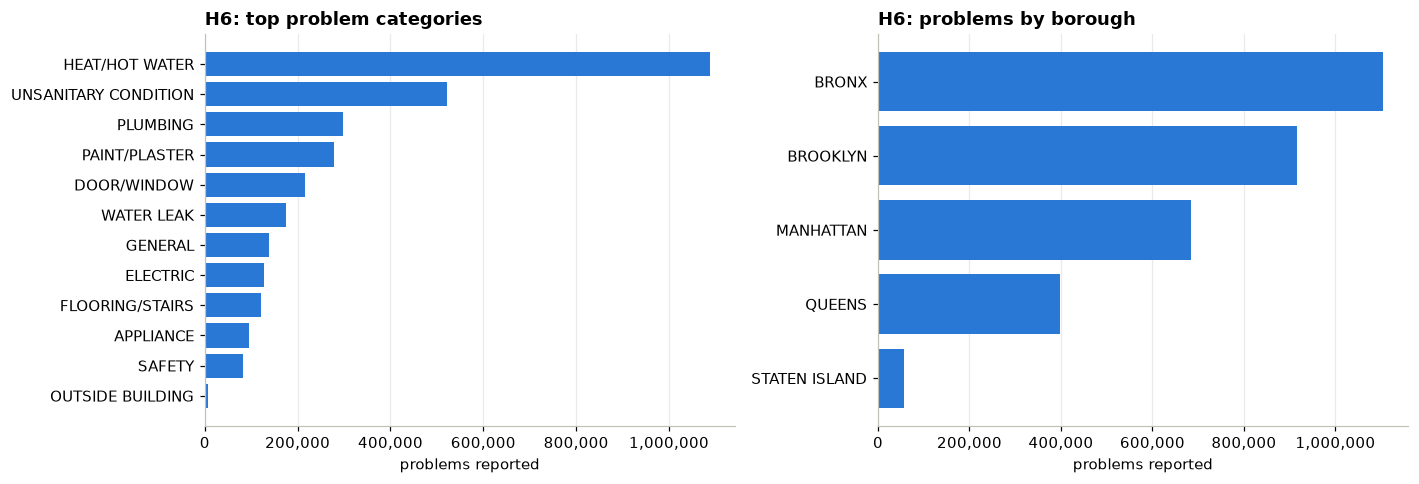

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_major = h6_raw['major_category'].value_counts().head(12).sort_values()
axes[0].barh(top_major.index.astype(str), top_major.values, color=COLOR_H6)
axes[0].set_title('H6: top problem categories'); axes[0].set_xlabel('problems reported')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}')); axes[0].grid(axis='y', visible=False)

boro = h6_raw['borough'].value_counts().sort_values()
axes[1].barh(boro.index.astype(str), boro.values, color=COLOR_H6)
axes[1].set_title('H6: problems by borough'); axes[1].set_xlabel('problems reported')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}')); axes[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### 5.4 Time pattern
We convert the date text to real dates **only for this plot** (the real conversion is a cleaning step later). We count problems per month with `resample('MS')` (MS = "month start").

What to look for: heat complaints should create **winter peaks** every year. If we see them, the dates are trustworthy. If we see sudden drops to zero, data could be missing for those months.

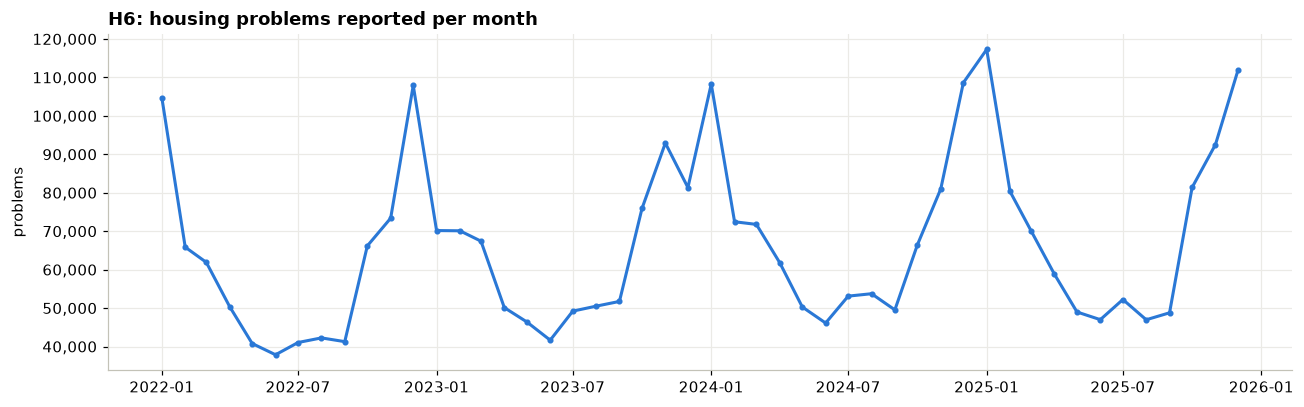

Date range: 2022-01-01 00:00:46 -> 2025-12-31 23:59:41 | unparseable dates: 0


In [15]:
h6_dates_preview = pd.to_datetime(h6_raw['received_date'], format='ISO8601', errors='coerce')
monthly = h6_dates_preview.dt.to_period('M').value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(monthly.index.to_timestamp(), monthly.values, color=COLOR_H6, marker='o', markersize=3)
style_ax(ax, 'H6: housing problems reported per month', ylabel='problems')
plt.tight_layout(); plt.show()
print('Date range:', h6_dates_preview.min(), '->', h6_dates_preview.max(), '| unparseable dates:', h6_dates_preview.isna().sum() - h6_raw['received_date'].isna().sum())

### 5.5 Geography checks
* `describe()` on latitude/longitude gives min/max. Anything outside NYC's box (≈ 40.5–40.9 N, 74.3–73.7 W) is an error.
* We check ZIP codes: valid NYC ZIPs have **5 digits** and start with **100–104** or **110–116**.
* We check how many rows have an NTA name.

In [16]:
lat = pd.to_numeric(h6_raw['latitude'], errors='coerce'); lon = pd.to_numeric(h6_raw['longitude'], errors='coerce')
display(pd.DataFrame({'latitude': lat.describe(), 'longitude': lon.describe()}).T)
outside = ((lat < NYC_BBOX['lat_min']) | (lat > NYC_BBOX['lat_max']) | (lon < NYC_BBOX['lon_min']) | (lon > NYC_BBOX['lon_max'])).sum()
zip_text = h6_raw['post_code'].dropna().astype(str).str.strip()
bad_zip = (~zip_text.str.fullmatch(r'1(0[0-4]|1[0-6])\d\d')).sum()
print(f'Coordinates outside NYC box: {outside:,}')
print(f'Invalid ZIP codes (filled but not a NYC ZIP): {bad_zip:,} | examples:', zip_text[~zip_text.str.fullmatch(r"1(0[0-4]|1[0-6])\d\d")].value_counts().head(8).to_dict())
print(f"Rows without NTA name: {h6_raw['nta'].isna().sum():,}  | distinct NTA names: {h6_raw['nta'].nunique()}")

,count,mean,std,min,25%,50%,75%,max
latitude,"3,159,723.00",40.76,0.09,40.50,40.68,40.79,40.84,40.91
longitude,"3,159,723.00",-73.92,0.06,-74.25,-73.95,-73.92,-73.89,-73.70


Coordinates outside NYC box: 0
Invalid ZIP codes (filled but not a NYC ZIP): 202 | examples: {'2016': 82, '3366': 39, '2018': 30, '10803': 12, '1901': 8, '2015': 7, '111010': 7, '2017': 4}
Rows without NTA name: 663  | distinct NTA names: 226


### 5.6 Duplicates
Three kinds of duplicates can exist:
1. **Exact duplicate rows** — every column identical → a copy error. `df.duplicated().sum()` counts them.
2. **Same `problem_id` twice** — the same problem appears in more than one row (e.g. two status updates).
3. **`problem_duplicate_flag = Y`** — HPD's own marker: *another tenant already reported this building-wide problem*. These are real reports from real people, so they are **not** copy errors (we decide what to do with them in Section 7).

In [17]:
print(f'Exact duplicate rows      : {h6_raw.duplicated().sum():,}')
print(f'Repeated problem_id       : {h6_raw["problem_id"].duplicated().sum():,}')
print(f'HPD duplicate-report flag : {(h6_raw["problem_duplicate_flag"] == "Y").sum():,}  ({(h6_raw["problem_duplicate_flag"] == "Y").mean():.1%})')
print(f'Problems per complaint    : {h6_raw.groupby("complaint_id").size().describe()[["mean", "50%", "max"]].round(2).to_dict()}')

Exact duplicate rows      : 0
Repeated problem_id       : 0


HPD duplicate-report flag : 502,470  (15.9%)


Problems per complaint    : {'mean': 1.64, '50%': 1.0, 'max': 72.0}


### 5.7 Time to close a complaint (looking for outliers)
We compute (temporarily) the number of days between `received_date` and `problem_status_date`. A **negative** value is impossible (closed before it was reported) and a **huge** value is suspicious. A box plot on a log scale shows the long tail.

count   3,160,313.00
mean           15.40
std            39.20
min          -364.50
25%             1.80
50%             4.10
75%            13.80
95%            75.80
99%           183.40
max         1,411.80
Negative durations: 6,363


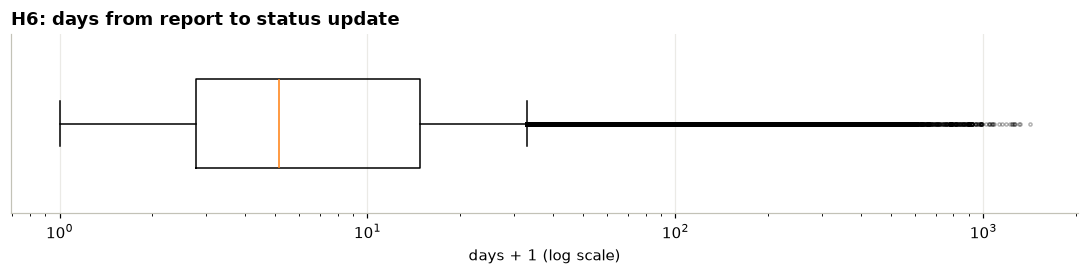

In [18]:
status_preview = pd.to_datetime(h6_raw['problem_status_date'], format='ISO8601', errors='coerce')
days_preview = (status_preview - h6_dates_preview).dt.total_seconds() / 86400
print(days_preview.describe(percentiles=[.25, .5, .75, .95, .99]).round(1).to_string())
print(f'Negative durations: {(days_preview < 0).sum():,}')
fig, ax = plt.subplots(figsize=(10, 2.6))
hbox(ax, days_preview.dropna().clip(lower=0) + 1)
ax.set_xscale('log'); ax.set_title('H6: days from report to status update'); ax.set_yticks([])
ax.set_xlabel('days + 1 (log scale)')
plt.tight_layout(); plt.show()

<a id="s6"></a>
## 6. EDA — T3 street construction permits

The same questions, applied to the street permits.

In [19]:
print('Shape (rows, columns):', t3_raw.shape)
display(t3_raw.dtypes.to_frame('dtype').T)
t3_raw.head(3)

Shape (rows, columns): (2577722, 20)


,permitnumber,applicationtypeshortdesc,permitstatusshortdesc,permitseriesshortdesc,permittypedesc,permitlinearfeet,permittotalsqfeet,permitestimatednumberofcuts,equipmenttypedesc,permitissuedate,issuedworkstartdate,issuedworkenddate,boroughname,onstreetname,fromstreetname,tostreetname,permitteename,permitpurposecomments,pavementshortdesc,wkt
dtype,str,category,category,category,category,float64,float64,float64,category,str,str,str,category,category,category,category,category,str,category,str


,permitnumber,applicationtypeshortdesc,permitstatusshortdesc,permitseriesshortdesc,permittypedesc,permitlinearfeet,permittotalsqfeet,permitestimatednumberofcuts,equipmenttypedesc,permitissuedate,issuedworkstartdate,issuedworkenddate,boroughname,onstreetname,fromstreetname,tostreetname,permitteename,permitpurposecomments,pavementshortdesc,wkt
0,B002022262A04,Renew,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,NaN,NaN,NaN,NaN,2022-09-19T15:35:50.000,NaN,NaN,BROOKLYN,NaN,NaN,NaN,"NORTHSTAR CONTRACTING GROUP, INC.",A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN
1,B002022276A00,Renew,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,NaN,NaN,NaN,NaN,2022-10-03T10:12:17.000,NaN,NaN,BROOKLYN,NaN,NaN,NaN,THE BROOKLYN UNION GAS COMPANY D/B/A NATIONAL ...,A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN
2,B002022300A14,New,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,NaN,NaN,NaN,NaN,2022-10-27T17:24:13.000,NaN,NaN,BROOKLYN,NaN,NaN,NaN,RALLY RESTORATION CORP.,A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN


In [20]:
t3_missing_before = missing_report(t3_raw)
t3_missing_before

,missing,missing_%,dtype,distinct_values
permittotalsqfeet,2314450,89.79,float64,1321
permitestimatednumberofcuts,2269112,88.03,float64,142
equipmenttypedesc,2142865,83.13,category,6513
permitlinearfeet,1535301,59.56,float64,993
pavementshortdesc,949680,36.84,category,5
permitpurposecomments,878403,34.08,str,190723
tostreetname,368253,14.29,category,8035
wkt,331886,12.88,str,109254
issuedworkstartdate,16488,0.64,str,767974
issuedworkenddate,16488,0.64,str,43583


### 6.1 Categories
The **series** is the big family of permit (street opening, building operation, sidewalk ...). The **type** is the exact job (repair gas, place equipment ...). The **application type** says if the permit is **New**, a **Renew**al of an older one, or an **Emergency**.

> 💡 Renewals matter: one long job can get a new permit number every month. If we count all permits, long jobs count many times. That is why we will also count **new jobs** only.

In [21]:
for col in ['permitseriesshortdesc', 'applicationtypeshortdesc', 'permitstatusshortdesc', 'boroughname', 'pavementshortdesc']:
    print(f'--- {col}  ({t3_raw[col].nunique()} distinct) ---')
    print(t3_raw[col].value_counts(dropna=False).head(15).to_string(), '\n')
print('Top 15 permit types:'); print(t3_raw['permittypedesc'].value_counts().head(15).to_string())
print('\nTop 10 permittees:'); print(t3_raw['permitteename'].value_counts().head(10).to_string())

--- permitseriesshortdesc  (11 distinct) ---
permitseriesshortdesc
BUILDING OPERATION PERMIT             1014610
STREET OPENING PERMIT                  882651
COMMERCIAL REFUSE CONTAINER PERMIT     236666
SIDEWALK CONSTRUCTION PERMIT           164000
DOT IN-HOUSE PAVING AND MILLING         99294
COMMERICAL REFUSE CONTAINER PERMIT      61215
MANHOLE EMBARGO PERMIT                  59904
PLACE EQUIPMENT - AUTOMATED SERIES      41979
MISCELLANEOUS CASH RECEIPTS             16459
CANOPY PERMIT                             915
VAULT LICENSE                              29 

--- applicationtypeshortdesc  (6 distinct) ---
applicationtypeshortdesc
New                  1284445
Renew                 979340
Reissue               180873
Emergency              71558
Amend and Reissue      41618
Extend                 19888 

--- permitstatusshortdesc  (15 distinct) ---
permitstatusshortdesc
EXPIRED                            1937142
EXPIRED UNDER GUARANTEE             463052
DELINQUENT CONFIRMATION 

In [22]:
# Text problems: leading/trailing spaces in street names and spelling variants in the series names
street_txt = t3_raw['onstreetname'].astype(str)
print('Street names with leading/trailing spaces:', int((street_txt != street_txt.str.strip()).sum()))
print('Street names with double spaces          :', int(street_txt.str.contains('  ', regex=False).sum()))
series_values = t3_raw['permitseriesshortdesc'].dropna().astype(str).unique()
print('Series names containing "COMMERICAL" (typo):', [v for v in series_values if 'COMMERICAL' in v])
print('Non-street values in from/to street:', t3_raw['fromstreetname'].astype(str).isin(['BEND', 'DEAD END']).sum())

Street names with leading/trailing spaces: 27533
Street names with double spaces          : 511259


Series names containing "COMMERICAL" (typo): ['COMMERICAL REFUSE CONTAINER PERMIT']


Non-street values in from/to street: 71435


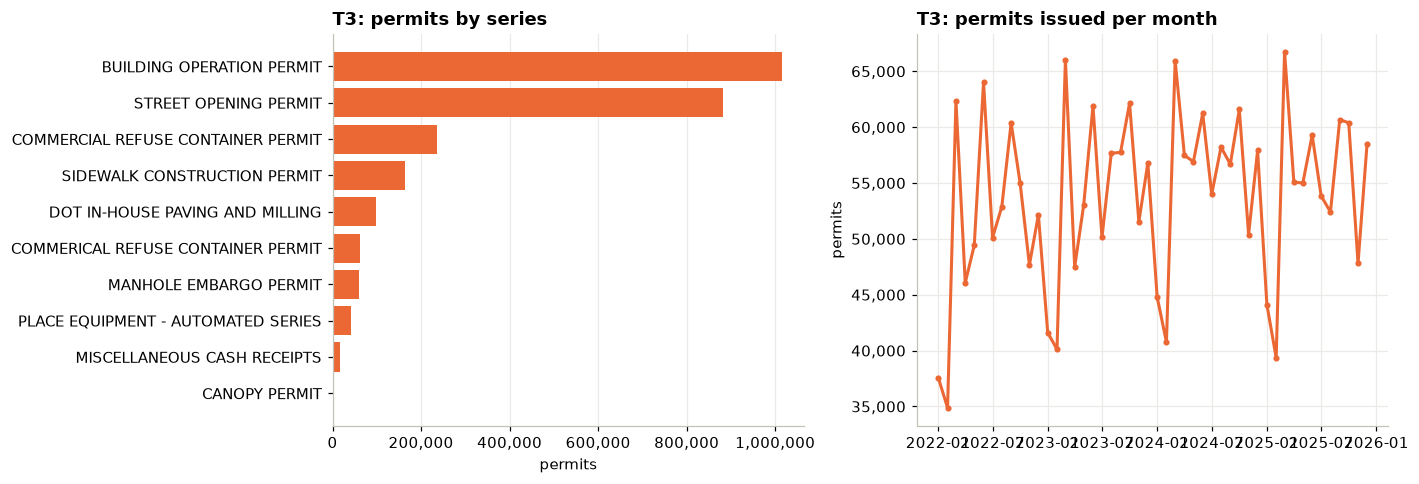

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
series_counts = t3_raw['permitseriesshortdesc'].value_counts().head(10).sort_values()
axes[0].barh(series_counts.index.astype(str), series_counts.values, color=COLOR_T3)
axes[0].set_title('T3: permits by series'); axes[0].set_xlabel('permits'); axes[0].grid(axis='y', visible=False)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
t3_dates_preview = pd.to_datetime(t3_raw['permitissuedate'], format='ISO8601', errors='coerce')
monthly_t3 = t3_dates_preview.dt.to_period('M').value_counts().sort_index()
axes[1].plot(monthly_t3.index.to_timestamp(), monthly_t3.values, color=COLOR_T3, marker='o', markersize=3)
style_ax(axes[1], 'T3: permits issued per month', ylabel='permits')
plt.tight_layout(); plt.show()

### 6.2 Numbers and dates: outliers and impossible values
* `describe()` on the size columns shows the extreme maximums.
* The **work window** = `issuedworkenddate − issuedworkstartdate`. Negative windows are impossible.

,count,mean,std,min,50%,95%,99%,max
permitlinearfeet,"1,042,421.00",226.94,604.78,1.00,75.00,750.00,"5,000.00","9,999.00"
permittotalsqfeet,"263,272.00","1,570.22","200,156.90",0.00,96.00,"5,000.00","10,000.00","102,595,914.00"
permitestimatednumberofcuts,"308,610.00",4.15,56.77,0.00,1.00,10.00,20.00,"9,680.00"


count   2,561,234.00
mean           43.00
std            31.80
min             0.00
50%            30.00
95%            90.00
99%            90.00
max           365.00
Negative work windows: 0   |   windows longer than 1 year: 0


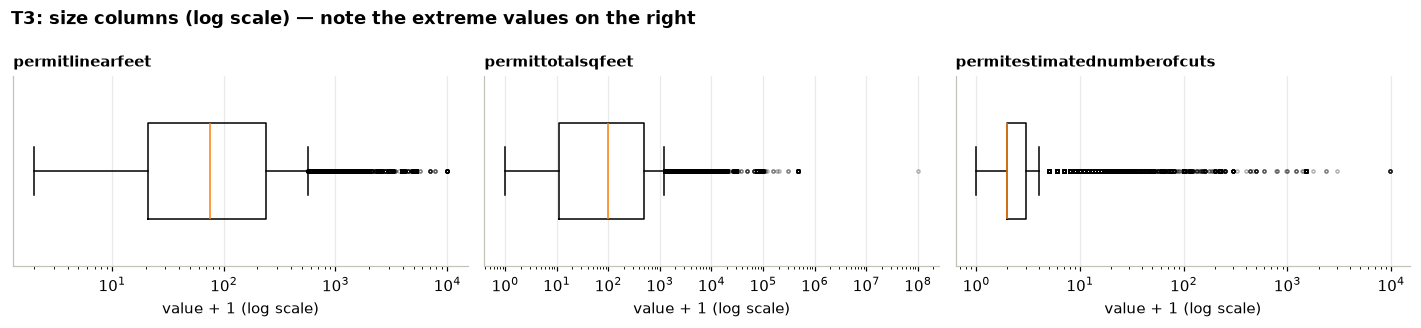

In [24]:
num_cols = ['permitlinearfeet', 'permittotalsqfeet', 'permitestimatednumberofcuts']
display(t3_raw[num_cols].apply(pd.to_numeric, errors='coerce').describe(percentiles=[.5, .95, .99]).T)
start_preview = pd.to_datetime(t3_raw['issuedworkstartdate'], format='ISO8601', errors='coerce')
end_preview = pd.to_datetime(t3_raw['issuedworkenddate'], format='ISO8601', errors='coerce')
window_days = (end_preview - start_preview).dt.total_seconds() / 86400
print(window_days.describe(percentiles=[.5, .95, .99]).round(1).to_string())
print(f'Negative work windows: {(window_days < 0).sum():,}   |   windows longer than 1 year: {(window_days > 366).sum():,}')

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, col in zip(axes, num_cols):
    v = pd.to_numeric(t3_raw[col], errors='coerce').dropna()
    hbox(ax, v + 1)
    ax.set_xscale('log'); ax.set_title(col, fontsize=10); ax.set_yticks([]); ax.set_xlabel('value + 1 (log scale)')
plt.suptitle('T3: size columns (log scale) — note the extreme values on the right', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 6.3 Geometry
`wkt` (**Well-Known Text**) is a standard way to write shapes as text, e.g. `POINT (1000 200000)` or `LINESTRING (x1 y1, x2 y2)`. The numbers are **feet** in the New York State Plane system (EPSG:2263), not latitude/longitude.

In [25]:
wkt_text = t3_raw['wkt'].dropna().astype(str).str.strip()
geom_kind = wkt_text.str.extract(r'^([A-Z]+)', expand=False).fillna('UNREADABLE').reindex(t3_raw.index).fillna('MISSING')
print(geom_kind.value_counts().to_string())
print('\nExample:', t3_raw['wkt'].dropna().iloc[0][:120])

wkt
LINESTRING         1918986
MISSING             331886
POINT               250273
MULTIPOINT           55721
MULTILINESTRING      20856

Example: LINESTRING (982111.09360000491 185060.7363999933, 982022.39640000463 184820.35959999263)


**T3 EDA summary — what we will fix in Section 8**

| Finding | Cleaning action |
|---|---|
| Dates are text | Convert to real dates |
| Spaces/case problems in street names, typo `COMMERICAL` | Standardize text, fix typo, merge variants |
| Voided permits | Remove (the permit never really existed) |
| Exact duplicates / repeated permit numbers | Remove |
| Impossible sizes (millions of cuts / sq ft), placeholder `9999` | Domain rules → missing, then cap remaining outliers with IQR |
| Negative or > 1 year work windows | Negative → missing (inconsistent), long → capped |
| Geometry in feet and ~22% missing | Convert to points + lat/long, find NTA by spatial join, fill missing NTAs from the same street segment |

<a id="s7"></a>
## 7. Pre-integration cleaning — H6

We already saved the "before" numbers we need (the missing-value report in 5.2 and the row/column counts). To save memory we now clean the downloaded table directly under the name `h6` — the untouched raw copy is still on disk in `data/raw/` if we ever need it again. Each step below has: **what we do**, **why**, and **which methods** we use.

> ⚠️ Because we clean in place, run Sections 7 → 13 **once, in order**. If you want to restart the cleaning, re-run from Section 3 (it reloads from the cache in seconds).

We also keep a **cleaning log** — a small table recording how many rows each step removed. It appears at the end of the section and proves no data disappeared silently.

In [26]:
cleaning_log = []

def log_step(dataset, step, rows_before, rows_after, note=''):
    # Record one cleaning step: how many rows went in, how many came out, and why.
    cleaning_log.append({'dataset': dataset, 'step': step, 'rows_before': rows_before,
                         'rows_after': rows_after, 'rows_removed': rows_before - rows_after, 'note': note})
    print(f'[{dataset}] {step}: {rows_before:,} -> {rows_after:,} rows  ({rows_before - rows_after:,} removed)  {note}')


def group_mode(df, keys, target, min_share=0.0, min_count=1):
    # For every group (e.g. every building), find the most common value of `target`
    # and how dominant it is (share). Used to repair missing values from "the same building/street".
    counts = (df.dropna(subset=[target])
                .groupby(keys + [target], observed=True).size().rename('n').reset_index())
    counts['total'] = counts.groupby(keys, observed=True)['n'].transform('sum')
    best = counts.sort_values('n', ascending=False).drop_duplicates(keys)
    best['share'] = best['n'] / best['total']
    best = best[(best['share'] >= min_share) & (best['total'] >= min_count)]
    best = best.astype({k: object for k in keys})
    return best.set_index(keys)[target]


def lookup_by_keys(rows, table, keys):
    # Look up each row's group in `table` (output of group_mode). Works for one or several key columns.
    if len(keys) == 1:
        table = table.copy(); table.index = table.index.astype(object)
        return rows[keys[0]].astype(object).map(table)
    wanted = pd.MultiIndex.from_frame(rows[keys].astype(object))
    return pd.Series(table.reindex(wanted).to_numpy(), index=rows.index)


def map_combinations(df, cols, func):
    # Apply func(a, b, ...) once per DISTINCT combination of `cols` and give every row its combination's result.
    # Much faster and lighter than a merge on millions of rows: ngroup() gives each row the number of its group.
    grouped = df.groupby(cols, observed=True, dropna=False, sort=True)
    keys = grouped.size().index                                   # one entry per combination, same order as ngroup
    results = np.array([func(*(k if isinstance(k, tuple) else (k,))) for k in keys], dtype=object)
    return pd.Series(results[grouped.ngroup().to_numpy()], index=df.index).astype('category')


H6_RAW_ROWS, H6_RAW_COLS = h6_raw.shape
h6 = h6_raw          # clean in place (no second copy in memory)
del h6_raw
print(f'Starting H6 cleaning with {len(h6):,} rows')

Starting H6 cleaning with 3,160,386 rows


### 7.1 Standardize column names
API column names are already `lowercase_with_underscores`, but we still run a `to_snake()` function so the code would also work with the CSV download (whose headers look like `Received Date`). We also rename three unclear columns:

| Old | New | Why |
|---|---|---|
| `type` | `problem_type` | `type` is vague and is also a Python built-in name |
| `post_code` | `zip_code` | the common US name; T3 has no ZIP, so no clash |
| `nta` | `nta_name_raw` | it holds a **name**; the clean **code** comes later |

In [27]:
def to_snake(name):
    # 'Received Date' -> 'received_date'
    return re.sub(r'[^0-9a-z]+', '_', str(name).strip().lower()).strip('_')

h6.columns = [to_snake(c) for c in h6.columns]
h6 = h6.rename(columns={'type': 'problem_type', 'post_code': 'zip_code', 'nta': 'nta_name_raw'})
print(list(h6.columns))

['received_date', 'problem_id', 'complaint_id', 'building_id', 'borough', 'house_number', 'street_name', 'zip_code', 'community_board', 'unit_type', 'space_type', 'problem_type', 'major_category', 'minor_category', 'problem_code', 'complaint_status', 'complaint_status_date', 'problem_status', 'problem_status_date', 'status_description', 'problem_duplicate_flag', 'complaint_anonymous_flag', 'latitude', 'longitude', 'bbl', 'nta_name_raw']


### 7.2 Standardize text + turn placeholders into real missing values
For every text column we: remove spaces at the start/end (`strip`), use UPPER CASE, collapse double spaces, and turn **placeholder words** into proper missing values (`NaN`).

*Why?* `"Brooklyn"`, `"BROOKLYN "` and `"BROOKLYN"` are the same borough, but Python sees three different values. And `"N/A"` looks like a real value, so `isna()` would not count it as missing.

*Extra placeholders for some columns:* `"0"` means "no value" for house numbers, street names and ZIP codes.

*Method:* `clean_text_column()` cleans each **distinct** value once (fast), see Section 2.

In [28]:
H6_TEXT_TO_CLEAN = ['borough', 'house_number', 'street_name', 'zip_code', 'community_board', 'unit_type',
                    'space_type', 'problem_type', 'major_category', 'minor_category', 'problem_code',
                    'complaint_status', 'problem_status', 'status_description', 'problem_duplicate_flag',
                    'complaint_anonymous_flag', 'bbl', 'nta_name_raw']
H6_EXTRA_PLACEHOLDERS = {'house_number': {'0'}, 'street_name': {'0'}, 'zip_code': {'0', '00000'}, 'bbl': {'0'}}

missing_before_text = h6[H6_TEXT_TO_CLEAN].isna().sum()
for col in H6_TEXT_TO_CLEAN:
    h6[col] = clean_text_column(h6[col], H6_EXTRA_PLACEHOLDERS.get(col, ()))
new_missing = (h6[H6_TEXT_TO_CLEAN].isna().sum() - missing_before_text)
print('Values that were placeholders and are now properly missing:')
print(new_missing[new_missing > 0].to_string() if (new_missing > 0).any() else '  none')

Values that were placeholders and are now properly missing:
zip_code      1
bbl         805


### 7.3 Harmonize category labels (inconsistent data)
Two kinds of inconsistency:

1. **Same meaning, different label** (decided by us, based on HPD's documentation and the values we saw):
   * `HEATING` (old system) = `HEAT/HOT WATER` (new system)
   * minor category `VERMIN` and `PESTS` → `PESTS/VERMIN`
   * unit type `BUILDING` = `BUILDING-WIDE`, `PUBLIC PARTS` = `PUBLIC AREA`
2. **Spelling variants** (found automatically by `merge_near_duplicates`): labels that become identical when we ignore punctuation and a final plural "S" (e.g. `DOOR` / `DOORS`). They are merged into the **most frequent** spelling. The cell prints every merge, so the team can check them.

In [29]:
H6_SEMANTIC_MAP = {
    'major_category': {'HEATING': 'HEAT/HOT WATER'},
    'minor_category': {'VERMIN': 'PESTS/VERMIN', 'PESTS': 'PESTS/VERMIN'},
    'unit_type': {'BUILDING': 'BUILDING-WIDE', 'PUBLIC PARTS': 'PUBLIC AREA'},
}
for col, mapping in H6_SEMANTIC_MAP.items():
    before_n = h6[col].nunique()
    h6[col] = map_categories(h6[col], lambda v, m=mapping: m.get(v, v))
    print(f'{col}: {before_n} -> {h6[col].nunique()} distinct values after semantic mapping')

for col in ['major_category', 'minor_category', 'problem_code', 'space_type', 'unit_type', 'problem_type']:
    h6[col] = merge_near_duplicates(h6[col], col)

major_category: 14 -> 14 distinct values after semantic mapping
minor_category: 60 -> 60 distinct values after semantic mapping
unit_type: 4 -> 3 distinct values after semantic mapping


  minor_category: merged 2 spelling variant(s): {'WINDOW/FRAME': 'WINDOW FRAME', 'DOOR/FRAME': 'DOOR FRAME'}


### 7.4 Convert data types (standardize formats)
| Column(s) | From | To | Method |
|---|---|---|---|
| `received_date`, `problem_status_date`, `complaint_status_date` | text `2024-03-01T00:00:53.000` | `datetime64` | `pd.to_datetime(..., format='ISO8601', errors='coerce')` — `coerce` turns impossible dates into `NaT` (missing) instead of crashing |
| `latitude`, `longitude` | text/number | `float` | `pd.to_numeric(..., errors='coerce')` |
| `problem_id`, `complaint_id`, `building_id` | number | `Int64` | nullable integer: whole numbers that may contain missing values |
| `community_board` | text | `Int16` | small integer |
| `problem_duplicate_flag` | `Y`/`N` | `is_duplicate_report` (True/False) | a comparison `== 'Y'` |

In [30]:
for col in ['received_date', 'problem_status_date', 'complaint_status_date']:
    filled_before = h6[col].notna().sum()
    h6[col] = pd.to_datetime(h6[col], format='ISO8601', errors='coerce')
    print(f'{col:<24} unparseable dates turned into NaT: {filled_before - h6[col].notna().sum():,}')

for col in ['latitude', 'longitude']:
    h6[col] = pd.to_numeric(h6[col], errors='coerce').astype('float64')
for col in ['problem_id', 'complaint_id', 'building_id']:
    h6[col] = pd.to_numeric(h6[col], errors='coerce').astype('Int64')
h6['community_board'] = pd.to_numeric(h6['community_board'].astype(object), errors='coerce').astype('Int16')

h6['is_duplicate_report'] = h6['problem_duplicate_flag'].astype(object).eq('Y')
h6 = h6.drop(columns='problem_duplicate_flag')
h6.dtypes.to_frame('dtype').T

received_date            unparseable dates turned into NaT: 0


problem_status_date      unparseable dates turned into NaT: 0


complaint_status_date    unparseable dates turned into NaT: 0


,received_date,problem_id,complaint_id,building_id,borough,house_number,street_name,zip_code,community_board,unit_type,space_type,problem_type,major_category,minor_category,problem_code,complaint_status,complaint_status_date,problem_status,problem_status_date,status_description,complaint_anonymous_flag,latitude,longitude,bbl,nta_name_raw,is_duplicate_report
dtype,datetime64[us],Int64,Int64,Int64,category,category,category,category,Int16,category,category,category,category,category,category,category,datetime64[us],category,datetime64[us],category,category,float64,float64,category,category,bool


### 7.5 Keep only rows inside the analysis window
The API filter already did this, but we **verify** it (good practice: never trust a filter you did not check). Rows with no `received_date` cannot be placed in a month, so they cannot be used.

In [31]:
rows_before = len(h6)
h6 = h6[h6['received_date'].between(WINDOW_START, WINDOW_END)]
log_step('H6', 'received_date inside window', rows_before, len(h6))

[H6] received_date inside window: 3,160,386 -> 3,160,386 rows  (0 removed)  


### 7.6 Validate geographic fields (domain rules)
| Field | Rule | If broken |
|---|---|---|
| `borough` | one of the 5 boroughs | → missing |
| `zip_code` | 5 digits, starts with 100–104 or 110–116 (all NYC ZIPs) | → missing |
| `latitude`/`longitude` | inside the NYC box | both → missing |
| `community_board` | 1 – 18 (the largest board number in any borough) | → missing |
| `bbl` | 10 digits; first digit = borough code (1 Manhattan, 2 Bronx, 3 Brooklyn, 4 Queens, 5 Staten Island) | → missing |

We also check **ZIP vs borough consistency** (e.g. a `104xx` ZIP should be in the Bronx). This is only **flagged**, not fixed, because a few real ZIPs cross borough lines (e.g. Marble Hill is in Manhattan but has a Bronx ZIP).

In [32]:
BOROUGH_CODE = {'MANHATTAN': '1', 'BRONX': '2', 'BROOKLYN': '3', 'QUEENS': '4', 'STATEN ISLAND': '5'}

def borough_from_zip(z):
    if not isinstance(z, str):
        return None
    p = z[:3]
    if p in ('100', '101', '102'): return 'MANHATTAN'
    if p == '103': return 'STATEN ISLAND'
    if p == '104': return 'BRONX'
    if p == '112': return 'BROOKLYN'
    if p in ('110', '111', '113', '114', '116'): return 'QUEENS'
    return None

checks = {}
bad = ~h6['borough'].isin(BOROUGHS) & h6['borough'].notna()
checks['invalid borough'] = int(bad.sum()); h6['borough'] = h6['borough'].mask(bad)

zip_ok = h6['zip_code'].astype(object).str.fullmatch(r'1(0[0-4]|1[0-6])\d\d').fillna(False).astype(bool)
bad = h6['zip_code'].notna() & ~zip_ok
checks['invalid ZIP'] = int(bad.sum()); h6['zip_code'] = h6['zip_code'].mask(bad)

outside = ~(h6['latitude'].between(NYC_BBOX['lat_min'], NYC_BBOX['lat_max']) &
            h6['longitude'].between(NYC_BBOX['lon_min'], NYC_BBOX['lon_max']))
bad = outside & (h6['latitude'].notna() | h6['longitude'].notna())
checks['coordinates outside NYC'] = int(bad.sum())
h6.loc[bad | outside, ['latitude', 'longitude']] = np.nan

bad = h6['community_board'].notna() & ~h6['community_board'].between(1, 18)
checks['invalid community board'] = int(bad.sum()); h6['community_board'] = h6['community_board'].mask(bad)

bbl_text = h6['bbl'].astype(object)
bbl_ok = bbl_text.str.fullmatch(r'[1-5]\d{9}').fillna(False).astype(bool)
bbl_matches_boro = bbl_text.str[0] == h6['borough'].astype(object).map(BOROUGH_CODE)
bad = h6['bbl'].notna() & ~(bbl_ok & bbl_matches_boro.fillna(False).astype(bool))
checks['invalid BBL'] = int(bad.sum()); h6['bbl'] = h6['bbl'].mask(bad)

zip_boro = h6['zip_code'].astype(object).map(borough_from_zip)
h6['zip_borough_mismatch'] = zip_boro.notna() & h6['borough'].notna() & (zip_boro != h6['borough'].astype(object))
checks['ZIP/borough mismatch (flagged only)'] = int(h6['zip_borough_mismatch'].sum())
pd.Series(checks, name='rows affected').to_frame()

,rows affected
invalid borough,0
invalid ZIP,201
coordinates outside NYC,0
invalid community board,578
invalid BBL,72
ZIP/borough mismatch (flagged only),6194


### 7.7 Remove duplicates
1. `drop_duplicates()` removes rows where **every** column is identical.
2. For a repeated `problem_id` we keep the row with the **latest status date** (`sort_values` then `drop_duplicates(keep='last')`), because it has the most recent information.
3. HPD duplicate reports (`is_duplicate_report = True`) are **kept**. They are different tenants reporting the same building-wide problem — real signal about how strongly people feel a problem. Later we count both **all reports** and **unique problems**, so the team can choose.

In [33]:
rows_before = len(h6)
h6 = h6.drop_duplicates()
log_step('H6', 'exact duplicate rows', rows_before, len(h6))

rows_before = len(h6)
h6 = (h6.sort_values(['problem_id', 'problem_status_date'], na_position='first')
        .drop_duplicates(subset='problem_id', keep='last'))
log_step('H6', 'repeated problem_id (kept latest status)', rows_before, len(h6))
print(f"HPD duplicate reports kept and flagged: {h6['is_duplicate_report'].sum():,} ({h6['is_duplicate_report'].mean():.1%})")

[H6] exact duplicate rows: 3,160,386 -> 3,160,386 rows  (0 removed)  


[H6] repeated problem_id (kept latest status): 3,160,386 -> 3,160,386 rows  (0 removed)  
HPD duplicate reports kept and flagged: 502,470 (15.9%)


### 7.8 Missing values — decide column by column (drop vs impute)

**Key idea:** a building never moves. If one complaint from building #12345 has the ZIP code and another complaint from the same building does not, we can copy it. That is not a guess — it is the same physical place. This is **group-based imputation** (fill from the same group).

| Column | Decision | Why |
|---|---|---|
| `zip_code` | fill from the same `building_id` (most common value) | same building = same ZIP |
| `latitude`, `longitude` | fill from the same `building_id` (median) | same building = same location |
| `nta_name_raw` | fill from the same `building_id`, then by name → code, then from coordinates (7.9); rows still without a neighborhood are **dropped** | NTA is our join key; a row with no neighborhood cannot be integrated |
| `complaint_anonymous_flag` | missing → `UNKNOWN` (a new category) | missing here means "not recorded"; choosing Y or N would invent information |
| `problem_status_date` | keep missing | for open problems the date does not exist yet — it is not an error |
| `street_name`, `house_number`, `bbl`, `community_board` | keep missing | not needed for the neighborhood join; used only by some analyses |
| `problem_code`, `minor_category` | keep missing | the problem group (7.11) can still be found from the other category columns |

We do **not** fill with a global average/mode: e.g. giving every missing ZIP the most common NYC ZIP would put complaints in the wrong place.

In [34]:
fill_report = {}
# ZIP code: most common ZIP of the same building
table = group_mode(h6, ['building_id'], 'zip_code')
need = h6['zip_code'].isna() & h6['building_id'].notna()
values = lookup_by_keys(h6.loc[need], table, ['building_id'])
h6['zip_code'] = h6['zip_code'].astype(object)
h6.loc[values.dropna().index, 'zip_code'] = values.dropna()
h6['zip_code'] = h6['zip_code'].astype('category')
fill_report['zip_code (from same building)'] = int(values.notna().sum())

# Coordinates: median coordinates of the same building
coords = h6.dropna(subset=['latitude', 'longitude']).groupby('building_id')[['latitude', 'longitude']].median()
need = h6['latitude'].isna() & h6['building_id'].isin(coords.index)
h6.loc[need, 'latitude'] = h6.loc[need, 'building_id'].map(coords['latitude']).astype(float)
h6.loc[need, 'longitude'] = h6.loc[need, 'building_id'].map(coords['longitude']).astype(float)
fill_report['latitude/longitude (from same building)'] = int(need.sum())

# NTA name: most common NTA of the same building
table = group_mode(h6, ['building_id'], 'nta_name_raw')
need = h6['nta_name_raw'].isna() & h6['building_id'].notna()
values = lookup_by_keys(h6.loc[need], table, ['building_id'])
h6['nta_name_raw'] = h6['nta_name_raw'].astype(object)
h6.loc[values.dropna().index, 'nta_name_raw'] = values.dropna()
h6['nta_name_raw'] = h6['nta_name_raw'].astype('category')
fill_report['nta_name_raw (from same building)'] = int(values.notna().sum())

# Anonymous flag: missing -> explicit UNKNOWN category
h6['complaint_anonymous_flag'] = (h6['complaint_anonymous_flag'].astype(object)
                                  .fillna('UNKNOWN').astype('category'))
fill_report['complaint_anonymous_flag (-> UNKNOWN)'] = int((h6['complaint_anonymous_flag'] == 'UNKNOWN').sum())
pd.Series(fill_report, name='values filled').to_frame()

,values filled
zip_code (from same building),2505
latitude/longitude (from same building),264
nta_name_raw (from same building),264
complaint_anonymous_flag (-> UNKNOWN),0


### 7.9 Standardize the neighborhood (NTA) — the integration key
1. **Name → code.** We match H6's NTA *name* to the official NTA list. Names are normalized first (upper case, no spaces around `-`) so tiny spelling differences do not break the match. Using the **code** (`BX0601`) instead of the name avoids problems with names that look alike.
2. **Coordinates as a backup.** If the name is missing or unknown but the row has coordinates, we use a **spatial join**: we turn each latitude/longitude into a point (`gpd.points_from_xy`) and ask which NTA polygon contains it (`gpd.sjoin(..., predicate='within')`).
3. **Quality check.** For a sample of rows that have **both** a name and coordinates, we compare the two answers. A high agreement means HPD's names are reliable.
4. **Borough consistency.** The first two letters of the NTA code give the borough (`BX` = Bronx). If they disagree with the `borough` column, one of the two is wrong and we cannot know which → we drop those (very few) rows.
5. Rows that still have **no NTA** cannot be integrated → dropped (logged).

In [35]:
def nta_key(v):
    return re.sub(r'\s*-\s*', '-', v) if isinstance(v, str) else None

name_to_code = dict(zip(nta['nta_name_key'], nta['nta_code']))
h6_name_key = map_categories(h6['nta_name_raw'], nta_key)
h6['nta_code'] = h6_name_key.astype(object).map(name_to_code)
h6['nta_source'] = np.where(h6['nta_code'].notna(), 'HPD_NAME', None)

unmatched = h6.loc[h6['nta_code'].isna() & h6['nta_name_raw'].notna(), 'nta_name_raw'].value_counts()
unmatched = unmatched[unmatched > 0]
print(f'Distinct H6 NTA names: {h6["nta_name_raw"].nunique()} | matched to official list: {h6_name_key.dropna().isin(name_to_code.keys()).mean():.2%} of rows with a name')
print('Names not found in the official list:', unmatched.head(10).to_dict() if len(unmatched) else 'none')


def points_to_nta(lon, lat, index, nearest_ft=None):
    # Spatial join: which NTA polygon contains each point? Optional nearest-NTA fallback within `nearest_ft` feet.
    pts = gpd.GeoDataFrame(index=index, geometry=gpd.points_from_xy(lon, lat), crs=CRS_LATLON).to_crs(CRS_FEET)
    joined = gpd.sjoin(pts, nta[['nta_code', 'geometry']], how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]          # a point on a border can touch 2 polygons
    result = joined['nta_code']
    if nearest_ft:
        missing = result.isna()
        if missing.any():
            near = gpd.sjoin_nearest(pts.loc[missing[missing].index], nta[['nta_code', 'geometry']],
                                     how='left', max_distance=nearest_ft)
            near = near[~near.index.duplicated(keep='first')]
            result = result.astype(object)
            result.loc[near.index] = near['nta_code']
    return result


# Backup: coordinates for rows without a matched name
need = h6['nta_code'].isna() & h6['latitude'].notna()
if need.any():
    found = points_to_nta(h6.loc[need, 'longitude'], h6.loc[need, 'latitude'], h6.index[need])
    h6.loc[found.dropna().index, 'nta_code'] = found.dropna()
    h6.loc[found.dropna().index, 'nta_source'] = 'COORDINATES'
print(h6['nta_source'].value_counts(dropna=False).to_string())

# Quality check on a sample: does HPD's name agree with the coordinates?
candidates = h6[(h6['nta_source'] == 'HPD_NAME') & h6['latitude'].notna()]
sample = candidates.sample(n=min(200_000, len(candidates)), random_state=42)   # 200k rows are enough for a reliable %
if len(sample):
    spatial = points_to_nta(sample['longitude'], sample['latitude'], sample.index)
    print(f'\nAgreement between HPD NTA name and coordinates (sample of {len(sample):,}): {(spatial == sample["nta_code"]).mean():.2%}')

Distinct H6 NTA names: 226 | matched to official list: 100.00% of rows with a name
Names not found in the official list: none
nta_source
HPD_NAME    3159987
NaN             399



Agreement between HPD NTA name and coordinates (sample of 200,000): 99.93%


In [36]:
# Borough consistency + drop rows with no neighborhood
h6['nta_borough'] = h6['nta_code'].astype(object).str[:2].map(NTA_PREFIX_TO_BOROUGH)
rows_before = len(h6)
conflict = h6['nta_borough'].notna() & h6['borough'].notna() & (h6['nta_borough'] != h6['borough'].astype(object))
h6 = h6[~conflict]
log_step('H6', 'borough conflicts with NTA borough', rows_before, len(h6))

rows_before = len(h6)
h6 = h6[h6['nta_code'].notna()]
log_step('H6', 'no neighborhood (NTA) could be found', rows_before, len(h6))

h6['borough'] = h6['nta_borough'].astype('category')          # borough now always agrees with the NTA
h6['nta_code'] = h6['nta_code'].astype('category')
h6['nta_source'] = h6['nta_source'].astype('category')
h6['nta_name'] = h6['nta_code'].astype(object).map(dict(zip(nta['nta_code'], nta['nta_name']))).astype('category')
h6 = h6.drop(columns=['nta_borough'])

[H6] borough conflicts with NTA borough: 3,160,386 -> 3,154,092 rows  (6,294 removed)  


[H6] no neighborhood (NTA) could be found: 3,154,092 -> 3,153,693 rows  (399 removed)  


### 7.10 Outliers — time to close a problem
We create `days_to_close = problem_status_date − received_date` (in days).

1. **Domain rules first** (things that are impossible): a negative value (closed before reported) or a status date in the future → set to missing. Problems that are still **open** have no closing time → missing.
2. **IQR rule on the log scale.** Durations are very right-skewed (most problems close in days, a few take years). The normal IQR rule would call thousands of normal values "outliers", so we apply it to `log(1 + days)`. Values above the upper fence are outliers.
3. **Cap, don't delete.** The complaint itself is real — only its duration is extreme. Deleting the row would also delete a real complaint from our counts. So we keep the row, flag it (`days_to_close_outlier`), and create a **capped** version (`days_to_close_capped`, values above the fence are set to the fence). This is called **winsorizing**.

We also look at buildings with an extreme number of problems. These are usually very large buildings (e.g. public housing complexes) — real, so we keep them.

Impossible durations set to missing: 6,359 | open problems (no closing time yet): 2,168
IQR (log scale) upper fence: 180.9 days  ->  32,677 outliers (1.04%) capped


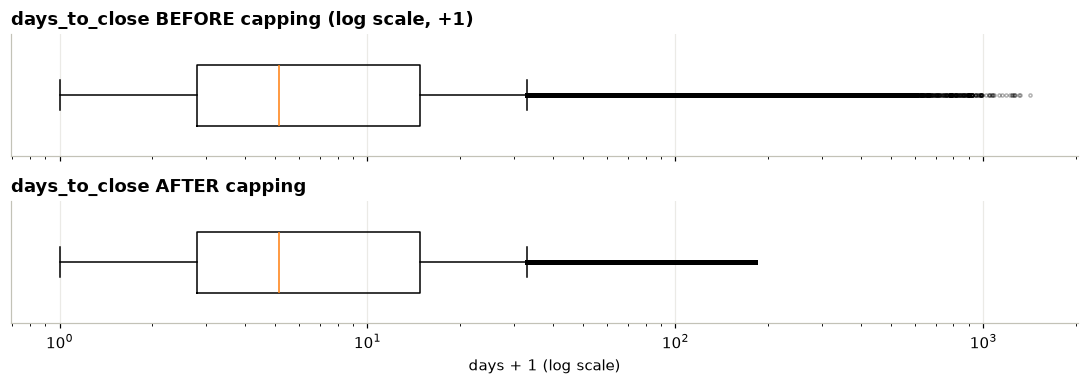

Buildings with an extreme number of problems (> 420): 896 — kept (large real buildings)


In [37]:
h6['days_to_close'] = (h6['problem_status_date'] - h6['received_date']).dt.total_seconds() / 86400
invalid = (h6['days_to_close'] < 0) | (h6['problem_status_date'] > pd.Timestamp.now())
not_closed = h6['problem_status'].astype(object) != 'CLOSE'
print(f'Impossible durations set to missing: {invalid.sum():,} | open problems (no closing time yet): {not_closed.sum():,}')
h6.loc[invalid | not_closed, 'days_to_close'] = np.nan

low, high = iqr_bounds(h6['days_to_close'], log=True)
h6['days_to_close_outlier'] = h6['days_to_close'] > high
h6['days_to_close_capped'] = h6['days_to_close'].clip(upper=high)
print(f'IQR (log scale) upper fence: {high:,.1f} days  ->  {h6["days_to_close_outlier"].sum():,} outliers ({h6["days_to_close_outlier"].mean():.2%}) capped')

fig, axes = plt.subplots(2, 1, figsize=(10, 3.6), sharex=True)
hbox(axes[0], h6['days_to_close'].dropna() + 1)
axes[0].set_title('days_to_close BEFORE capping (log scale, +1)'); axes[0].set_yticks([])
hbox(axes[1], h6['days_to_close_capped'].dropna() + 1)
axes[1].set_title('days_to_close AFTER capping'); axes[1].set_yticks([]); axes[1].set_xscale('log')
axes[1].set_xlabel('days + 1 (log scale)')
plt.tight_layout(); plt.show()

per_building = h6.groupby('building_id').size()
_, b_high = iqr_bounds(per_building, log=True)
print(f'Buildings with an extreme number of problems (> {b_high:,.0f}): {(per_building > b_high).sum():,} — kept (large real buildings)')

### 7.11 Feature engineering at row level
New columns that make the questions easier:

| Feature | How | Why it helps |
|---|---|---|
| `year`, `month`, `year_month`, `day_of_week`, `is_weekend`, `season` | from `received_date` | time grouping; `year_month` is half of the join key |
| `is_heat_season` | Oct 1 – May 31 = NYC legal heat season | heat complaints only make sense in this period |
| `is_emergency` | `problem_type` is EMERGENCY or IMMEDIATE EMERGENCY | severity |
| `problem_group` | combines major/minor category and problem code into 8 easy groups: HEAT_HOT_WATER, PESTS, MOLD, GAS, WATER_PLUMBING, ELECTRIC, STRUCTURE, OTHER | the raw codes have hundreds of values; groups are easy to compare with street-work types |
| `inspection_outcome` | reads the long `status_description` text and keeps the result: VIOLATION_ISSUED, NO_VIOLATION, NO_ACCESS, CORRECTED, OPEN, OTHER | the 300-character text becomes one useful word |
| `is_open` | `problem_status == 'OPEN'` | |
| `street_key` | `normalize_street(street_name)` | lets us match streets with T3 |

The group rules are checked **in order** (first match wins). Word boundaries (`\b`) stop false matches such as finding "RAT" inside "GENERATOR".

In [38]:
h6 = add_calendar_features(h6, 'received_date')
h6['is_emergency'] = h6['problem_type'].astype(object).isin(['EMERGENCY', 'IMMEDIATE EMERGENCY'])
h6['is_open'] = h6['problem_status'].astype(object).eq('OPEN')

GROUP_RULES = [   # (group, regex on "major | minor | code") - checked in this order
    ('HEAT_HOT_WATER', r'HEAT|HOT WATER|BOILER|RADIATOR'),
    ('PESTS',          r'\bMICE\b|\bMOUSE\b|\bRATS?\b|ROACH|PEST|VERMIN|BED ?BUG|INSECT|\bFLIES\b'),
    ('MOLD',           r'\bMOLD'),
    ('GAS',            r'\bGAS\b'),
    ('WATER_PLUMBING', r'WATER|LEAK|PLUMB|TOILET|SINK|BASIN|BATHTUB|SHOWER|DRAIN|SEWAGE'),
    ('ELECTRIC',       r'ELECTRIC|WIRING|OUTLET|LIGHT|APPLIANCE|POWER'),
    ('STRUCTURE',      r'PAINT|PLASTER|DOOR|WINDOW|FLOOR|STAIR|CEILING|WALL|ELEVATOR|OUTSIDE BUILDING|CONSTRUCTION|LINE OF TRAVEL'),
]

def assign_problem_group(major, minor, code):
    text = ' | '.join(str(x) for x in (major, minor, code) if isinstance(x, str))
    for group, pattern in GROUP_RULES:
        if re.search(pattern, text):
            return group
    return 'OTHER'

h6['problem_group'] = map_combinations(h6, ['major_category', 'minor_category', 'problem_code'], assign_problem_group)


def classify_outcome(text):
    if not isinstance(text, str):
        return 'UNKNOWN'
    if 'STILL OPEN' in text:
        return 'OPEN'
    if re.search(r'(?<!NO )VIOLATIONS? (WERE|WAS) (PREVIOUSLY )?ISSUED', text) or 'FAILURE WAS ISSUED' in text:
        return 'VIOLATION_ISSUED'
    if 'NOT ABLE TO GAIN ACCESS' in text or 'UNABLE TO ACCESS' in text:
        return 'NO_ACCESS'
    if 'NO VIOLATIONS' in text or 'NOT REQUIRED' in text:
        return 'NO_VIOLATION'
    if 'CORRECTED' in text or 'RESTORED' in text:
        return 'CORRECTED'
    return 'OTHER'

h6['inspection_outcome'] = map_categories(h6['status_description'], classify_outcome)
h6['inspection_outcome'] = h6['inspection_outcome'].astype(object).fillna('UNKNOWN').astype('category')
h6['street_key'] = map_categories(h6['street_name'], normalize_street)

display(h6['problem_group'].value_counts().to_frame('problems'))
display(pd.crosstab(h6['problem_group'], h6['inspection_outcome'], normalize='index').round(3))

C:\Users\ziadk\AppData\Local\Temp\ipykernel_33888\3766880167.py:126: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['is_weekend'] = d.dt.dayofweek >= 5


,problems
problem_group,
HEAT_HOT_WATER,1144392
STRUCTURE,658655
WATER_PLUMBING,432724
PESTS,281346
OTHER,239761
ELECTRIC,166968
MOLD,149302
GAS,80545


inspection_outcome,CORRECTED,NO_ACCESS,NO_VIOLATION,OPEN,OTHER,UNKNOWN,VIOLATION_ISSUED
problem_group,,,,,,,
ELECTRIC,0.06,0.16,0.39,0.00,0.19,0.00,0.20
GAS,0.16,0.19,0.34,0.01,0.17,0.00,0.13
HEAT_HOT_WATER,0.68,0.15,0.08,0.00,0.04,0.00,0.06
MOLD,0.02,0.08,0.46,0.00,0.17,0.00,0.27
OTHER,0.06,0.15,0.38,0.00,0.19,0.00,0.22
PESTS,0.02,0.22,0.27,0.00,0.13,0.00,0.35
STRUCTURE,0.02,0.15,0.38,0.00,0.14,0.00,0.31
WATER_PLUMBING,0.09,0.18,0.35,0.00,0.14,0.00,0.24


### 7.12 Final H6 table: choose columns, check, compare
* We drop columns that were replaced by better ones (`status_description` → `inspection_outcome`, `nta_name_raw` → `nta_code`/`nta_name`) and the complaint-level status columns (our row is a problem, so we use the problem-level status).
* **Assertions** (`assert`) are automatic tests: if any of them fails, the notebook stops and tells us something is wrong.

H6 clean: 3,153,693 rows x 41 columns | kept 99.79% of downloaded rows | memory 0.41 GB


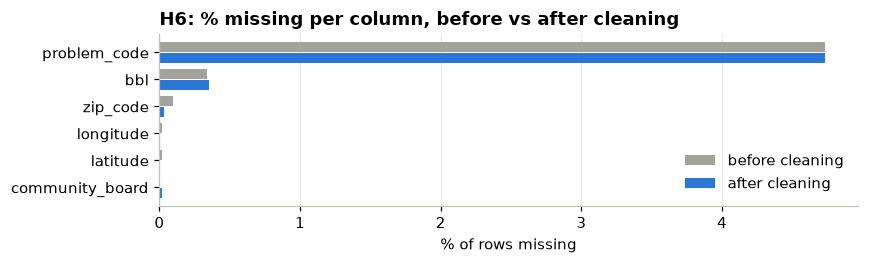

,problem_id,complaint_id,building_id,received_date,problem_status_date,problem_status,is_open,borough,nta_code,nta_name,nta_source,zip_code,zip_borough_mismatch,community_board,bbl,house_number,street_name,street_key,latitude,longitude,unit_type,space_type,problem_type,is_emergency,major_category,minor_category,problem_code,problem_group,inspection_outcome,is_duplicate_report,complaint_anonymous_flag,days_to_close,days_to_close_capped,days_to_close_outlier,year,month,year_month,day_of_week,is_weekend,season,is_heat_season
0,22189264,11002978,72471,2022-12-26 00:03:57,2022-12-28 21:34:12,CLOSE,False,BRONX,BX1203,Wakefield-Woodlawn,HPD_NAME,10466,False,12,2050010046,805,EAST 235 STREET,EAST 235 STREET,40.89,-73.85,APARTMENT,ENTIRE APARTMENT,EMERGENCY,True,HEAT/HOT WATER,APARTMENT ONLY,NO HEAT AND NO HOT WATER,HEAT_HOT_WATER,NO_ACCESS,False,N,2.90,2.90,False,2022,12,2022-12-01,Monday,False,WINTER,True
1,22189265,11002979,628605,2022-12-26 00:02:18,2022-01-02 17:47:34,CLOSE,False,QUEENS,QN0707,Flushing-Willets Point,HPD_NAME,11355,False,7,4051820044,140-37,ASH AVENUE,ASH AVENUE,40.76,-73.82,APARTMENT,KITCHEN,NON EMERGENCY,False,APPLIANCE,ELECTRIC/GAS RANGE,PILOT LIGHT OUT,GAS,NO_VIOLATION,False,N,NaN,NaN,False,2022,12,2022-12-01,Monday,False,WINTER,True
2,22189266,11002979,628605,2022-12-26 00:02:18,2022-01-02 17:47:34,CLOSE,False,QUEENS,QN0707,Flushing-Willets Point,HPD_NAME,11355,False,7,4051820044,140-37,ASH AVENUE,ASH AVENUE,40.76,-73.82,APARTMENT,ENTIRE APARTMENT,EMERGENCY,True,SAFETY,WINDOW GUARD BROKEN/MISSING,CHILD UNDER 11,STRUCTURE,NO_VIOLATION,False,N,NaN,NaN,False,2022,12,2022-12-01,Monday,False,WINTER,True


In [39]:
H6_FINAL_COLUMNS = [
    'problem_id', 'complaint_id', 'building_id', 'received_date', 'problem_status_date', 'problem_status', 'is_open',
    'borough', 'nta_code', 'nta_name', 'nta_source', 'zip_code', 'zip_borough_mismatch', 'community_board', 'bbl',
    'house_number', 'street_name', 'street_key', 'latitude', 'longitude',
    'unit_type', 'space_type', 'problem_type', 'is_emergency', 'major_category', 'minor_category', 'problem_code',
    'problem_group', 'inspection_outcome', 'is_duplicate_report', 'complaint_anonymous_flag',
    'days_to_close', 'days_to_close_capped', 'days_to_close_outlier',
    'year', 'month', 'year_month', 'day_of_week', 'is_weekend', 'season', 'is_heat_season']
h6 = h6[H6_FINAL_COLUMNS].reset_index(drop=True)

# ---- automatic checks ----
assert h6['problem_id'].is_unique, 'problem_id must be unique'
assert h6['nta_code'].notna().all(), 'every row needs a neighborhood'
assert h6['received_date'].between(WINDOW_START, WINDOW_END).all(), 'dates must be inside the window'
assert h6['borough'].isin(BOROUGHS).all()
assert (h6['days_to_close'].dropna() >= 0).all()
assert h6['latitude'].dropna().between(NYC_BBOX['lat_min'], NYC_BBOX['lat_max']).all()

h6_missing_after = missing_report(h6)
print(f'H6 clean: {len(h6):,} rows x {h6.shape[1]} columns | kept {len(h6) / H6_RAW_ROWS:.2%} of downloaded rows '
      f'| memory {h6.memory_usage(deep=True).sum() / 1e9:,.2f} GB')
plot_missing_before_after(h6_missing_before.rename(index={'post_code': 'zip_code', 'type': 'problem_type'}),
                          h6_missing_after, 'H6: % missing per column, before vs after cleaning')
h6.head(3)

<a id="s8"></a>
## 8. Pre-integration cleaning — T3

Same ideas as H6, plus one new job: turning the geometry into a **neighborhood**.

### 8.1 Standardize column names
The API names are long glued words (`permitseriesshortdesc`). We rename them to short, readable snake_case names:

In [40]:
T3_RENAME = {'permitnumber': 'permit_number', 'applicationtypeshortdesc': 'application_type',
             'permitstatusshortdesc': 'permit_status', 'permitseriesshortdesc': 'permit_series',
             'permittypedesc': 'permit_type', 'permitlinearfeet': 'linear_feet', 'permittotalsqfeet': 'total_sqft',
             'permitestimatednumberofcuts': 'estimated_cuts', 'equipmenttypedesc': 'equipment_type',
             'permitissuedate': 'issue_date', 'issuedworkstartdate': 'work_start_date',
             'issuedworkenddate': 'work_end_date', 'boroughname': 'borough', 'onstreetname': 'on_street',
             'fromstreetname': 'from_street', 'tostreetname': 'to_street', 'permitteename': 'permittee',
             'permitpurposecomments': 'purpose_comments', 'pavementshortdesc': 'pavement_type', 'wkt': 'wkt'}
T3_RAW_ROWS, T3_RAW_COLS = t3_raw.shape
t3_raw_sizes = t3_raw[['permitlinearfeet', 'permittotalsqfeet', 'permitestimatednumberofcuts']].apply(pd.to_numeric, errors='coerce')
t3 = t3_raw          # clean in place (keep only the 3 raw size columns for the before/after box plots)
del t3_raw
t3.columns = [to_snake(c) for c in t3.columns]
t3 = t3.rename(columns=T3_RENAME)
print(list(t3.columns))

['permit_number', 'application_type', 'permit_status', 'permit_series', 'permit_type', 'linear_feet', 'total_sqft', 'estimated_cuts', 'equipment_type', 'issue_date', 'work_start_date', 'work_end_date', 'borough', 'on_street', 'from_street', 'to_street', 'permittee', 'purpose_comments', 'pavement_type', 'wkt']


### 8.2 Standardize text, fix typos, merge spelling variants
* Same cleaning as H6: trim, UPPER CASE, single spaces, placeholders → missing (this also removes the **leading spaces** in street names like `" 100 AVENUE"`).
* **Typo fix:** `COMMERICAL` → `COMMERCIAL` (found in EDA, two versions of the same permit series).
* **HTML leftovers:** some text contains `&amp;` instead of `&` (from the web form) → fixed.
* Spelling variants are merged automatically as before, and printed for checking.

In [41]:
T3_TEXT_TO_CLEAN = ['application_type', 'permit_status', 'permit_series', 'permit_type', 'equipment_type', 'borough',
                    'on_street', 'from_street', 'to_street', 'permittee', 'purpose_comments', 'pavement_type']
T3_EXTRA_PLACEHOLDERS = {'on_street': {'0'}, 'from_street': {'0'}, 'to_street': {'0'}}

def fix_t3_text(v):
    v = clean_value(v)
    if v is None:
        return None
    v = v.replace('&AMP;', '&').replace('COMMERICAL', 'COMMERCIAL')
    return v

missing_before_text = t3[T3_TEXT_TO_CLEAN].isna().sum()
for col in T3_TEXT_TO_CLEAN:
    extra = T3_EXTRA_PLACEHOLDERS.get(col, set())
    t3[col] = map_categories(t3[col], lambda v, e=extra: None if (fix_t3_text(v) in e) else fix_t3_text(v))
new_missing = t3[T3_TEXT_TO_CLEAN].isna().sum() - missing_before_text
print('Placeholders now properly missing:', new_missing[new_missing > 0].to_dict() or 'none')
print('Series names after fixing the typo:', sorted(t3['permit_series'].dropna().unique().tolist()))

for col in ['application_type', 'permit_status', 'permit_series', 'permit_type', 'equipment_type', 'pavement_type']:
    t3[col] = merge_near_duplicates(t3[col], col)
t3['wkt'] = t3['wkt'].map(lambda v: v.strip() if isinstance(v, str) and v.strip() else np.nan)

Placeholders now properly missing: {'purpose_comments': 9}
Series names after fixing the typo: ['BUILDING OPERATION PERMIT', 'CANOPY PERMIT', 'COMMERCIAL REFUSE CONTAINER PERMIT', 'DOT IN-HOUSE PAVING AND MILLING', 'MANHOLE EMBARGO PERMIT', 'MISCELLANEOUS CASH RECEIPTS', 'PLACE EQUIPMENT - AUTOMATED SERIES', 'SIDEWALK CONSTRUCTION PERMIT', 'STREET OPENING PERMIT', 'VAULT LICENSE']
  permit_type: merged 3 spelling variant(s): {'REGRADE/REPLACE STREET HARDWARE/CASTINGS': 'REGRADE/REPLACE STREET HARDWARE/CASTING', 'SPILL RESPONSE/CLEANUP-INSTALLATIONS': 'SPILL RESPONSE/CLEANUP - INSTALLATIONS', 'SPILL RESPONSE/CLEANUP-INSTALLATIONS P': 'SPILL RESPONSE/CLEANUP - INSTALLATIONS P'}
  equipment_type: merged 650 spelling variant(s): {'JERSEY BARRIERS': 'JERSEY BARRIER', 'PORT-O-SANS': 'PORT-O-SAN', 'PORT O SAN': 'PORT-O-SAN', 'PORT O SANS': 'PORT-O-SAN', 'PORTOSAN': 'PORT-O-SAN', 'PORT-O- SAN': 'PORT-O-SAN', 'MAN LIFT': 'MANLIFT', 'MAN-LIFT': 'MANLIFT', 'GENERATORS': 'GENERATOR', 'BARRIER': 'B

### 8.3 Convert data types
* The three dates → `datetime64` with `pd.to_datetime(format='ISO8601', errors='coerce')`.
* The three size columns → numbers with `pd.to_numeric(errors='coerce')` (any text that is not a number becomes missing).

In [42]:
for col in ['issue_date', 'work_start_date', 'work_end_date']:
    filled_before = t3[col].notna().sum()
    t3[col] = pd.to_datetime(t3[col], format='ISO8601', errors='coerce')
    print(f'{col:<16} unparseable dates turned into NaT: {filled_before - t3[col].notna().sum():,}')
for col in ['linear_feet', 'total_sqft', 'estimated_cuts']:
    t3[col] = pd.to_numeric(t3[col], errors='coerce').astype('float64')
t3.dtypes.to_frame('dtype').T

issue_date       unparseable dates turned into NaT: 0


work_start_date  unparseable dates turned into NaT: 0


work_end_date    unparseable dates turned into NaT: 0


,permit_number,application_type,permit_status,permit_series,permit_type,linear_feet,total_sqft,estimated_cuts,equipment_type,issue_date,work_start_date,work_end_date,borough,on_street,from_street,to_street,permittee,purpose_comments,pavement_type,wkt
dtype,str,category,category,category,category,float64,float64,float64,category,datetime64[us],datetime64[us],datetime64[us],category,category,category,category,category,category,category,str


### 8.4 Remove rows that are not valid permits or are outside the window
* **`VOIDED AFTER ISSUE`** — the permit was cancelled, so no work was allowed. Counting it would invent street work that never happened.
* `issue_date` must be inside our window (verification of the API filter).
* `borough` must be one of the five boroughs.

In [43]:
print(t3['permit_status'].value_counts(dropna=False).to_string())
rows_before = len(t3)
t3 = t3[t3['permit_status'].astype(object) != 'VOIDED AFTER ISSUE']
log_step('T3', 'voided permits', rows_before, len(t3))

rows_before = len(t3)
t3 = t3[t3['issue_date'].between(WINDOW_START, WINDOW_END)]
log_step('T3', 'issue_date inside window', rows_before, len(t3))

rows_before = len(t3)
t3 = t3[t3['borough'].isin(BOROUGHS)]
log_step('T3', 'valid borough', rows_before, len(t3))

permit_status
EXPIRED                            1937142
EXPIRED UNDER GUARANTEE             463052
DELINQUENT CONFIRMATION              94870
DELINQUENT NOTIFICATION              48710
ISSUED & PRINTED                     26875
DELINQUENT EMERGENCY                  3344
VOIDED AFTER ISSUE                    2038
EXPIRED WITH EXTENSION                 848
CONFIRMATION REC'D                     709
SUBMITTED                               76
PERMIT HELD FOR EXTERNAL REVIEW         28
EMERGENCY                               13
NOTIFICATION RECEIVED                    9
FEE REVIEW                               7
HIQA SUBMITTED                           1


[T3] voided permits: 2,577,722 -> 2,575,684 rows  (2,038 removed)  
[T3] issue_date inside window: 2,575,684 -> 2,575,684 rows  (0 removed)  
[T3] valid borough: 2,575,684 -> 2,575,684 rows  (0 removed)  


### 8.5 Remove duplicates
* Exact duplicate rows → removed.
* `permit_number` is the official unique ID. If it repeats, we keep the **latest issued** version.
* **Renewals are NOT duplicates.** A renewal is a new legal permit for the same job. We keep them, but we create `is_new_job` (8.10) so the team can count *jobs* (New + Emergency) separately from *permits*.

In [44]:
rows_before = len(t3)
t3 = t3.drop_duplicates()
log_step('T3', 'exact duplicate rows', rows_before, len(t3))
rows_before = len(t3)
t3 = t3.sort_values(['permit_number', 'issue_date']).drop_duplicates(subset='permit_number', keep='last')
log_step('T3', 'repeated permit_number (kept latest)', rows_before, len(t3))

[T3] exact duplicate rows: 2,575,684 -> 2,575,684 rows  (0 removed)  


[T3] repeated permit_number (kept latest): 2,575,684 -> 2,575,684 rows  (0 removed)  


### 8.6 Inconsistent dates + work duration outliers
`work_duration_days = work_end_date − work_start_date`.

* **Inconsistent:** end before start is impossible → the duration becomes missing and the row is flagged `work_window_inconsistent`. We do **not** swap the dates, because we cannot know which one is wrong. The permit itself is kept (it was really issued).
* **Outliers:** in this dataset the latest end dates are about one year after the latest issue dates, and the percentiles printed below show that almost all work windows are shorter than a year (renewals get a new permit instead). So we use a **domain cap of 366 days** (`work_duration_capped`) and flag longer windows (`work_duration_outlier`). Again we cap instead of deleting, because the permit is real.

In [45]:
t3['work_duration_days'] = (t3['work_end_date'] - t3['work_start_date']).dt.total_seconds() / 86400
t3['work_window_inconsistent'] = t3['work_duration_days'] < 0
t3.loc[t3['work_window_inconsistent'], 'work_duration_days'] = np.nan
MAX_WORK_DAYS = 366
t3['work_duration_outlier'] = t3['work_duration_days'] > MAX_WORK_DAYS
t3['work_duration_capped'] = t3['work_duration_days'].clip(upper=MAX_WORK_DAYS)
print(f"Inconsistent windows (end before start): {t3['work_window_inconsistent'].sum():,}")
print(f"Windows longer than {MAX_WORK_DAYS} days (capped): {t3['work_duration_outlier'].sum():,}")
print(t3['work_duration_days'].describe(percentiles=[.5, .9, .99]).round(1).to_string())

Inconsistent windows (end before start): 0
Windows longer than 366 days (capped): 0
count   2,559,206.00
mean           43.00
std            31.80
min             0.00
50%            30.00
90%            90.00
99%            90.00
max           365.00


### 8.7 Numeric outliers in permit sizes
**Step 1 — domain rules (impossible values → missing):**

| Column | Rule | Why |
|---|---|---|
| `estimated_cuts` | > 1,000 → missing | one permit covers one street stretch; values like 440,189,056 cuts are typing errors |
| `total_sqft` | 0 or > 5,000,000 → missing | 5 million sq ft ≈ 0.46 km² of street, far beyond one permit; 0 means "not filled in" |
| `linear_feet` | 0 or exactly 9,999 → missing | 9,999 is the largest number the 4-digit field accepts, so we treat it as a "maximum/unknown" placeholder (an assumption we state in Section 15) |

**Step 2 — IQR on the log scale** for what remains: values above the upper fence are flagged and a **capped** copy is created (winsorizing), exactly like `days_to_close` in H6.

*Reading the box plots:* matplotlib draws its whiskers with the normal (not log) IQR rule, so some dots still appear after capping. What matters is that the absurd values on the far right (10⁶–10⁸) are gone.

,column,impossible -> missing,IQR upper fence,outliers capped
0,estimated_cuts,164,4.50,27368
1,total_sqft,3588,"153,993.50",72
2,linear_feet,32,"9,368.40",0


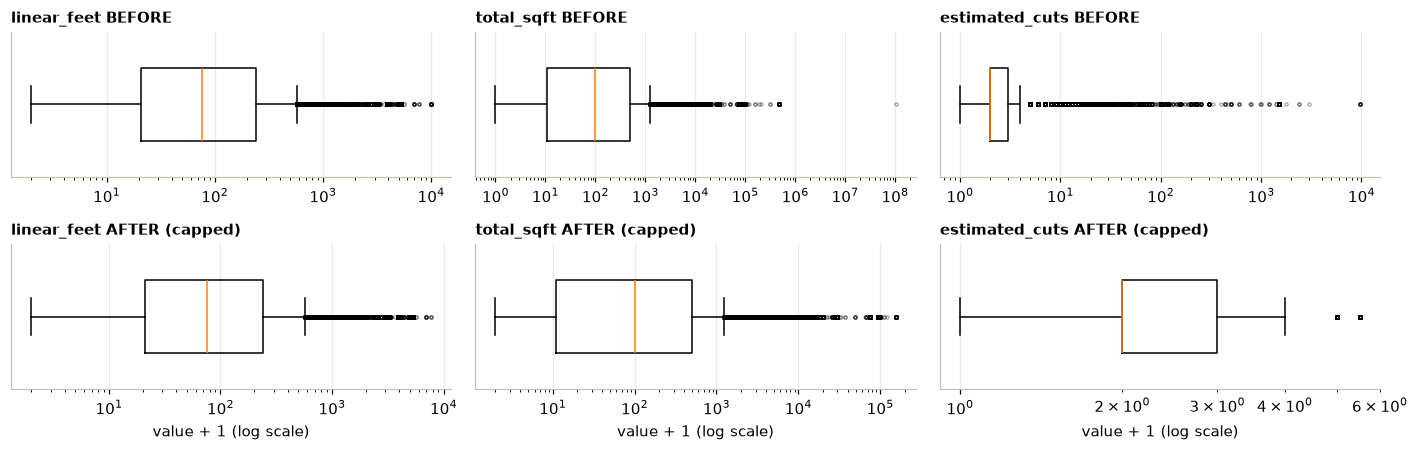

In [46]:
DOMAIN_RULES = {
    'estimated_cuts': lambda s: (s < 0) | (s > 1_000),
    'total_sqft':     lambda s: (s <= 0) | (s > 5_000_000),
    'linear_feet':    lambda s: (s <= 0) | (s == 9_999),
}
size_report = []
for col, rule in DOMAIN_RULES.items():
    impossible = rule(t3[col]) & t3[col].notna()
    t3.loc[impossible, col] = np.nan
    low, high = iqr_bounds(t3[col], log=True)
    t3[f'{col}_outlier'] = t3[col] > high
    t3[f'{col}_capped'] = t3[col].clip(upper=high)
    size_report.append({'column': col, 'impossible -> missing': int(impossible.sum()),
                        'IQR upper fence': round(high, 1), 'outliers capped': int(t3[f'{col}_outlier'].sum())})
display(pd.DataFrame(size_report))

RAW_NAME = {'linear_feet': 'permitlinearfeet', 'total_sqft': 'permittotalsqfeet', 'estimated_cuts': 'permitestimatednumberofcuts'}
fig, axes = plt.subplots(2, 3, figsize=(13, 4.2))
for i, col in enumerate(['linear_feet', 'total_sqft', 'estimated_cuts']):
    raw_v = t3_raw_sizes[RAW_NAME[col]].dropna()
    hbox(axes[0, i], raw_v.clip(lower=0) + 1)
    axes[0, i].set_xscale('log'); axes[0, i].set_title(f'{col} BEFORE', fontsize=10); axes[0, i].set_yticks([])
    hbox(axes[1, i], t3[f'{col}_capped'].dropna() + 1)
    axes[1, i].set_xscale('log'); axes[1, i].set_title(f'{col} AFTER (capped)', fontsize=10); axes[1, i].set_yticks([])
    axes[1, i].set_xlabel('value + 1 (log scale)')
plt.tight_layout(); plt.show()

### 8.8 Geometry → point → latitude/longitude
For each permit:
1. `shapely.from_wkt()` reads the WKT text into a real shape. Unreadable text becomes missing (`on_invalid='ignore'`).
2. `shapely.point_on_surface()` gives **one point that lies on the shape** (for a street line it is a point on that street). We prefer it over the centroid because the centroid of a curved street can fall off the street.
3. `shapely.length()` gives the length of the line in **feet** (`geom_length_ft`) — a useful size feature. Points have length 0.
4. `to_crs('EPSG:4326')` converts feet → latitude/longitude, so T3 can be drawn on the same web map as H6.
5. Points outside the NYC box are errors → removed.

In [47]:
wkt_array = np.array([v if isinstance(v, str) else None for v in t3['wkt']], dtype=object)  # shapely wants text or None
geoms = shapely.from_wkt(wkt_array, on_invalid='ignore')
unreadable = t3['wkt'].notna().to_numpy() & pd.isna(geoms)
geoms = np.where(pd.isna(geoms) | shapely.is_empty(geoms), None, geoms)
TYPE_NAMES = {-1: 'MISSING', 0: 'POINT', 1: 'LINESTRING', 2: 'LINEARRING', 3: 'POLYGON', 4: 'MULTIPOINT',
              5: 'MULTILINESTRING', 6: 'MULTIPOLYGON', 7: 'GEOMETRYCOLLECTION'}
t3['geom_type'] = pd.Series(shapely.get_type_id(geoms), index=t3.index).map(TYPE_NAMES).astype('category')
t3['geom_length_ft'] = np.where(pd.isna(geoms), np.nan, shapely.length(geoms))

points_ft = gpd.GeoSeries(shapely.point_on_surface(geoms), index=t3.index, crs=CRS_FEET)
points_ll = points_ft.to_crs(CRS_LATLON)
t3['longitude'] = points_ll.x
t3['latitude'] = points_ll.y
outside = t3['latitude'].notna() & ~(t3['latitude'].between(NYC_BBOX['lat_min'], NYC_BBOX['lat_max']) &
                                     t3['longitude'].between(NYC_BBOX['lon_min'], NYC_BBOX['lon_max']))
t3.loc[outside, ['latitude', 'longitude', 'geom_length_ft']] = np.nan
points_ft[outside] = None

print(f'Unreadable WKT: {unreadable.sum():,} | points outside NYC: {outside.sum():,}')
print(t3['geom_type'].value_counts().to_string())
print(f"Permits with a usable location: {t3['latitude'].notna().mean():.2%}")
t3 = t3.drop(columns='wkt')

Unreadable WKT: 0 | points outside NYC: 0
geom_type
LINESTRING         1917478
MISSING             331654
POINT               250047
MULTIPOINT           55657
MULTILINESTRING      20848
Permits with a usable location: 87.12%


### 8.9 Spatial join: which neighborhood is each permit in?
`gpd.sjoin(points, nta_polygons, predicate='within')` checks, for each point, which polygon contains it. It uses a spatial index (an "R-tree"), so millions of points take seconds, not hours.

Some street points lie exactly on a neighborhood border or on a waterfront road just outside every polygon. For those, `gpd.sjoin_nearest(..., max_distance=300)` takes the nearest NTA **within 300 feet** (≈ one short block). Farther points stay unmapped rather than being forced into a wrong neighborhood.

In [48]:
has_point = points_ft.notna()
pts = gpd.GeoDataFrame(index=t3.index[has_point], geometry=points_ft[has_point], crs=CRS_FEET)
inside = gpd.sjoin(pts, nta[['nta_code', 'geometry']], how='left', predicate='within')
inside = inside[~inside.index.duplicated(keep='first')]
t3['nta_code'] = pd.Series(index=t3.index, dtype=object)
t3.loc[inside.index, 'nta_code'] = inside['nta_code']
t3['nta_source'] = np.where(t3['nta_code'].notna(), 'GEOMETRY', None)

still = has_point & t3['nta_code'].isna()
if still.any():
    near = gpd.sjoin_nearest(pts.loc[still[still].index], nta[['nta_code', 'geometry']], how='left',
                             max_distance=300, distance_col='distance_ft')
    near = near[~near.index.duplicated(keep='first')].dropna(subset=['nta_code'])
    t3.loc[near.index, 'nta_code'] = near['nta_code']
    t3.loc[near.index, 'nta_source'] = 'GEOMETRY_NEAREST_300FT'
print(pd.Series(t3['nta_source']).value_counts(dropna=False).to_string())

nta_source
GEOMETRY                  2242535
NaN                        331700
GEOMETRY_NEAREST_300FT       1449


### 8.10 Missing locations — fill from the same street segment
About a fifth of permits have **no geometry**. Throwing them away would hide real street work. But many of them are on a street segment that **other** permits (with geometry) also used, e.g. *BROOKLYN · FULTON STREET · from NOSTRAND AVENUE · to BEDFORD AVENUE*.

**Rule:** copy the neighborhood from permits on the *same* segment, but only when the evidence is strong:

| Level | Same ... | Condition |
|---|---|---|
| L1 | borough + street + from-street + to-street | ≥ 90% of known permits agree, at least 2 permits |
| L2 | borough + street + from-street (one end of the segment) | ≥ 90% agree, at least 2 permits |
| L3 | borough + street | ≥ 90% agree, at least 5 permits (only short streets that lie in a single neighborhood) |

Permits that are still unknown get `nta_source = UNMAPPED`. They stay in the T3 table and in the **borough** totals, but cannot be counted in a neighborhood.

In [49]:
LEVELS = [('IMPUTED_SAME_SEGMENT', ['borough', 'on_street', 'from_street', 'to_street'], 0.9, 2),
          ('IMPUTED_SAME_SEGMENT_END', ['borough', 'on_street', 'from_street'], 0.9, 2),
          ('IMPUTED_SAME_STREET', ['borough', 'on_street'], 0.9, 5)]
geo_known = t3[t3['nta_source'].isin(['GEOMETRY', 'GEOMETRY_NEAREST_300FT'])]
for label, keys, min_share, min_count in LEVELS:
    need = t3['nta_code'].isna()
    if not need.any():
        break
    table = group_mode(geo_known, keys, 'nta_code', min_share=min_share, min_count=min_count)
    values = lookup_by_keys(t3.loc[need], table, keys).dropna()
    t3.loc[values.index, 'nta_code'] = values
    t3.loc[values.index, 'nta_source'] = label
    print(f'{label:<26} filled {len(values):>9,} permits')

t3['nta_source'] = pd.Series(t3['nta_source'], index=t3.index).fillna('UNMAPPED').astype('category')
nta_borough = t3['nta_code'].astype(object).str[:2].map(NTA_PREFIX_TO_BOROUGH)
conflict = nta_borough.notna() & (nta_borough != t3['borough'].astype(object))
print(f'Borough conflicts (NTA borough != permit borough) -> set to UNMAPPED: {conflict.sum():,}')
t3.loc[conflict, 'nta_code'] = np.nan
t3['nta_source'] = t3['nta_source'].astype(object).mask(conflict, 'UNMAPPED').astype('category')

t3['nta_code'] = t3['nta_code'].astype('category')
t3['nta_name'] = t3['nta_code'].astype(object).map(dict(zip(nta['nta_code'], nta['nta_name']))).astype('category')
t3['in_residential_nta'] = t3['nta_code'].astype(object).map(dict(zip(nta['nta_code'], nta['is_residential']))).fillna(False).astype(bool)
coverage = t3['nta_source'].value_counts(normalize=True).mul(100).round(2)
display(coverage.to_frame('% of permits'))

IMPUTED_SAME_SEGMENT       filled   260,709 permits


IMPUTED_SAME_SEGMENT_END   filled    45,790 permits


IMPUTED_SAME_STREET        filled     2,312 permits


Borough conflicts (NTA borough != permit borough) -> set to UNMAPPED: 2,616


,% of permits
nta_source,
GEOMETRY,86.99
IMPUTED_SAME_SEGMENT,10.11
IMPUTED_SAME_SEGMENT_END,1.77
UNMAPPED,0.99
IMPUTED_SAME_STREET,0.09
GEOMETRY_NEAREST_300FT,0.05


### 8.11 Feature engineering at row level

| Feature | How | Why it helps |
|---|---|---|
| calendar columns | from `issue_date` (same function as H6) | the month key and seasonal analysis |
| `is_new_job` | application type is NEW or EMERGENCY | counts jobs, not monthly renewals of the same job |
| `is_emergency_permit` | application type is EMERGENCY | urgent work (e.g. gas leaks, water main breaks) |
| `is_street_opening` | series = STREET OPENING PERMIT | the street was actually dug open |
| `work_kind` | rules on type + series (first match wins) → GAS, WATER_SEWER, STEAM, ELECTRIC_TELECOM, PAVING, STREET_RECONSTRUCTION, BUILDING_OPERATION (equipment/material/occupancy for building construction), REFUSE_CONTAINER, OCCUPANCY_EQUIPMENT (other occupancy), SIDEWALK_CURB, TREE, OTHER | matches H6's problem groups (gas work ↔ heat/gas complaints, water work ↔ water problems), and separates construction-related street use |
| `permittee_group` / `is_utility` | rules on permittee name → UTILITY (Con Edison, National Grid, Verizon ...), GOVERNMENT, PRIVATE_CONTRACTOR | who is digging |
| `street_key` | `normalize_street(on_street)` | street-level matching with H6 |

In [50]:
t3 = add_calendar_features(t3, 'issue_date')
app = t3['application_type'].astype(object)
t3['is_new_job'] = app.isin(['NEW', 'EMERGENCY'])
t3['is_emergency_permit'] = app.eq('EMERGENCY')
t3['is_street_opening'] = t3['permit_series'].astype(object).eq('STREET OPENING PERMIT')

KIND_RULES = [   # checked in this order, first match wins
    ('GAS',                   r'\bGAS\b'),
    ('WATER_SEWER',           r'WATER|SEWER|HYDRANT|CATCH BASIN'),
    ('STEAM',                 r'STEAM'),
    ('ELECTRIC_TELECOM',      r'ELECTRIC|CONDUIT|FIBER|TELEPHONE|TELECOM|CABLE|SIGNAL|STREET ?LIGHT|\bPOLE|MANHOLE|FRANCHISE'),
    ('PAVING',                r'PAVING|MILLING|RESURFAC|ASPHALT'),
    ('STREET_RECONSTRUCTION', r'RECONSTRUCT'),
    ('BUILDING_OPERATION',    r'BUILDING OPERATION'),
    ('REFUSE_CONTAINER',      r'REFUSE CONTAINER'),
    ('OCCUPANCY_EQUIPMENT',   r'OCCUPANCY|PLACE EQUIPMENT|PLACE MATERIAL|CRANE|PEDESTRIAN WALK|CROSSING SIDEWALK|CANOPY|FENCE|BARRIER|SHED|DEBRIS CONTAINER'),
    ('SIDEWALK_CURB',         r'SIDEWALK|CURB|PED RAMP|VAULT'),
    ('TREE',                  r'TREE'),
]
def assign_work_kind(series, ptype):
    text = ' | '.join(x for x in (ptype, series) if isinstance(x, str))   # type first, it is more specific
    for kind, pattern in KIND_RULES:
        if re.search(pattern, text):
            return kind
    return 'OTHER'

t3['work_kind'] = map_combinations(t3, ['permit_series', 'permit_type'], assign_work_kind)

PERMITTEE_RULES = [
    ('UTILITY', r'CONSOLIDATED EDISON|\bCON ?ED|NATIONAL GRID|BROOKLYN UNION GAS|KEYSPAN|VERIZON|EMPIRE CITY SUBWAY|SPECTRUM|'
                r'CHARTER COMM|ALTICE|CABLEVISION|LIGHTPATH|CROWN CASTLE|EXTENET|MOBILITIE|ZAYO|LIGHTOWER|AT&T|T-MOBILE|'
                r'CELLCO|POWER AUTHORITY|\bNYPA\b|CITYBRIDGE|LINKNYC'),
    ('GOVERNMENT', r'\bNYC\b|CITY OF NEW YORK|\bDEPT\b|DEPARTMENT|\bD\.?D\.?C\b|NYCHA|HOUSING AUTHORITY|\bMTA\b|TRANSIT|'
                   r'SCHOOL CONSTRUCTION|PARKS|ENVIRONMENTAL PROTECTION|PORT AUTHORITY'),
]
def permittee_group(name):
    if not isinstance(name, str):
        return 'UNKNOWN'
    for group, pattern in PERMITTEE_RULES:
        if re.search(pattern, name):
            return group
    return 'PRIVATE_CONTRACTOR'

t3['permittee_group'] = map_categories(t3['permittee'], permittee_group).astype(object).fillna('UNKNOWN').astype('category')
t3['is_utility'] = t3['permittee_group'].astype(object).eq('UTILITY')
t3['street_key'] = map_categories(t3['on_street'], normalize_street)

display(pd.crosstab(t3['work_kind'], t3['permittee_group']))

C:\Users\ziadk\AppData\Local\Temp\ipykernel_33888\3766880167.py:126: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['is_weekend'] = d.dt.dayofweek >= 5


permittee_group,GOVERNMENT,PRIVATE_CONTRACTOR,UTILITY
work_kind,,,
BUILDING_OPERATION,24585,939334,50446
ELECTRIC_TELECOM,51,65293,205208
GAS,0,47,210304
OCCUPANCY_EQUIPMENT,99,8261,20751
OTHER,198,11336,4915
PAVING,85925,35317,890
REFUSE_CONTAINER,324,297527,0
SIDEWALK_CURB,1357,167796,35903
STEAM,0,221,10296


### 8.12 Final T3 table: choose columns, check, compare

T3 clean: 2,575,684 rows x 51 columns | kept 99.92% of downloaded rows | located in a neighborhood: 99.01%


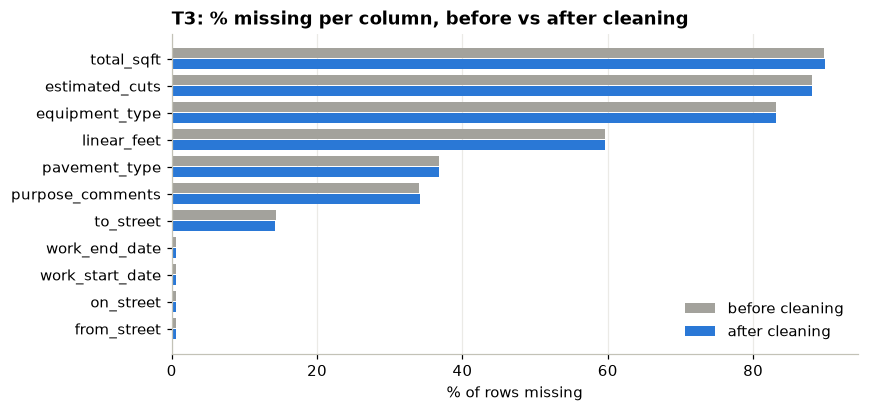

,dataset,step,rows_before,rows_after,rows_removed,note
0,H6,received_date inside window,3160386,3160386,0,
1,H6,exact duplicate rows,3160386,3160386,0,
2,H6,repeated problem_id (kept latest status),3160386,3160386,0,
3,H6,borough conflicts with NTA borough,3160386,3154092,6294,
4,H6,no neighborhood (NTA) could be found,3154092,3153693,399,
5,T3,voided permits,2577722,2575684,2038,
6,T3,issue_date inside window,2575684,2575684,0,
7,T3,valid borough,2575684,2575684,0,
8,T3,exact duplicate rows,2575684,2575684,0,
9,T3,repeated permit_number (kept latest),2575684,2575684,0,


,permit_number,issue_date,work_start_date,work_end_date,work_duration_days,work_duration_capped,work_duration_outlier,work_window_inconsistent,application_type,is_new_job,is_emergency_permit,permit_status,permit_series,permit_type,work_kind,is_street_opening,permittee,permittee_group,is_utility,equipment_type,pavement_type,purpose_comments,linear_feet,linear_feet_capped,linear_feet_outlier,total_sqft,total_sqft_capped,total_sqft_outlier,estimated_cuts,estimated_cuts_capped,estimated_cuts_outlier,borough,on_street,from_street,to_street,street_key,geom_type,geom_length_ft,latitude,longitude,nta_code,nta_name,nta_source,in_residential_nta,year,month,year_month,day_of_week,is_weekend,season,is_heat_season
0,B002022003A00,2022-01-03 08:43:30,NaT,NaT,NaN,NaN,False,False,EMERGENCY,True,True,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,OTHER,False,CONSOLIDATED EDISON,UTILITY,True,NaN,NaN,A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN,False,NaN,NaN,False,NaN,NaN,False,BROOKLYN,NaN,NaN,NaN,NaN,MISSING,NaN,NaN,NaN,NaN,NaN,UNMAPPED,False,2022,1,2022-01-01,Monday,False,WINTER,True
1,B002022003A01,2022-01-03 09:23:22,NaT,NaT,NaN,NaN,False,False,EMERGENCY,True,True,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,OTHER,False,CONSOLIDATED EDISON,UTILITY,True,NaN,NaN,A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN,False,NaN,NaN,False,NaN,NaN,False,BROOKLYN,NaN,NaN,NaN,NaN,MISSING,NaN,NaN,NaN,NaN,NaN,UNMAPPED,False,2022,1,2022-01-01,Monday,False,WINTER,True
2,B002022003A02,2022-01-03 11:50:17,NaT,NaT,NaN,NaN,False,False,EMERGENCY,True,True,ISSUED & PRINTED,MISCELLANEOUS CASH RECEIPTS,MISCELLANEOUS - EMBARGO WAIVER REQUEST,OTHER,False,"SUBSURFACE WATERMAIN & SEWER CONTRACTORS, INC.",PRIVATE_CONTRACTOR,False,NaN,NaN,A RECEIPT OF PAYMENT FOR A HOLIDAY EMBARGO WAIVER,NaN,NaN,False,NaN,NaN,False,NaN,NaN,False,BROOKLYN,NaN,NaN,NaN,NaN,MISSING,NaN,NaN,NaN,NaN,NaN,UNMAPPED,False,2022,1,2022-01-01,Monday,False,WINTER,True


In [51]:
T3_FINAL_COLUMNS = [
    'permit_number', 'issue_date', 'work_start_date', 'work_end_date', 'work_duration_days', 'work_duration_capped',
    'work_duration_outlier', 'work_window_inconsistent', 'application_type', 'is_new_job', 'is_emergency_permit',
    'permit_status', 'permit_series', 'permit_type', 'work_kind', 'is_street_opening', 'permittee', 'permittee_group',
    'is_utility', 'equipment_type', 'pavement_type', 'purpose_comments',
    'linear_feet', 'linear_feet_capped', 'linear_feet_outlier', 'total_sqft', 'total_sqft_capped', 'total_sqft_outlier',
    'estimated_cuts', 'estimated_cuts_capped', 'estimated_cuts_outlier',
    'borough', 'on_street', 'from_street', 'to_street', 'street_key', 'geom_type', 'geom_length_ft',
    'latitude', 'longitude', 'nta_code', 'nta_name', 'nta_source', 'in_residential_nta',
    'year', 'month', 'year_month', 'day_of_week', 'is_weekend', 'season', 'is_heat_season']
t3 = t3[T3_FINAL_COLUMNS].reset_index(drop=True)
t3['borough'] = t3['borough'].astype(object).astype('category')

assert t3['permit_number'].is_unique
assert t3['issue_date'].between(WINDOW_START, WINDOW_END).all()
assert t3['borough'].isin(BOROUGHS).all()
assert (t3['work_duration_days'].dropna() >= 0).all()
assert t3.loc[t3['nta_code'].notna(), 'nta_source'].ne('UNMAPPED').all()

t3_missing_after = missing_report(t3)
print(f'T3 clean: {len(t3):,} rows x {t3.shape[1]} columns | kept {len(t3) / T3_RAW_ROWS:.2%} of downloaded rows '
      f'| located in a neighborhood: {t3["nta_code"].notna().mean():.2%}')
plot_missing_before_after(t3_missing_before.rename(index=T3_RENAME), t3_missing_after,
                          'T3: % missing per column, before vs after cleaning')
display(pd.DataFrame(cleaning_log))
t3.head(3)

<a id="s9"></a>
## 9. Integration

### 9.1 Choosing the join key and the granularity (and why)
The datasets share **no ID**, so we cannot match row to row. We must choose a **common level** (granularity) and count both datasets at that level. We compared every option:

| Option | Possible? | Verdict |
|---|---|---|
| **Row-level join** (one complaint ↔ one permit) | No shared ID, no shared address field | ❌ meaningless — the project explicitly says not to force it |
| **Building / address** | T3 rows are street *segments*; `permithousenumber` is ~63% empty | ❌ too few matches |
| **Street name × month** | Both have street names | ⚠️ useful for "same street" questions (we build it as an **extra** table), but long streets cross many neighborhoods and names are noisy |
| **ZIP code** | H6 has ZIP, **T3 has none** | ❌ would need a ZIP boundary file; ZIPs are postal routes, not real neighborhoods |
| **Borough** | Both have it | ⚠️ only 5 units → far too coarse to find relationships (we keep a borough table for the website filter) |
| **NTA (neighborhood)** | H6 has the NTA name; T3 gets it from geometry | ✅ **chosen**: ~200 residential neighborhoods designed by NYC City Planning for statistics, stable 2020 boundaries, with a known area (for per-km² rates) |

| Time option | Verdict |
|---|---|
| Day | too sparse — most neighborhood-days have zero permits of a given kind |
| **Month** | ✅ **chosen**: smooths daily noise, shows seasons (heat in winter), allows "1–3 months later" lag features |
| Year | only 4 points per neighborhood → too few to see change |

**Final key: `nta_code` × `year_month`** (first day of the month). The main table has one row per residential neighborhood per month.

### 9.2 Why only residential neighborhoods?
NTAs of type ≠ 0 are parks, cemeteries, airports and similar areas. Almost nobody lives there, so housing complaints are structurally ~0, while street permits can be high (e.g. airport roads). Including them would add misleading "lots of street work, no complaints" points. Their permits are still kept in the T3 table and in the **borough** totals.

### 9.3 Build the empty grid first
We create **every** combination of residential neighborhood × month *before* joining. Why? If a neighborhood had zero permits in March, a simple count would just have **no row** for March. With the grid, that month exists and gets the value **0**, which is the truth. (A missing row would make averages and lag features wrong.)

In [52]:
months = pd.date_range(WINDOW_START.normalize(), WINDOW_END.normalize(), freq='MS')
residential_codes = set(nta_lookup.loc[nta_lookup['is_residential'], 'nta_code'])
grid = (nta_lookup.loc[nta_lookup['is_residential'], ['nta_code']]
        .merge(pd.DataFrame({'year_month': months}), how='cross'))
print(f'Grid: {grid["nta_code"].nunique()} residential NTAs x {len(months)} months = {len(grid):,} rows')

Grid: 197 residential NTAs x 48 months = 9,456 rows


### 9.4 Aggregate H6 to neighborhood × month
We first turn every useful row-level fact into a **0/1 indicator** (e.g. `is_violation`), then `groupby([...]).agg(...)` adds them up. This is fast and easy to read.

Counts we create:
* `h6_problems` — all reported problems (including HPD duplicate reports)
* `h6_unique_problems` — without duplicate reports
* `h6_complaints`, `h6_buildings` — number of **distinct** complaints / buildings (`nunique`)
* `h6_emergency_problems`, `h6_open_problems`
* `h6_violations`, `h6_no_violation`, `h6_no_access` — inspection results
* `h6_grp_<group>` — one column per problem group (heat, pests, mold, gas, water ...)
* `h6_median_days_to_close` — median of the **capped** closing time

In [53]:
PROBLEM_GROUPS = [g for g, _ in GROUP_RULES] + ['OTHER']
WORK_KINDS = [k for k, _ in KIND_RULES] + ['OTHER']
KEYS = ['nta_code', 'year_month']

h6_in = h6[h6['nta_code'].astype(object).isin(residential_codes)]
print(f'H6 problems in non-residential NTAs (excluded from the NTA table): {len(h6) - len(h6_in):,}')

h6_ind = pd.DataFrame({
    'nta_code': h6_in['nta_code'].astype(str), 'year_month': h6_in['year_month'],
    'problem_id': h6_in['problem_id'], 'complaint_id': h6_in['complaint_id'], 'building_id': h6_in['building_id'],
    'is_unique': ~h6_in['is_duplicate_report'], 'is_emergency': h6_in['is_emergency'], 'is_open': h6_in['is_open'],
    'is_violation': h6_in['inspection_outcome'].astype(object).eq('VIOLATION_ISSUED'),
    'is_no_violation': h6_in['inspection_outcome'].astype(object).eq('NO_VIOLATION'),
    'is_no_access': h6_in['inspection_outcome'].astype(object).eq('NO_ACCESS'),
    'days_to_close_capped': h6_in['days_to_close_capped'], 'problem_group': h6_in['problem_group'].astype(str)})

h6_agg = h6_ind.groupby(KEYS).agg(
    h6_problems=('problem_id', 'size'), h6_unique_problems=('is_unique', 'sum'),
    h6_complaints=('complaint_id', 'nunique'), h6_buildings=('building_id', 'nunique'),
    h6_emergency_problems=('is_emergency', 'sum'), h6_open_problems=('is_open', 'sum'),
    h6_violations=('is_violation', 'sum'), h6_no_violation=('is_no_violation', 'sum'),
    h6_no_access=('is_no_access', 'sum'), h6_median_days_to_close=('days_to_close_capped', 'median'))
h6_groups = (h6_ind.groupby(KEYS + ['problem_group']).size().unstack(fill_value=0)
                   .reindex(columns=PROBLEM_GROUPS, fill_value=0))
h6_groups.columns = [f'h6_grp_{g.lower()}' for g in h6_groups.columns]
h6_agg = h6_agg.join(h6_groups).reset_index()
print(f'H6 aggregated: {len(h6_agg):,} neighborhood-months with at least one problem')
h6_agg.head(3)

H6 problems in non-residential NTAs (excluded from the NTA table): 235


H6 aggregated: 9,451 neighborhood-months with at least one problem


,nta_code,year_month,h6_problems,h6_unique_problems,h6_complaints,h6_buildings,h6_emergency_problems,h6_open_problems,h6_violations,h6_no_violation,h6_no_access,h6_median_days_to_close,h6_grp_heat_hot_water,h6_grp_pests,h6_grp_mold,h6_grp_gas,h6_grp_water_plumbing,h6_grp_electric,h6_grp_structure,h6_grp_other
0,BK0101,2022-01-01,293,198,246,92,247,0,16,47,70,5.07,211,5,10,2,14,11,32,8
1,BK0101,2022-02-01,180,129,136,57,138,0,29,50,20,4.78,98,3,7,1,22,3,23,23
2,BK0101,2022-03-01,169,152,110,57,106,0,31,60,34,3.29,66,16,6,2,16,14,29,20


### 9.5 Aggregate T3 to neighborhood × month
Permits are counted in the month they were **issued**:
* `t3_permits` (all), `t3_new_jobs` (New + Emergency only, no renewals), `t3_emergency_permits`, `t3_utility_permits`, `t3_street_openings`
* `t3_kind_<kind>` — one column per kind of work (gas, water/sewer, paving ...)
* `t3_median_duration_days`, `t3_total_linear_feet` (capped values)

**Active permit-days.** A permit issued in January may keep the street busy until April. "Issued in January" misses that. So we also measure how many days of permitted work happen **inside each month**:

*Worked example:* a permit with work from **Jan 20 to Mar 10** gives **12 days** to January (20→31), **28 days** to February and **10 days** to March. We do this for every permit with a valid work window by "exploding" each permit into one row per month it covers (vectorized with NumPy, so it is fast), then summing per neighborhood-month:
* `t3_active_permit_days` — total days of permitted work in that month
* `t3_active_permits` — number of permits that were active at some point in that month

In [54]:
t3_in = t3[t3['in_residential_nta'] & t3['nta_code'].notna()]
print(f"T3 permits without a neighborhood: {t3['nta_code'].isna().sum():,} | in non-residential NTAs: "
      f"{(t3['nta_code'].notna() & ~t3['in_residential_nta']).sum():,}  (both excluded from the NTA table, kept for borough totals)")

t3_ind = pd.DataFrame({
    'nta_code': t3_in['nta_code'].astype(str), 'year_month': t3_in['year_month'],
    'permit_number': t3_in['permit_number'], 'is_new_job': t3_in['is_new_job'],
    'is_emergency_permit': t3_in['is_emergency_permit'], 'is_utility': t3_in['is_utility'],
    'is_street_opening': t3_in['is_street_opening'], 'work_duration_capped': t3_in['work_duration_capped'],
    'linear_feet_capped': t3_in['linear_feet_capped'], 'work_kind': t3_in['work_kind'].astype(str)})

t3_agg = t3_ind.groupby(KEYS).agg(
    t3_permits=('permit_number', 'size'), t3_new_jobs=('is_new_job', 'sum'),
    t3_emergency_permits=('is_emergency_permit', 'sum'), t3_utility_permits=('is_utility', 'sum'),
    t3_street_openings=('is_street_opening', 'sum'), t3_median_duration_days=('work_duration_capped', 'median'),
    t3_total_linear_feet=('linear_feet_capped', 'sum'))
t3_kinds = (t3_ind.groupby(KEYS + ['work_kind']).size().unstack(fill_value=0)
                  .reindex(columns=WORK_KINDS, fill_value=0))
t3_kinds.columns = [f't3_kind_{k.lower()}' for k in t3_kinds.columns]
t3_agg = t3_agg.join(t3_kinds).reset_index()


def active_days_by_month(df):
    # Split every permit's work window into the months it covers and count the days in each month.
    start = df['work_start_date'].clip(lower=WINDOW_START)
    end = pd.concat([df['work_end_date'], df['work_start_date'] + pd.Timedelta(days=MAX_WORK_DAYS)], axis=1).min(axis=1)
    end = end.clip(upper=WINDOW_END)
    ok = start.notna() & end.notna() & (end >= start) & ~df['work_window_inconsistent']
    s = start[ok].to_numpy(dtype='datetime64[ns]'); e = end[ok].to_numpy(dtype='datetime64[ns]')
    codes = df.loc[ok, 'nta_code'].astype(str).to_numpy()
    m0, m1 = s.astype('datetime64[M]'), e.astype('datetime64[M]')
    n_months = (m1 - m0).astype(int) + 1                       # months each permit touches
    row = np.repeat(np.arange(len(s)), n_months)               # repeat each permit once per month
    step = np.arange(n_months.sum()) - np.repeat(np.cumsum(n_months) - n_months, n_months)
    month_start = (m0[row] + step.astype('timedelta64[M]')).astype('datetime64[ns]')
    month_end = (m0[row] + (step + 1).astype('timedelta64[M]')).astype('datetime64[ns]')
    days = (np.minimum(e[row], month_end) - np.maximum(s[row], month_start)) / np.timedelta64(1, 'D')
    exploded = pd.DataFrame({'nta_code': codes[row], 'year_month': month_start, 'days': np.clip(days, 0, None)})
    return (exploded.groupby(KEYS).agg(t3_active_permit_days=('days', 'sum'), t3_active_permits=('days', 'size'))
                    .reset_index())

t3_active = active_days_by_month(t3_in)
print(f'T3 aggregated: {len(t3_agg):,} neighborhood-months with at least one issued permit; '
      f'{len(t3_active):,} with active work')
t3_agg.head(3)

T3 permits without a neighborhood: 25,505 | in non-residential NTAs: 42,132  (both excluded from the NTA table, kept for borough totals)


T3 aggregated: 9,456 neighborhood-months with at least one issued permit; 9,456 with active work


,nta_code,year_month,t3_permits,t3_new_jobs,t3_emergency_permits,t3_utility_permits,t3_street_openings,t3_median_duration_days,t3_total_linear_feet,t3_kind_gas,t3_kind_water_sewer,t3_kind_steam,t3_kind_electric_telecom,t3_kind_paving,t3_kind_street_reconstruction,t3_kind_building_operation,t3_kind_refuse_container,t3_kind_occupancy_equipment,t3_kind_sidewalk_curb,t3_kind_tree,t3_kind_other
0,BK0101,2022-01-01,348,151,8,46,71,51.00,"9,896.00",14,15,0,17,1,0,194,74,4,15,14,0
1,BK0101,2022-02-01,315,208,4,69,96,30.00,"12,931.00",20,14,0,24,2,0,130,73,10,20,22,0
2,BK0101,2022-03-01,553,266,5,104,108,58.53,"9,679.00",35,8,0,25,18,0,314,97,12,17,27,0


### 9.6 Join everything onto the grid
**Before joining we check that the key columns have the same type in every table** — a classic integration bug: if `year_month` is `datetime64[ns]` in one table and `datetime64[us]` (or text) in another, rows silently fail to match. We force the same types everywhere.

We use **left joins** onto the grid (keep every neighborhood-month, add data where it exists) and `validate='one_to_one'`, which makes pandas stop with an error if a key appears twice in either table (a duplicate key would multiply rows).

In [55]:
def standardize_keys(df):
    df = df.copy()
    df['nta_code'] = df['nta_code'].astype(str)
    df['year_month'] = pd.to_datetime(df['year_month']).astype('datetime64[ns]')
    return df

key_types = pd.DataFrame({name: tbl[KEYS].dtypes.astype(str) for name, tbl in
                          [('grid', grid), ('h6_agg', h6_agg), ('t3_agg', t3_agg), ('t3_active', t3_active)]})
print('Key dtypes BEFORE standardizing:'); display(key_types)
grid, h6_agg, t3_agg, t3_active = map(standardize_keys, (grid, h6_agg, t3_agg, t3_active))

integrated = (grid
              .merge(nta_lookup.drop(columns=['cdta_name']), on='nta_code', how='left', validate='many_to_one')
              .merge(h6_agg, on=KEYS, how='left', validate='one_to_one')
              .merge(t3_agg, on=KEYS, how='left', validate='one_to_one')
              .merge(t3_active, on=KEYS, how='left', validate='one_to_one'))
print(f'Integrated table: {integrated.shape[0]:,} rows x {integrated.shape[1]} columns')

# Conservation checks: nothing was lost or double-counted during the join
assert integrated['h6_problems'].sum() == len(h6_in), 'H6 counts changed during the join!'
assert integrated['t3_permits'].sum() == len(t3_in), 'T3 counts changed during the join!'
print('Conservation checks passed: every H6 problem and T3 permit is counted exactly once.')

Key dtypes BEFORE standardizing:


,grid,h6_agg,t3_agg,t3_active
nta_code,str,str,str,str
year_month,datetime64[us],datetime64[us],datetime64[us],datetime64[ns]


Integrated table: 9,456 rows x 47 columns
Conservation checks passed: every H6 problem and T3 permit is counted exactly once.


### 9.7 Extra table A — street × month
For "same street" questions (e.g. *gas work on GRAND CONCOURSE → no-heat complaints on GRAND CONCOURSE*). Both datasets were given a normalized `street_key`. We keep only streets that appear in **both** datasets (a street with no permits at all cannot answer a street-level question), build the full street × month grid, and fill months without events with 0.

In [56]:
def street_counts(df, prefix, flags):
    tmp = df[df['street_key'].notna()]
    tmp = pd.DataFrame({'borough': tmp['borough'].astype(str), 'street_key': tmp['street_key'].astype(str),
                        'year_month': tmp['year_month'], **{name: cond(tmp) for name, cond in flags.items()}})
    return tmp.groupby(['borough', 'street_key', 'year_month']).agg(
        **{f'{prefix}_{name}': (name, 'sum') for name in flags}).reset_index()

h6_street = street_counts(h6, 'h6', {
    'problems': lambda d: np.ones(len(d), dtype=int),
    'heat_hot_water': lambda d: d['problem_group'].astype(object).eq('HEAT_HOT_WATER'),
    'gas': lambda d: d['problem_group'].astype(object).eq('GAS'),
    'water_plumbing': lambda d: d['problem_group'].astype(object).eq('WATER_PLUMBING'),
    'pests': lambda d: d['problem_group'].astype(object).eq('PESTS')})
t3_street = street_counts(t3, 't3', {
    'permits': lambda d: np.ones(len(d), dtype=int),
    'street_openings': lambda d: d['is_street_opening'], 'emergency_permits': lambda d: d['is_emergency_permit'],
    'kind_gas': lambda d: d['work_kind'].astype(object).eq('GAS'),
    'kind_water_sewer': lambda d: d['work_kind'].astype(object).eq('WATER_SEWER'),
    'kind_paving': lambda d: d['work_kind'].astype(object).eq('PAVING')})

shared = (h6_street[['borough', 'street_key']].drop_duplicates()
          .merge(t3_street[['borough', 'street_key']].drop_duplicates(), how='inner'))
street_keys = ['borough', 'street_key', 'year_month']
street_month = (shared.merge(pd.DataFrame({'year_month': months.astype('datetime64[ns]')}), how='cross')
                .merge(h6_street.astype({'year_month': 'datetime64[ns]'}), on=street_keys, how='left')
                .merge(t3_street.astype({'year_month': 'datetime64[ns]'}), on=street_keys, how='left'))
count_cols = [c for c in street_month.columns if c.startswith(('h6_', 't3_'))]
street_month[count_cols] = street_month[count_cols].fillna(0).astype('int32')

h6_on_shared = h6_street.merge(shared, on=['borough', 'street_key'])['h6_problems'].sum()
t3_on_shared = t3_street.merge(shared, on=['borough', 'street_key'])['t3_permits'].sum()
print(f'Streets present in both datasets: {len(shared):,}')
print(f'H6 problems on a street that also has T3 permits: {h6_on_shared / max(h6_street["h6_problems"].sum(), 1):.1%}')
print(f'T3 permits on a street that also has H6 problems: {t3_on_shared / max(t3_street["t3_permits"].sum(), 1):.1%}')
print(f'Street x month table: {street_month.shape[0]:,} rows x {street_month.shape[1]} columns')

Streets present in both datasets: 5,702
H6 problems on a street that also has T3 permits: 97.4%
T3 permits on a street that also has H6 problems: 95.1%
Street x month table: 273,696 rows x 14 columns


### 9.8 Extra table B — borough × month
City-wide trends and the website's borough filter. Built from **all** cleaned rows (including permits that could not be placed in a neighborhood), so borough totals are complete.

In [57]:
h6_b = (h6.assign(borough=h6['borough'].astype(str))
          .groupby(['borough', 'year_month']).agg(h6_problems=('problem_id', 'size'),
                                                   h6_emergency_problems=('is_emergency', 'sum')).reset_index())
h6_b_groups = (h6.assign(borough=h6['borough'].astype(str), problem_group=h6['problem_group'].astype(str))
                 .groupby(['borough', 'year_month', 'problem_group']).size().unstack(fill_value=0)
                 .reindex(columns=PROBLEM_GROUPS, fill_value=0))
h6_b_groups.columns = [f'h6_grp_{g.lower()}' for g in h6_b_groups.columns]
t3_b = (t3.assign(borough=t3['borough'].astype(str))
          .groupby(['borough', 'year_month']).agg(t3_permits=('permit_number', 'size'), t3_new_jobs=('is_new_job', 'sum'),
                                                   t3_emergency_permits=('is_emergency_permit', 'sum')).reset_index())
t3_b_kinds = (t3.assign(borough=t3['borough'].astype(str), work_kind=t3['work_kind'].astype(str))
                .groupby(['borough', 'year_month', 'work_kind']).size().unstack(fill_value=0)
                .reindex(columns=WORK_KINDS, fill_value=0))
t3_b_kinds.columns = [f't3_kind_{k.lower()}' for k in t3_b_kinds.columns]

borough_month = (pd.DataFrame({'borough': BOROUGHS}).merge(pd.DataFrame({'year_month': months}), how='cross')
                 .merge(h6_b.merge(h6_b_groups.reset_index(), on=['borough', 'year_month']), on=['borough', 'year_month'], how='left')
                 .merge(t3_b.merge(t3_b_kinds.reset_index(), on=['borough', 'year_month']), on=['borough', 'year_month'], how='left'))
num = borough_month.columns.drop(['borough', 'year_month'])
borough_month[num] = borough_month[num].fillna(0).astype('int64')
assert borough_month['h6_problems'].sum() == len(h6) and borough_month['t3_permits'].sum() == len(t3)
print(f'Borough x month table: {borough_month.shape}')
borough_month.head()

Borough x month table: (240, 27)


,borough,year_month,h6_problems,h6_emergency_problems,h6_grp_heat_hot_water,h6_grp_pests,h6_grp_mold,h6_grp_gas,h6_grp_water_plumbing,h6_grp_electric,h6_grp_structure,h6_grp_other,t3_permits,t3_new_jobs,t3_emergency_permits,t3_kind_gas,t3_kind_water_sewer,t3_kind_steam,t3_kind_electric_telecom,t3_kind_paving,t3_kind_street_reconstruction,t3_kind_building_operation,t3_kind_refuse_container,t3_kind_occupancy_equipment,t3_kind_sidewalk_curb,t3_kind_tree,t3_kind_other
0,MANHATTAN,2022-01-01,22894,18289,14077,925,552,567,2059,693,2922,1099,11295,6445,319,694,199,202,1375,156,311,6040,1159,164,506,470,19
1,MANHATTAN,2022-02-01,14131,10440,6955,761,500,503,1603,565,2406,838,10777,6150,317,620,227,223,1586,133,124,5642,1125,189,415,482,11
2,MANHATTAN,2022-03-01,13526,9210,5708,970,493,508,1623,531,2638,1055,17401,6963,397,849,253,216,1896,370,619,10504,1350,225,549,563,7
3,MANHATTAN,2022-04-01,10770,7096,3903,923,467,386,1539,434,2223,895,12940,7332,361,707,241,218,1643,553,136,6559,1483,194,604,586,16
4,MANHATTAN,2022-05-01,8117,4503,1773,820,413,268,1288,461,2254,840,12723,7101,368,678,216,199,1874,482,181,6300,1498,195,528,563,9


### 9.9 What the integration adds (the "so what")
Neither dataset alone can answer any of these, but the integrated tables can:
* **Timing:** does street work (especially gas and water work) come *before* rises in heat, hot-water or water complaints? → lag features in the NTA table, or the street × month table.
* **Disruption load:** are neighborhoods with the most days of active street work also the ones with the most housing emergencies, *after* removing size and borough effects? → `*_per_km2`, `*_z_borough`.
* **Response and equity:** do neighborhoods with many unresolved housing problems (`h6_no_access_rate`, `h6_median_days_to_close`) get more or fewer city/utility works (`t3_utility_share`, `t3_kind_paving`)?
* **Seasonality:** heat complaints peak in winter, street work in warmer months — how do the two cycles overlap in each borough? → borough × month table.

These are directions, not finished research questions. Each team member still needs to write and test their own 2 questions.

<a id="s10"></a>
## 10. Post-integration cleaning (required)

Joining creates **new** problems that did not exist before. The project asks us to fix three kinds.

### 10.1 New missing values created by the joins
After a left join, a neighborhood-month with **no** complaints or permits gets `NaN` in the H6/T3 columns. We must decide what that `NaN` means:

| Column type | Example | NaN really means | Fix |
|---|---|---|---|
| **Counts / sums** | `h6_problems`, `t3_kind_gas`, `t3_active_permit_days` | "zero events happened" (both datasets record every event, so absence = none) | fill with **0** |
| **Medians** | `h6_median_days_to_close`, `t3_median_duration_days` | "there was nothing to measure" — the median of zero items does not exist | keep **NaN** (filling 0 would mean "closed instantly", which is false) |

Rates (shares) are created in Section 11 and are `NaN` when the denominator is 0, for the same reason.

In [58]:
missing_after_join = integrated.isna().sum()
display(missing_after_join[missing_after_join > 0].to_frame('NaN after joins').T)

MEDIAN_COLS = ['h6_median_days_to_close', 't3_median_duration_days']
COUNT_COLS = [c for c in integrated.columns if c.startswith(('h6_', 't3_')) and c not in MEDIAN_COLS]
integrated[COUNT_COLS] = integrated[COUNT_COLS].fillna(0)
remaining = integrated.isna().sum()
print('NaN left (expected only in the two median columns):')
print(remaining[remaining > 0].to_string())

,h6_problems,h6_unique_problems,h6_complaints,h6_buildings,h6_emergency_problems,h6_open_problems,h6_violations,h6_no_violation,h6_no_access,h6_median_days_to_close,h6_grp_heat_hot_water,h6_grp_pests,h6_grp_mold,h6_grp_gas,h6_grp_water_plumbing,h6_grp_electric,h6_grp_structure,h6_grp_other
NaN after joins,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5


NaN left (expected only in the two median columns):
h6_median_days_to_close    5


### 10.2 Inconsistent or redundant columns
We run four automatic checks:
1. **Constant columns** (only one value) carry no information. After keeping only residential NTAs, `nta_type` is always `0` and `is_residential` is always `True` → redundant, dropped.
2. **Duplicate columns** (two descriptive columns with identical values) → keep one.
3. Count columns that happen to be always 0 (a kind of work that never occurs) are **reported but kept**, so the table has the same columns every time the notebook runs — the website and the research notebooks can rely on them.
4. **Consistency:** the borough must agree with the NTA code prefix (`BX…` → BRONX), and every NTA has exactly one name.

In [59]:
is_measure = lambda c: c.startswith(('h6_', 't3_'))
descriptive_cols = [c for c in integrated.columns if not is_measure(c) and c not in KEYS]
constant_cols = [c for c in descriptive_cols if integrated[c].nunique(dropna=False) <= 1]
print('Constant descriptive columns (dropped):', constant_cols)
integrated = integrated.drop(columns=constant_cols)
descriptive_cols = [c for c in descriptive_cols if c not in constant_cols]

duplicate_pairs = [(a, b) for i, a in enumerate(descriptive_cols) for b in descriptive_cols[i + 1:]
                   if integrated[a].astype(object).equals(integrated[b].astype(object))]
print('Identical descriptive column pairs (second one dropped):', duplicate_pairs or 'none')
integrated = integrated.drop(columns=sorted({b for _, b in duplicate_pairs}))

# Measures: all-zero columns are reported but KEPT, so the table always has the same columns
# (a kind of work that never happens in our window is still a valid answer: 0).
all_zero = [c for c in integrated.columns if is_measure(c) and integrated[c].fillna(0).eq(0).all()]
print('Measure columns that are always 0 (kept for a stable schema):', all_zero or 'none')

prefix_borough = integrated['nta_code'].str[:2].map(NTA_PREFIX_TO_BOROUGH)
assert (prefix_borough == integrated['borough']).all(), 'borough disagrees with NTA code'
assert integrated.groupby('nta_code')['nta_name'].nunique().eq(1).all(), 'an NTA has more than one name'
print('Borough / NTA consistency: OK')

Constant descriptive columns (dropped): ['nta_type', 'is_residential']
Identical descriptive column pairs (second one dropped): none
Measure columns that are always 0 (kept for a stable schema): none
Borough / NTA consistency: OK


### 10.3 Data type mismatches
* After `fillna(0)`, count columns are still **floats** (`3.0`) because they once held `NaN` → convert to integers.
* `t3_active_permit_days` and `t3_total_linear_feet` are real measurements → keep as floats, rounded.
* Keys and labels → `category` (small and fast), `year_month` → datetime.

In [60]:
FLOAT_COLS = MEDIAN_COLS + ['t3_active_permit_days', 't3_total_linear_feet', 'area_km2']
INT_COLS = [c for c in integrated.columns if c.startswith(('h6_', 't3_')) and c not in FLOAT_COLS]
dtypes_before = integrated[INT_COLS[:4]].dtypes.astype(str).to_dict()
integrated[INT_COLS] = integrated[INT_COLS].round().astype('int32')
integrated[FLOAT_COLS] = integrated[FLOAT_COLS].astype('float64').round(2)
for col in ['nta_code', 'nta_name', 'borough', 'cdta_code']:
    integrated[col] = integrated[col].astype('category')
integrated['year_month'] = pd.to_datetime(integrated['year_month'])
print('Example dtypes before:', dtypes_before)
print('Example dtypes after :', integrated[INT_COLS[:4]].dtypes.astype(str).to_dict())

Example dtypes before: {'h6_problems': 'Int64', 'h6_unique_problems': 'float64', 'h6_complaints': 'float64', 'h6_buildings': 'float64'}
Example dtypes after : {'h6_problems': 'int32', 'h6_unique_problems': 'int32', 'h6_complaints': 'int32', 'h6_buildings': 'int32'}


### 10.4 Final validation of the integrated table

In [61]:
assert not integrated.duplicated(KEYS).any(), 'duplicate neighborhood-month rows'
assert len(integrated) == len(residential_codes) * len(months), 'grid is incomplete'
assert (integrated[INT_COLS] >= 0).all().all(), 'negative counts'
assert integrated['h6_problems'].sum() == len(h6_in) and integrated['t3_permits'].sum() == len(t3_in)
assert (integrated['h6_unique_problems'] <= integrated['h6_problems']).all()
assert (integrated['t3_new_jobs'] <= integrated['t3_permits']).all()
print('All post-integration checks passed ✔')
integrated[KEYS + ['nta_name', 'borough', 'h6_problems', 'h6_grp_heat_hot_water', 't3_permits', 't3_kind_gas',
                   't3_active_permit_days']].sort_values('h6_problems', ascending=False).head()

All post-integration checks passed ✔


,nta_code,year_month,nta_name,borough,h6_problems,h6_grp_heat_hot_water,t3_permits,t3_kind_gas,t3_active_permit_days
5603,MN1002,2024-12-01,Harlem (North),MANHATTAN,3622,2205,420,9,"12,412.41"
5615,MN1002,2025-12-01,Harlem (North),MANHATTAN,3615,2259,296,15,"10,309.21"
5604,MN1002,2025-01-01,Harlem (North),MANHATTAN,3367,2076,269,26,"10,188.98"
5614,MN1002,2025-11-01,Harlem (North),MANHATTAN,2937,1533,247,11,"11,418.54"
2904,BX0401,2024-01-01,Concourse-Concourse Village,BRONX,2917,1403,243,24,"14,290.82"


<a id="s11"></a>
## 11. Feature engineering on the integrated table

Raw counts have a big trap: **busy neighborhoods have more of everything** (more buildings, more people, more streets). If we compare raw counts we will always "discover" that places with many permits also have many complaints — a trivial result that the grading penalizes. The features below let the team compare **fairly**.

| Family | Columns | Why |
|---|---|---|
| **Density** | `*_per_km2` | removes the effect of neighborhood **size** |
| **Shares / rates** | `h6_heat_share`, `h6_violation_rate`, `h6_no_access_rate`, `t3_emergency_share`, `t3_utility_share`, `t3_new_job_share` | compares the **mix** of activity, not its volume |
| **Log transforms** | `log_*` = log(1 + x) | counts are very skewed; logs make scatter plots and correlations readable |
| **Lags** | `*_lag1`, `*_lag2`, `*_lag3` | the value 1–3 months **earlier** in the same neighborhood → "does street work come *before* complaints?" |
| **Rolling sums** | `*_roll3` | the last 3 months together → smoother signal |
| **Year-over-year change** | `*_yoy_change` | compares a month with the **same month last year**, removing the seasonal effect (heat complaints always rise in winter) |
| **Within-borough z-score** | `*_z_borough` | how unusual a neighborhood is **compared with its own borough in the same month** (0 = average, +2 = much higher) |
| **Calendar** | `year`, `month`, `quarter`, `season`, `is_heat_season`, `month_index` | time filters and seasonal comparisons |

**Leakage note:** lags and rolling sums are computed **inside each neighborhood** (`groupby('nta_code')`) after sorting by month, so a value never "leaks" from one neighborhood into another, and lags only use the **past**.

In [62]:
integrated = integrated.sort_values(KEYS).reset_index(drop=True)
area = integrated['area_km2']
new = {}   # collect every new column here, then add them all at once (faster than 100 single inserts)

def safe_ratio(numerator, denominator):
    # Division that returns NaN (not infinity) when the denominator is 0.
    return (numerator / denominator.where(denominator > 0)).astype('float64')

# --- density ---
for col in ['h6_problems', 'h6_unique_problems', 'h6_grp_heat_hot_water', 'h6_grp_pests', 't3_permits',
            't3_new_jobs', 't3_street_openings', 't3_active_permit_days']:
    new[f'{col}_per_km2'] = safe_ratio(integrated[col], area)

# --- shares / rates ---
new['h6_heat_share'] = safe_ratio(integrated['h6_grp_heat_hot_water'], integrated['h6_problems'])
new['h6_emergency_share'] = safe_ratio(integrated['h6_emergency_problems'], integrated['h6_problems'])
new['h6_violation_rate'] = safe_ratio(integrated['h6_violations'], integrated['h6_violations'] + integrated['h6_no_violation'])
new['h6_no_access_rate'] = safe_ratio(integrated['h6_no_access'], integrated['h6_problems'])
new['h6_problems_per_building'] = safe_ratio(integrated['h6_problems'], integrated['h6_buildings'])
new['t3_emergency_share'] = safe_ratio(integrated['t3_emergency_permits'], integrated['t3_permits'])
new['t3_utility_share'] = safe_ratio(integrated['t3_utility_permits'], integrated['t3_permits'])
new['t3_new_job_share'] = safe_ratio(integrated['t3_new_jobs'], integrated['t3_permits'])

# --- log transforms ---
for col in ['h6_problems', 'h6_grp_heat_hot_water', 't3_permits', 't3_active_permit_days',
            'h6_problems_per_km2', 't3_permits_per_km2']:
    base = integrated[col] if col in integrated.columns else new[col]
    new[f'log_{col}'] = np.log1p(base)

# --- lags, rolling sums and year-over-year change (inside each neighborhood, past only) ---
by_nta = integrated.groupby('nta_code', observed=True)
LAG_COLS = ['t3_permits', 't3_new_jobs', 't3_street_openings', 't3_emergency_permits', 't3_kind_gas',
            't3_kind_water_sewer', 't3_kind_paving', 't3_active_permit_days', 'h6_problems', 'h6_grp_heat_hot_water']
for col in LAG_COLS:
    for k in (1, 2, 3):
        new[f'{col}_lag{k}'] = by_nta[col].shift(k)
    new[f'{col}_roll3'] = by_nta[col].transform(lambda s: s.rolling(3, min_periods=1).sum())
for col in ['h6_problems', 'h6_grp_heat_hot_water', 't3_permits', 't3_new_jobs']:
    last_year = by_nta[col].shift(12)
    new[f'{col}_yoy_change'] = safe_ratio(integrated[col] - last_year, last_year)

# --- within-borough, same-month z-scores (on the log densities) ---
z_base = pd.DataFrame({'borough': integrated['borough'], 'year_month': integrated['year_month'],
                       'h6': new['log_h6_problems_per_km2'], 't3': new['log_t3_permits_per_km2']})
by_bm = z_base.groupby(['borough', 'year_month'], observed=True)
for short, name in [('h6', 'h6_problems_per_km2_z_borough'), ('t3', 't3_permits_per_km2_z_borough')]:
    new[name] = safe_ratio(z_base[short] - by_bm[short].transform('mean'), by_bm[short].transform('std'))

# --- calendar ---
ym = integrated['year_month']
new['year'] = ym.dt.year.astype('int16')
new['month'] = ym.dt.month.astype('int8')
new['quarter'] = ym.dt.quarter.astype('int8')
new['season'] = season_of(ym.dt.month).astype('category')
new['is_heat_season'] = ym.dt.month.isin([10, 11, 12, 1, 2, 3, 4, 5])
new['month_index'] = ((ym.dt.year - WINDOW_START.year) * 12 + ym.dt.month - WINDOW_START.month).astype('int16')

integrated = pd.concat([integrated, pd.DataFrame(new, index=integrated.index)], axis=1)
print(f'Integrated table now has {integrated.shape[0]:,} rows x {integrated.shape[1]} columns')
integrated.filter(regex='nta_name|year_month|per_km2$|share$|lag1$|yoy|z_borough').head(3)

Integrated table now has 9,456 rows x 119 columns


,year_month,nta_name,h6_problems_per_km2,h6_unique_problems_per_km2,h6_grp_heat_hot_water_per_km2,h6_grp_pests_per_km2,t3_permits_per_km2,t3_new_jobs_per_km2,t3_street_openings_per_km2,t3_active_permit_days_per_km2,h6_heat_share,h6_emergency_share,t3_emergency_share,t3_utility_share,t3_new_job_share,log_h6_problems_per_km2,log_t3_permits_per_km2,t3_permits_lag1,t3_new_jobs_lag1,t3_street_openings_lag1,t3_emergency_permits_lag1,t3_kind_gas_lag1,t3_kind_water_sewer_lag1,t3_kind_paving_lag1,t3_active_permit_days_lag1,h6_problems_lag1,h6_grp_heat_hot_water_lag1,h6_problems_yoy_change,h6_grp_heat_hot_water_yoy_change,t3_permits_yoy_change,t3_new_jobs_yoy_change,h6_problems_per_km2_z_borough,t3_permits_per_km2_z_borough
0,2022-01-01,Greenpoint,89.33,60.37,64.33,1.52,106.10,46.04,21.65,"1,222.01",0.72,0.84,0.02,0.13,0.43,4.50,4.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.71,0.73
1,2022-02-01,Greenpoint,54.88,39.33,29.88,0.91,96.04,63.41,29.27,"2,737.03",0.54,0.77,0.01,0.22,0.66,4.02,4.58,348.00,151.00,71.00,8.00,14.00,15.00,1.00,"4,008.19",293.00,211.00,NaN,NaN,NaN,NaN,-0.72,0.73
2,2022-03-01,Greenpoint,51.52,46.34,20.12,4.88,168.60,81.10,32.93,"5,142.70",0.39,0.63,0.01,0.19,0.48,3.96,5.13,315.00,208.00,96.00,4.00,20.00,14.00,2.00,"8,977.46",180.00,98.00,NaN,NaN,NaN,NaN,-0.69,0.68


**Note on missing values created by features (expected, not errors):**
* `*_lag1/2/3` are `NaN` in the first 1–3 months of the window (there is no earlier month), and `*_yoy_change` is `NaN` in the first 12 months.
* Shares and rates are `NaN` when the denominator is 0 (e.g. no permits that month → no "emergency share").
* We leave these as `NaN` on purpose. Plotting libraries and `corr()` skip `NaN`, while a fake 0 would bias the results.

<a id="s12"></a>
## 12. Validation visuals
These charts check that cleaning and integration worked. They are **not** research answers yet.

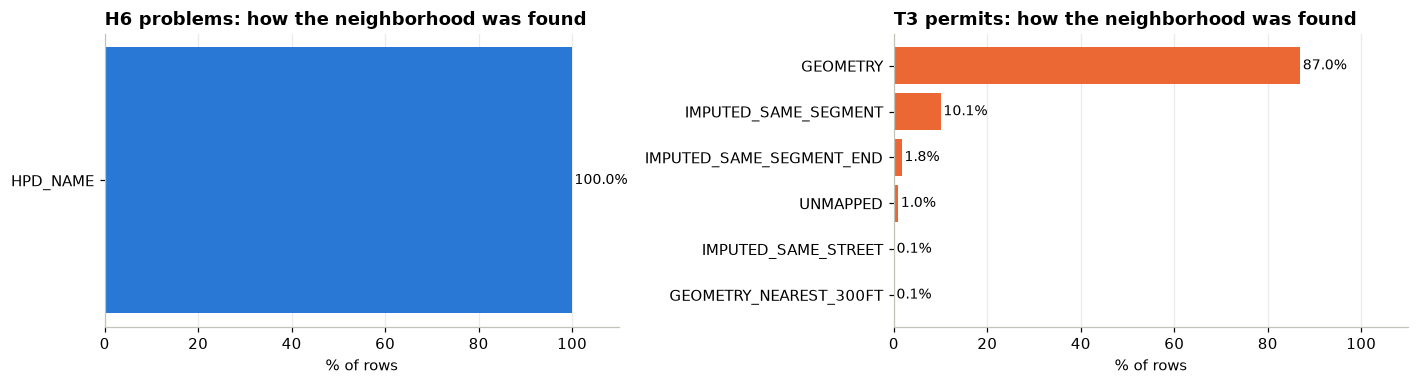

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (label, df, color) in zip(axes, [('H6 problems', h6, COLOR_H6), ('T3 permits', t3, COLOR_T3)]):
    share = df['nta_source'].value_counts(normalize=True).sort_values() * 100
    ax.barh(share.index.astype(str), share.values, color=color)
    for y, v in enumerate(share.values):
        ax.text(v + 0.5, y, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_title(f'{label}: how the neighborhood was found'); ax.set_xlabel('% of rows'); ax.grid(axis='y', visible=False)
    ax.set_xlim(0, 110)
plt.tight_layout(); plt.show()

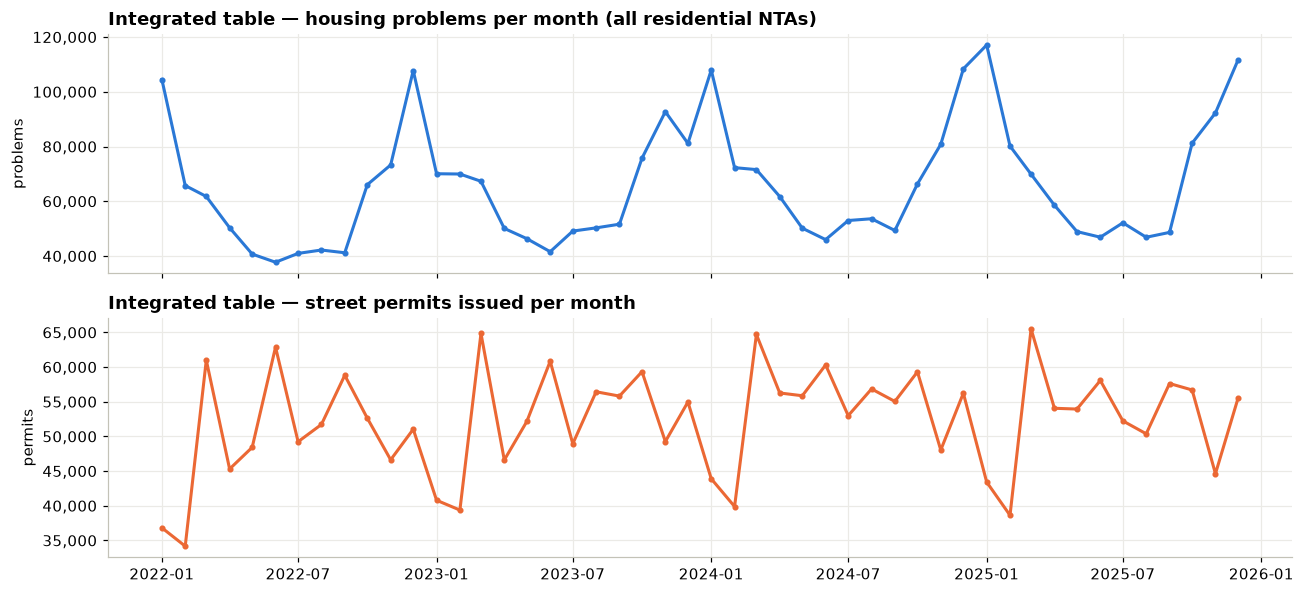

In [64]:
city = integrated.groupby('year_month')[['h6_problems', 't3_permits']].sum()
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(city.index, city['h6_problems'], color=COLOR_H6, marker='o', markersize=3)
style_ax(axes[0], 'Integrated table — housing problems per month (all residential NTAs)', ylabel='problems')
axes[1].plot(city.index, city['t3_permits'], color=COLOR_T3, marker='o', markersize=3)
style_ax(axes[1], 'Integrated table — street permits issued per month', ylabel='permits')
plt.tight_layout(); plt.show()

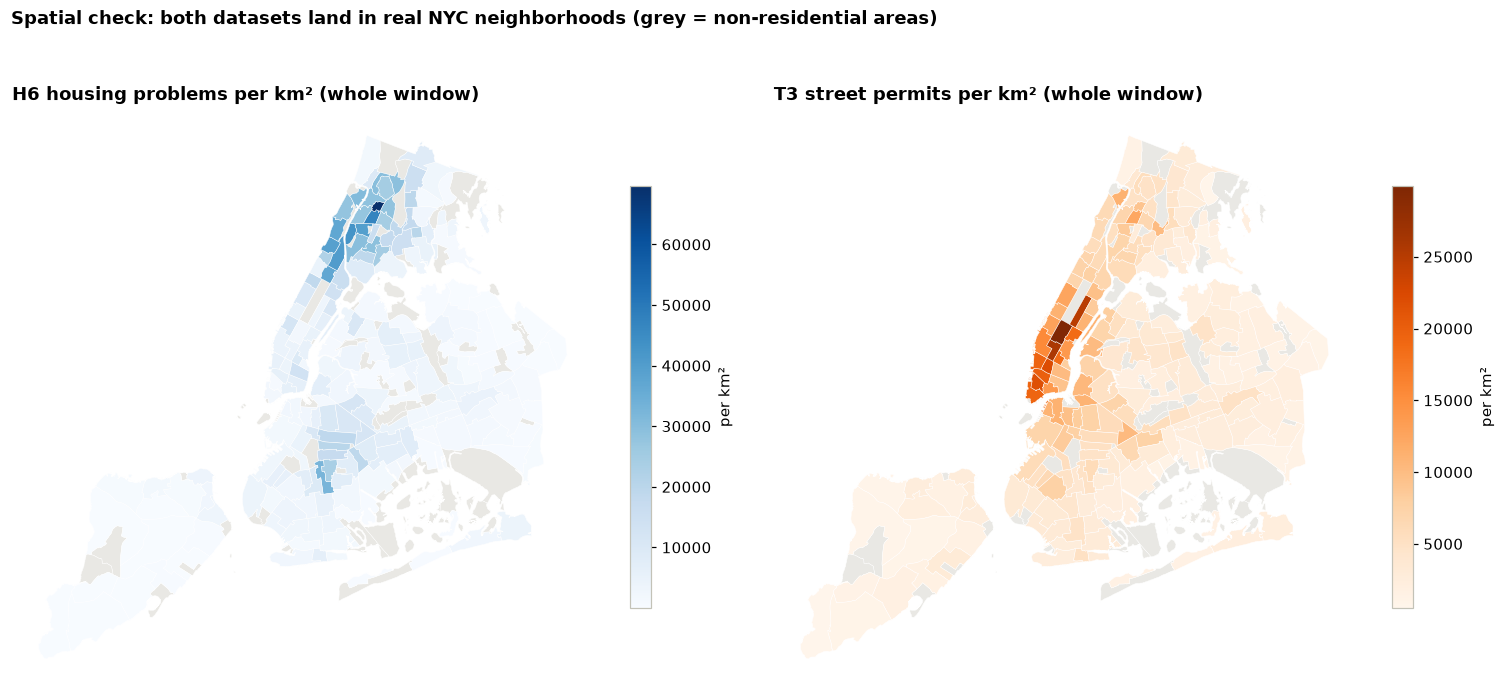

In [65]:
totals = integrated.groupby('nta_code', observed=True).agg(h6=('h6_problems', 'sum'), t3=('t3_permits', 'sum'),
                                                            area=('area_km2', 'first')).reset_index()
totals['nta_code'] = totals['nta_code'].astype(str)
totals['h6_per_km2'] = totals['h6'] / totals['area']
totals['t3_per_km2'] = totals['t3'] / totals['area']
map_df = nta.merge(totals, on='nta_code', how='left')

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, cmap, title in [(axes[0], 'h6_per_km2', 'Blues', 'H6 housing problems per km² (whole window)'),
                             (axes[1], 't3_per_km2', 'Oranges', 'T3 street permits per km² (whole window)')]:
    map_df[~map_df['is_residential']].plot(ax=ax, color='#e9e8e4', edgecolor='white', linewidth=0.3)
    map_df[map_df['is_residential']].plot(column=col, ax=ax, cmap=cmap, scheme=None, legend=True,
                                          edgecolor='white', linewidth=0.3,
                                          legend_kwds={'shrink': 0.6, 'label': 'per km²'})
    ax.set_title(title); ax.set_axis_off()
plt.suptitle('Spatial check: both datasets land in real NYC neighborhoods (grey = non-residential areas)',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

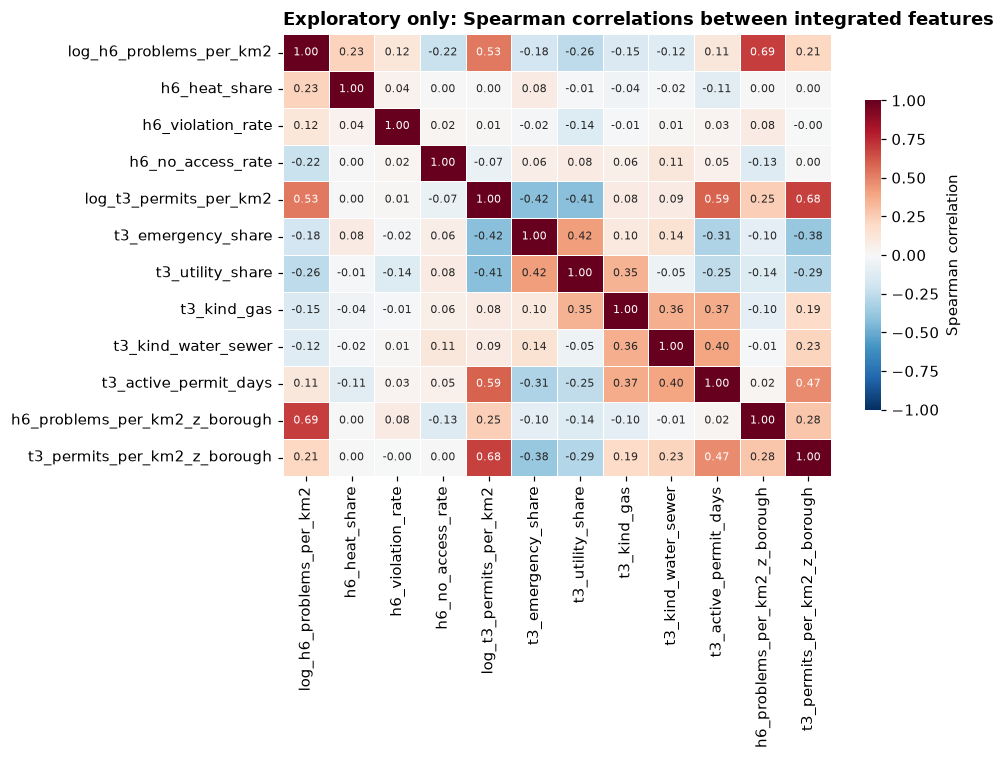

In [66]:
corr_cols = ['log_h6_problems_per_km2', 'h6_heat_share', 'h6_violation_rate', 'h6_no_access_rate',
             'log_t3_permits_per_km2', 't3_emergency_share', 't3_utility_share', 't3_kind_gas', 't3_kind_water_sewer',
             't3_active_permit_days', 'h6_problems_per_km2_z_borough', 't3_permits_per_km2_z_borough']
corr = integrated[corr_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7},
            linewidths=0.5, linecolor='white', cbar_kws={'shrink': 0.7, 'label': 'Spearman correlation'}, ax=ax)
ax.set_title('Exploratory only: Spearman correlations between integrated features')
plt.tight_layout(); plt.show()

**How to read these:**
* **Coverage bars:** almost all H6 rows are located by HPD's own NTA name; T3 rows mostly by geometry, plus segment-based filling. The `UNMAPPED` share is what we could not place.
* **Time series:** H6 should show the yearly winter heat peaks; T3 is usually busier in the warmer months. If either line suddenly drops to zero, a download page failed — re-run Section 3.
* **Maps:** both layers must fall inside NYC neighborhoods, with no strange empty boroughs.
* **Correlation heatmap:** Spearman correlation measures whether two features rise together (it works on ranks, so outliers matter less). It is only a **first look** and says nothing about cause. Research questions must go deeper (lags, z-scores, same-season comparisons).

<a id="s13"></a>
## 13. Saving the outputs + data dictionary

| File | Content | Used by |
|---|---|---|
| `data/processed/integrated_nta_month.parquet` / `.csv` | **main table**: one row per residential neighborhood per month | research questions, website |
| `data/processed/street_month.parquet` | extra table: street × month | street-level questions |
| `data/processed/borough_month.csv` | extra table: borough × month | city trends, website filter |
| `data/processed/h6_clean.parquet`, `t3_clean.parquet` | cleaned row-level data | detailed questions, website drill-downs |
| `data/processed/nta_lookup.csv`, `nta_boundaries.geojson` | neighborhood list + simplified shapes | website maps |
| `data/processed/data_dictionary.csv` | meaning of every column of the main table | everyone |
| `data/processed/cleaning_log.csv` | rows removed by each cleaning step | documentation |

**Parquet** keeps data types (dates stay dates, categories stay categories) and is much smaller and faster than CSV. We also save the main table as **CSV** so anyone can open it in Excel.

In [67]:
DESCRIPTIONS = {
    'nta_code': 'Neighborhood Tabulation Area 2020 code (e.g. BX0601) - join key part 1',
    'year_month': 'First day of the month - join key part 2',
    'nta_name': 'Neighborhood name', 'borough': 'Borough (from the NTA code)',
    'cdta_code': 'Community District Tabulation Area code', 'area_km2': 'Neighborhood land area in km²',
    'h6_problems': 'H6: all problems reported (incl. HPD duplicate reports)',
    'h6_unique_problems': 'H6: problems without HPD duplicate reports',
    'h6_complaints': 'H6: distinct complaints', 'h6_buildings': 'H6: distinct buildings with a complaint',
    'h6_emergency_problems': 'H6: problems classed EMERGENCY or IMMEDIATE EMERGENCY',
    'h6_open_problems': 'H6: problems still open', 'h6_violations': 'H6: inspections that issued a violation',
    'h6_no_violation': 'H6: inspections with no violation', 'h6_no_access': 'H6: inspector could not get access',
    'h6_median_days_to_close': 'H6: median days to close (capped); NaN if no closed problems',
    't3_permits': 'T3: permits issued (all application types)', 't3_new_jobs': 'T3: NEW + EMERGENCY permits (no renewals)',
    't3_emergency_permits': 'T3: EMERGENCY permits', 't3_utility_permits': 'T3: permits held by utility companies',
    't3_street_openings': 'T3: STREET OPENING permits (street dug open)',
    't3_median_duration_days': 'T3: median work window in days (capped); NaN if no permits',
    't3_total_linear_feet': 'T3: total permitted street length in feet (capped)',
    't3_active_permit_days': 'T3: days of permitted work falling inside this month (all permits)',
    't3_active_permits': 'T3: permits active at some point during this month',
    'h6_heat_share': 'H6: heat/hot-water problems / all problems', 'h6_emergency_share': 'H6: emergency problems / all problems',
    'h6_violation_rate': 'H6: violations / (violations + no violation)', 'h6_no_access_rate': 'H6: no-access results / all problems',
    'h6_problems_per_building': 'H6: problems per building with a complaint',
    't3_emergency_share': 'T3: emergency permits / all permits', 't3_utility_share': 'T3: utility permits / all permits',
    't3_new_job_share': 'T3: new jobs / all permits', 'year': 'Calendar year', 'month': 'Month number 1-12',
    'quarter': 'Quarter 1-4', 'season': 'WINTER/SPRING/SUMMER/FALL', 'is_heat_season': 'True for Oct-May (NYC heat season)',
    'month_index': 'Months since the start of the window (0 = first month)'}

def describe_column(col):
    if col in DESCRIPTIONS: return DESCRIPTIONS[col]
    m = re.match(r'h6_grp_(.+)', col)
    if m: return f'H6: problems in group {m.group(1).upper()}'
    m = re.match(r't3_kind_(.+)', col)
    if m: return f'T3: permits of work kind {m.group(1).upper()}'
    m = re.match(r'(.+)_lag(\d)$', col)
    if m: return f'{m.group(1)} in the same neighborhood {m.group(2)} month(s) earlier'
    m = re.match(r'(.+)_roll3$', col)
    if m: return f'{m.group(1)} summed over this and the previous 2 months'
    m = re.match(r'(.+)_yoy_change$', col)
    if m: return f'{m.group(1)}: relative change vs the same month one year earlier'
    m = re.match(r'(.+)_per_km2$', col)
    if m: return f'{m.group(1)} divided by neighborhood area (km²)'
    m = re.match(r'(.+)_z_borough$', col)
    if m: return f'{m.group(1)} (log density) z-score within the same borough and month'
    m = re.match(r'log_(.+)', col)
    if m: return f'log(1 + {m.group(1)})'
    return ''

data_dictionary = pd.DataFrame({
    'column': integrated.columns, 'dtype': integrated.dtypes.astype(str).values,
    'missing_%': (integrated.isna().mean() * 100).round(2).values,
    'example': [integrated[c].dropna().iloc[0] if integrated[c].notna().any() else None for c in integrated.columns],
    'description': [describe_column(c) for c in integrated.columns]})
undocumented = data_dictionary.loc[data_dictionary['description'] == '', 'column'].tolist()
print('Columns without a description:', undocumented or 'none')

integrated.to_parquet(PROCESSED_DIR / 'integrated_nta_month.parquet', index=False)
integrated.to_csv(PROCESSED_DIR / 'integrated_nta_month.csv', index=False)
street_month.to_parquet(PROCESSED_DIR / 'street_month.parquet', index=False)
borough_month.to_csv(PROCESSED_DIR / 'borough_month.csv', index=False)
h6.to_parquet(PROCESSED_DIR / 'h6_clean.parquet', index=False)
t3.to_parquet(PROCESSED_DIR / 't3_clean.parquet', index=False)
nta_lookup.to_csv(PROCESSED_DIR / 'nta_lookup.csv', index=False)
(nta.assign(geometry=nta.geometry.simplify(25)).to_crs(CRS_LATLON)
    [['nta_code', 'nta_name', 'borough', 'is_residential', 'area_km2', 'geometry']]
    .to_file(PROCESSED_DIR / 'nta_boundaries.geojson', driver='GeoJSON'))
data_dictionary.to_csv(PROCESSED_DIR / 'data_dictionary.csv', index=False)
pd.DataFrame(cleaning_log).to_csv(PROCESSED_DIR / 'cleaning_log.csv', index=False)

saved = pd.DataFrame([{'file': p.name, 'size_MB': round(p.stat().st_size / 1e6, 2)} for p in sorted(PROCESSED_DIR.iterdir())])
display(saved)
data_dictionary.head(40)

Columns without a description: none


,file,size_MB
0,borough_month.csv,0.03
1,cleaning_log.csv,0.00
2,data_dictionary.csv,0.01
3,h6_clean.parquet,155.17
4,integrated_nta_month.csv,8.64
5,integrated_nta_month.parquet,3.00
6,nta_boundaries.geojson,0.85
7,nta_lookup.csv,0.03
8,street_month.parquet,1.38
9,t3_clean.parquet,105.75


,column,dtype,missing_%,example,description
0,nta_code,category,0.00,BK0101,Neighborhood Tabulation Area 2020 code (e.g. B...
1,year_month,datetime64[ns],0.00,2022-01-01 00:00:00,First day of the month - join key part 2
2,nta_name,category,0.00,Greenpoint,Neighborhood name
3,borough,category,0.00,BROOKLYN,Borough (from the NTA code)
4,cdta_code,category,0.00,BK01,Community District Tabulation Area code
5,area_km2,float64,0.00,3.28,Neighborhood land area in km²
6,h6_problems,int32,0.00,293,H6: all problems reported (incl. HPD duplicate...
7,h6_unique_problems,int32,0.00,198,H6: problems without HPD duplicate reports
8,h6_complaints,int32,0.00,246,H6: distinct complaints
9,h6_buildings,int32,0.00,92,H6: distinct buildings with a complaint


<a id="s14"></a>
## 14. Requirements checklist (self-review)

We re-read the Milestone 1 description and checked every requirement against this notebook. The cell after the table re-runs automatic checks on the outputs.

| # | Requirement (project description) | Where | Status |
|---|---|---|---|
| 1 | Exactly one housing + one transportation dataset from NYC Open Data | H6 (Housing & Development), T3 (Transportation) — Sections 3–4 | ✅ |
| 2 | Each dataset ≥ 9 columns | H6: 26 downloaded (of 33); T3: 20 downloaded (of 39) — Section 4 | ✅ |
| 3 | At least one meaningful integration attribute | time (dates → month) + geography (NTA via name / geometry), plus borough and street | ✅ |
| 4 | Large dataset → filtered download, justified | full date window 2022–2025, column pruning, paging — Sections 1.2 & 3 | ✅ |
| 5 | Dataset overview: rows, columns, geo/time attributes, known issues, reasons | Section 4 (computed table + 4.1–4.3) | ✅ |
| 6 | Explain aggregation for different sizes/granularities | Sections 4.3 and 9.1 | ✅ |
| 7 | EDA with descriptive statistics and plots | Sections 5 and 6 | ✅ |
| 8 | Missing values handled, drop vs impute justified | 7.8 (decision table), 8.10, 10.1 | ✅ |
| 9 | Outliers detected and handled (IQR / domain rules) | 7.10, 8.6, 8.7 (log-IQR + domain rules + winsorizing, before/after box plots) | ✅ |
| 10 | Inconsistent data checked | 7.3, 7.6, 7.9 (borough vs NTA), 8.2 (typos), 8.6 (end before start), 10.2 | ✅ |
| 11 | Standardize formats (dates, strings, categories, geography) | 7.2–7.4, 8.2–8.3, NTA codes, street keys, lat/long from feet | ✅ |
| 12 | Remove duplicates | 7.7, 8.5 | ✅ |
| 13 | Integration documented; join key + granularity justified | Section 9.1–9.6 | ✅ |
| 14 | Post-integration: new missing values | 10.1 | ✅ |
| 15 | Post-integration: inconsistent / redundant columns | 10.2 | ✅ |
| 16 | Post-integration: data type mismatches | 9.6 (key types) and 10.3 | ✅ |
| 17 | Visualizations validating cleaning steps | missing before/after, box plots, coverage bars, time series, maps | ✅ |
| 18 | Descriptive markdown: decisions, alternatives considered | every section (e.g. 9.1 compares all join options) | ✅ |
| 19 | Clean code: descriptive names, modular functions, comments | Section 2 helpers, comments on complex logic (spatial join, active days, imputation) | ✅ |
| 20 | Prompts used + dataset links | Section 16 | ✅ |
| 21 | Team contribution documentation | table at the top — **the team must fill it in** | ⏳ to do |
| 22 | 2 research questions + 2 charts per member (12 total) | next step — use `integrated_nta_month` (+ street / borough tables) | ⏳ next step |
| 23 | Website (dropdowns, search, Generate Report, cross-domain chart, story, deployment), README, GitHub | next step — use the saved files | ⏳ next step |

In [68]:
checks = {
    'H6 has >= 9 columns': H6_RAW_COLS >= 9,
    'T3 has >= 9 columns': T3_RAW_COLS >= 9,
    'no missing join keys in integrated table': integrated[KEYS].notna().all().all(),
    'one row per neighborhood-month': not integrated.duplicated(KEYS).any(),
    'H6 counts conserved in join': int(integrated['h6_problems'].sum()) == len(h6_in),
    'T3 counts conserved in join': int(integrated['t3_permits'].sum()) == len(t3_in),
    'no duplicate H6 problem_id': h6['problem_id'].is_unique,
    'no duplicate T3 permit_number': t3['permit_number'].is_unique,
    'count columns have no NaN': integrated[INT_COLS].notna().all().all(),
    'every main-table column documented': len(undocumented) == 0,
    'all output files saved': all((PROCESSED_DIR / f).exists() for f in [
        'integrated_nta_month.parquet', 'integrated_nta_month.csv', 'street_month.parquet', 'borough_month.csv',
        'h6_clean.parquet', 't3_clean.parquet', 'nta_lookup.csv', 'nta_boundaries.geojson', 'data_dictionary.csv',
        'cleaning_log.csv']),
}
result = pd.Series(checks, name='passed')
display(result.to_frame())
assert result.all(), 'Some checks failed - see the table above'
print('All automatic requirement checks passed ✔')

,passed
H6 has >= 9 columns,True
T3 has >= 9 columns,True
no missing join keys in integrated table,True
one row per neighborhood-month,True
H6 counts conserved in join,True
T3 counts conserved in join,True
no duplicate H6 problem_id,True
no duplicate T3 permit_number,True
count columns have no NaN,True
every main-table column documented,True


All automatic requirement checks passed ✔


<a id="s15"></a>
## 15. Assumptions & limitations (be honest in the story too)

**Assumptions we made**
1. A building does not move → its ZIP, coordinates and NTA can be copied between its complaints.
2. A permit's neighborhood is where the point on its geometry falls; long street segments that cross two neighborhoods are assigned to one of them.
3. Permits without geometry are placed only when ≥ 90% of permits on the same segment/street agree.
4. `linear_feet = 9,999` is a placeholder for "unknown/maximum". Work windows longer than 366 days are capped.
5. "Absence = zero": a neighborhood-month with no records had zero complaints/permits (both datasets log every event they receive).

**Limitations**
1. **Complaints ≠ problems.** H6 measures what tenants *report*. Areas where tenants complain less (fear of landlords, language barriers) look "better" than they are.
2. **Permits ≠ work.** A permit allows work; it does not prove the work happened on those exact days.
3. **Edge of the window.** Permits issued *before* 2022 are not in T3, so active permit-days are slightly **under-counted in the first months of 2022**. Consider skipping Jan–Mar 2022 when using `t3_active_permit_days`.
4. **No population data.** Densities use land area. Per-person rates would need census population (could be added from the NTA population dataset).
5. **Correlation is not causation.** Busy neighborhoods have more of everything; use the z-scores, shares, lags and year-over-year features, and never claim one dataset *causes* the other without strong evidence.
6. Some H6 duplicates are real repeated reports; we kept them and provided both counts (`h6_problems`, `h6_unique_problems`).

<a id="s16"></a>
## 16. Prompts used & dataset links (required deliverable)

### Dataset links
* H6 — Housing Maintenance Code Complaints and Problems: https://data.cityofnewyork.us/d/ygpa-z7cr (API: `https://data.cityofnewyork.us/resource/ygpa-z7cr.csv`)
* T3 — Street Construction Permits (2022 – Present): https://data.cityofnewyork.us/d/tqtj-sjs8 (API: `https://data.cityofnewyork.us/resource/tqtj-sjs8.csv`)
* Helper — 2020 Neighborhood Tabulation Areas: https://data.cityofnewyork.us/d/9nt8-h7nd

### Prompts used
| Step | Tool | Prompt |
|---|---|---|
| Choosing datasets | Claude (Anthropic) | Asked to explain the project, compare catalog datasets, and inspect H3, T3 and H6 before the team chose H6 + T3. |
| This notebook (download, EDA, cleaning, integration, feature engineering) | Claude (Anthropic) | *"Look at those 2 project files, and know that I have chosen the T3 and H6 datasets to work on together, and we are 6 members in the team each of us needs to work on finding 2 different research question and their way of visualization but to start working we need to download the datasets or a sample as stated in the project description, and clean them then integrate them properly and applying all feature engineering principles to achieve the high quality dataset to start the real work, what I want from you is to create for me a single jupyter notebook that do all this processing and cleaning with a detailed markdown that explains every choice you made to make me understand, and state properly the usage of every single action or method to help me and my team get everything correctly, after finishing this process, I want you to review and double check after yourself to make sure that we match the requirements of the project before starting the research question finding."* |
| *(add every later prompt here: research questions, charts, website …)* | | |

<a id="s17"></a>
## 17. Appendix — glossary of every method used

| Method | What it does | Where we used it |
|---|---|---|
| `requests.get(url, params=...)` | sends an HTTP request to the API | downloading pages |
| `pd.read_csv(io.StringIO(text), dtype=...)` | turns CSV text into a DataFrame; `dtype=str` keeps codes as text | `parse_page` |
| `df.to_parquet()` / `pd.read_parquet()` | save / load a fast, typed file | caching, outputs |
| `union_categoricals(...)` | stacks category columns without converting them to text | `load_cached` |
| `df.shape`, `df.dtypes`, `df.head()` | size, types, first rows | EDA |
| `df.isna().sum()` / `.mean()` | number / share of missing values per column | `missing_report` |
| `s.value_counts()` | how often each value appears | EDA, checks |
| `s.nunique()` | number of distinct values | EDA, aggregation |
| `s.describe(percentiles=...)` | count, mean, std, min, quartiles, max | EDA |
| `s.astype('category')` | stores repeated text as small integer codes + a list of labels | memory, speed |
| `pd.Categorical.from_codes()` | rebuilds a category column from codes | `map_categories` |
| `str.strip()`, `str.upper()`, `re.sub()` | trim spaces, upper case, regex replace | text cleaning |
| `re.search(pattern, text)` | does the text contain the pattern? (`\b` = word boundary) | problem groups, work kinds |
| `pd.to_datetime(..., format='ISO8601', errors='coerce')` | text → dates; bad dates → `NaT` | type conversion |
| `pd.to_numeric(..., errors='coerce')` | text → numbers; bad numbers → `NaN` | type conversion |
| `s.between(a, b)` | True if a ≤ value ≤ b | window, coordinate box |
| `s.mask(condition)` | replaces values where condition is True with `NaN` | invalid values |
| `s.str.fullmatch(regex)` | the whole value must match the pattern | ZIP and BBL validation |
| `df.drop_duplicates(subset=..., keep=...)` | removes repeated rows | duplicates |
| `df.sort_values(...)` | sorts rows | keep latest record, lags |
| `df.groupby(keys).agg(name=(col, func))` | one row per group with named summaries (`size`, `sum`, `nunique`, `median`) | aggregation |
| `groupby(...).size().unstack(fill_value=0)` | counts per group spread into columns | per-group count columns |
| `groupby(...).transform(...)` | group result copied back to every row of the group | z-scores, rolling sums |
| `groupby(...).shift(k)` | value from k rows earlier **inside each group** | lag features |
| `s.rolling(3, min_periods=1).sum()` | moving sum over 3 rows | rolling features |
| `s.clip(lower=, upper=)` | caps values at limits (winsorizing) | outliers |
| `np.log1p(x)` / `np.expm1(x)` | log(1+x) and its inverse | skewed data, log-IQR |
| `np.repeat`, `np.where`, `np.minimum/maximum` | vectorized array operations | active permit-days |
| `df.merge(other, on=..., how='left', validate=...)` | SQL-style join; `validate` stops on duplicate keys | integration |
| `df.merge(other, how='cross')` | every combination of rows (grid) | neighborhood × month grid |
| `pd.date_range(start, end, freq='MS')` | list of month starts | grid |
| `dt.to_period('M').dt.to_timestamp()` | date → first day of its month | `year_month` |
| `shapely.from_wkt()` | WKT text → geometry | T3 geometry |
| `shapely.point_on_surface()` | a point guaranteed to lie on the shape | T3 location |
| `shapely.length()` | length of a line (in feet for EPSG:2263) | `geom_length_ft` |
| `gpd.points_from_xy(lon, lat)` | coordinates → point geometries | H6 backup location |
| `GeoSeries.to_crs(...)` | converts coordinates between systems (feet ↔ lat/long) | both |
| `gpd.sjoin(points, polygons, predicate='within')` | spatial join: which polygon contains each point | NTA mapping |
| `gpd.sjoin_nearest(..., max_distance=300)` | nearest polygon within a distance | border/waterfront points |
| `GeoDataFrame.plot(column=..., cmap=...)` | choropleth map | validation maps |
| `df.corr(method='spearman')` | rank correlation between columns | exploratory heatmap |
| `assert condition, message` | stops the notebook if a check fails | every validation step |